# Single-cell VAE → Z space → PCA

커널: **scrna**. 아래 셀을 순서대로 실행합니다.

1. 전체 데이터를 불러와 `normalize_total(target_sum=1e4)`와 `log1p`를 적용합니다.
2. **전체 세포**에서 `sample_id`를 batch로 고려해 HVG 2,000개를 선정하고 시각화합니다.
3. 그 **이후** `subtype`이 **CD4 Naive T**, **Regulatory T**인 세포만 남깁니다. HVG를 다시 선정하지 않습니다.
4. 세포를 샘플, 선정된 유전자를 특성으로 VAE를 학습합니다. 세포별 posterior mean을 **Z space**로 정의합니다.
5. **새로 학습한 Z space**에 PCA를 적용하고, 2차원 점의 색을 `adata.obs['subtype']`으로 지정합니다.

아래 VAE·PCA 결과에 이어, PCA 공간의 subtype별 median 좌표를 latent로 복원한 **가상 좌표**를 시작·목표로 하고, 한 번에 `2D/500` 이하만 이동하는 latent 방향 action DQN(최대 500 action, 목표 도착 또는 거리 개선 수렴 시 종료)을 실행합니다. 상태는 실제 세포가 아닌 action으로 생성되는 16차원 Z 좌표이며, PCA 경로·영상·주변 세포에서 추정한 TF 발현을 함께 제공합니다. 원본 h5ad 파일은 변경하지 않습니다.

**해석:** 이 VAE는 log-normalized expression을 재구성하는 비지도 Gaussian reconstruction beta-VAE입니다. Subtype을 VAE 입력이나 loss에 넣어 인위적으로 분리하지 않으므로 두 집단의 분리가 보장되지는 않습니다. Batch-aware HVG 선정은 batch correction 자체가 아니며, 시각화만으로 실제 분화나 인과관계를 증명할 수는 없습니다.


In [23]:
from pathlib import Path
from copy import deepcopy
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

DATA_PATH = Path('/home/Data_Drive_8TB/kykim/8. RL/tdata_sub.h5ad')
SUBTYPES = ['CD4 Naive T', 'Regulatory T']
SEED = 42
N_HVG, LATENT_DIM = 2000, 16
EPOCHS, PATIENCE, BATCH_SIZE = 120, 18, 256
LEARNING_RATE, BETA, KL_WARMUP_EPOCHS = 1e-3, 0.01, 20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Python: {sys.executable}\nDevice: {DEVICE}')


Python: /home/Data_Drive_8TB/kykim/.conda/envs/scrna/bin/python
Device: cuda


## 1. 전체 데이터 정규화 + batch-aware HVG 선정

이 단계에서는 subtype으로 세포를 필터링하지 않습니다. 입력 X의 실제 값이 유한한 비음수 정수 count인지 확인합니다. 이 파일에는 과거 `uns['log1p']` 메타데이터가 있을 수 있으므로, count 확인 후 작업 사본의 해당 메타데이터만 제거하고 요청한 순서로 처리합니다.


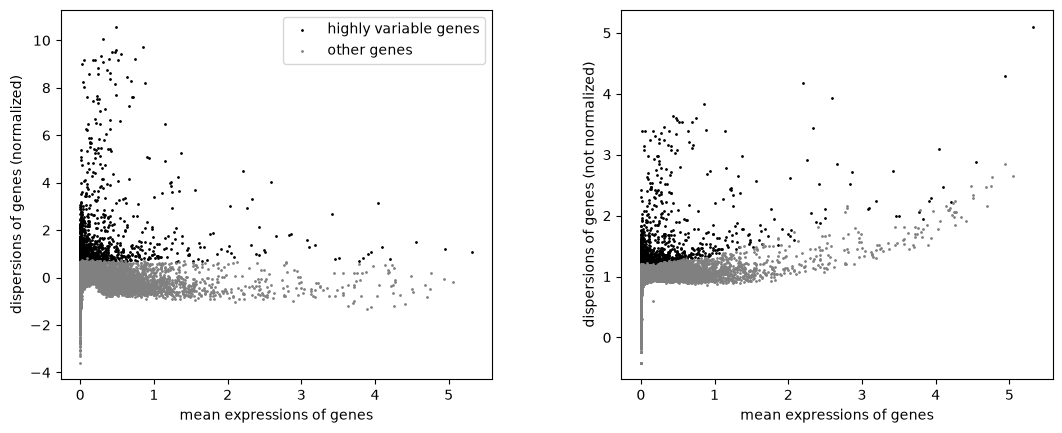

In [24]:
adata = sc.read_h5ad(DATA_PATH)
for column in ('subtype', 'sample_id'):
    if column not in adata.obs:
        raise KeyError(f'Missing required obs column: {column}')
    if adata.obs[column].isna().any():
        raise ValueError(f'obs[{column!r}] contains missing values.')
if not adata.obs_names.is_unique:
    raise ValueError('Cell barcodes must be unique.')
if adata.n_vars < N_HVG:
    raise ValueError(f'At least {N_HVG} input genes are required.')
values = adata.X.data if sparse.issparse(adata.X) else np.asarray(adata.X)
if not np.isfinite(values).all() or (values < 0).any():
    raise ValueError('X must contain finite nonnegative raw counts.')
if not np.allclose(values, np.rint(values), rtol=0, atol=1e-6):
    raise ValueError('X is not raw integer counts. Select a verified count layer before normalization.')
library_sizes = np.asarray(adata.X.sum(axis=1)).ravel()
if (library_sizes <= 0).any():
    raise ValueError('Zero-library cells must be resolved before normalization.')
input_n_cells = adata.n_obs
input_cell_names = adata.obs_names.copy()
adata.uns.pop('log1p', None)

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key='sample_id')
sc.pl.highly_variable_genes(adata)

hvg_names = adata.var_names[adata.var['highly_variable']].copy()
assert adata.n_obs == input_n_cells and adata.obs_names.equals(input_cell_names)
assert len(hvg_names) == N_HVG
del values

## 2. 두 subtype 필터링 + 세포 × 유전자 입력

정규화와 HVG 선정이 끝난 뒤 나머지 subtype을 제외합니다. `adata`는 두 subtype의 전체 유전자를 유지하고, VAE 입력 `X`에는 앞서 선정한 HVG 2,000개만 사용합니다. 각 행은 실제 세포 1개, 각 열은 유전자 1개입니다.


In [25]:
adata = adata[adata.obs['subtype'].isin(SUBTYPES)].copy()
subtype_counts = adata.obs['subtype'].value_counts()
if any(subtype_counts.get(label, 0) < 2 for label in SUBTYPES):
    raise ValueError('At least two cells from each requested subtype are required.')
assert adata.var_names[adata.var['highly_variable']].equals(hvg_names)
hvg_expression = adata[:, adata.var['highly_variable']].X
X = (hvg_expression.toarray() if sparse.issparse(hvg_expression) else np.asarray(hvg_expression)).astype(np.float32)
if not np.isfinite(X).all() or X.shape != (adata.n_obs, N_HVG):
    raise ValueError('Unexpected VAE input shape or non-finite expression values.')
display(subtype_counts[subtype_counts > 0].rename('cells').to_frame())
print(f'VAE input: {X.shape[0]:,} cells x {X.shape[1]:,} genes')

train_ids, val_ids = train_test_split(
    np.arange(len(X)), test_size=0.15, random_state=SEED,
    stratify=adata.obs['subtype'].astype(str).to_numpy(),
)
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X[train_ids])), batch_size=BATCH_SIZE,
    shuffle=True, generator=torch.Generator().manual_seed(SEED),
)
val_tensor = torch.from_numpy(X[val_ids]).to(DEVICE)
print(f'Train cells: {len(train_ids):,}; validation cells: {len(val_ids):,}')


,cells
subtype,
CD4 Naive T,2567
Regulatory T,585


VAE input: 3,152 cells x 2,000 genes
Train cells: 2,679; validation cells: 473


## 3. VAE 학습 + Z space 인코딩

Encoder는 `2000 → 256 → 128 → (mu, logvar)`이고 latent dimension은 16입니다. Loss는 유전자 평균 reconstruction MSE + beta × latent 평균 KL입니다. KL warmup과 validation early stopping을 사용합니다. Subtype은 train/validation 비율을 맞추는 데만 사용하고 VAE feature나 loss에는 넣지 않습니다.

학습 중에는 z를 sampling하지만, 최종 **Z space는 세포별 posterior mean `mu`**로 정의하여 재인코딩 시 sampling 변동이 없도록 합니다. PCA는 이 원래 Z에 직접 적용하며, 기존 파일의 PCA·UMAP·scVI embedding을 사용하지 않습니다.

**KL divergence 확인**: epoch별 train KL(warmup beta 적용 중)과 validation KL을 beta 곡선과 함께 그립니다. 선택된 VAE로 전체 세포의 `KL(q(z|x) || N(0, I))`를 latent 차원별로 계산해 막대그래프로 표시하며, KL < 0.01 nats인 차원은 posterior collapse(비활성) 후보로 봅니다. 학습 방식·난수 순서는 바뀌지 않으며 기록만 추가했습니다.

Epoch   1: validation=0.1648, KL=1.5599
Epoch  20: validation=0.0793, KL=0.1488
Epoch  40: validation=0.0739, KL=0.1186
Epoch  60: validation=0.0733, KL=0.1196
Epoch  80: validation=0.0731, KL=0.1192
Epoch 100: validation=0.0730, KL=0.1235
Early stopping at epoch 115


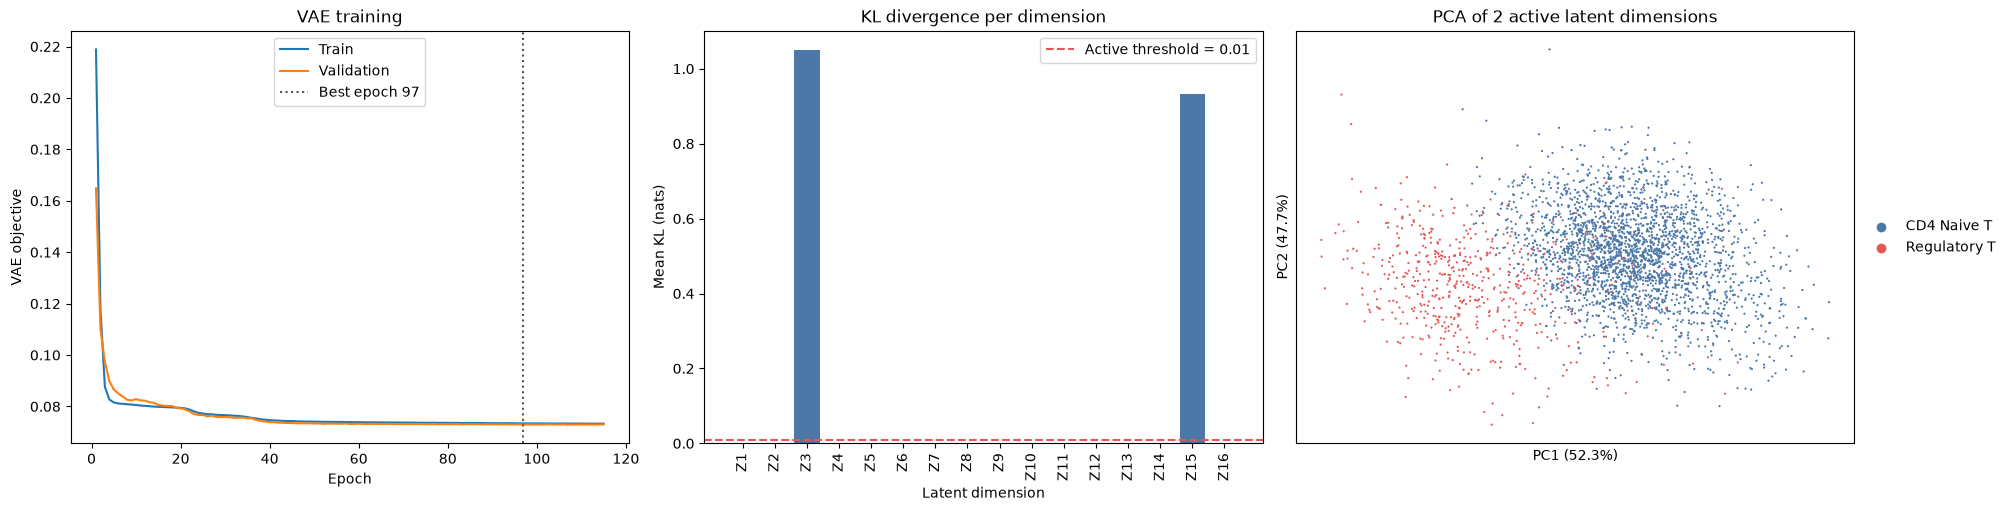

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
latent_dimension,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,Z11,Z12,Z13,Z14,Z15,Z16
KL_nats,0.00108,0.000696,1.049111,0.000554,0.001305,0.001333,0.00095,0.00083,0.001257,0.000619,0.000969,0.000697,0.001158,0.000676,0.932234,0.00144
std,0.029651,0.027466,0.937522,0.025933,0.036082,0.033263,0.03329,0.021783,0.040903,0.0242,0.027495,0.024361,0.032832,0.024678,0.906282,0.044971


In [26]:
class ExpressionVAE(nn.Module):
    def __init__(self, n_genes: int, latent_dim: int):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_genes, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU())
        self.mu = nn.Linear(128, latent_dim)
        self.logvar = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 128), nn.ReLU(),
                                     nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, n_genes))

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        hidden = self.encoder(x)
        return self.mu(hidden), self.logvar(hidden).clamp(-10, 10)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if self.training else mu
        return self.decoder(z), mu, logvar


def vae_loss(x, reconstruction, mu, logvar, beta):
    reconstruction_loss = (reconstruction - x).square().mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).mean()
    return reconstruction_loss + beta * kl, reconstruction_loss, kl


vae = ExpressionVAE(X.shape[1], LATENT_DIM).to(DEVICE)
optimizer = torch.optim.Adam(vae.parameters(), lr=LEARNING_RATE)
history, best_val, stale, best_weights, best_epoch = [], float('inf'), 0, None, None

for epoch in range(1, EPOCHS + 1):
    vae.train()
    training_sum = training_reconstruction = training_kl = 0.0
    epoch_beta = BETA * min(1.0, epoch / KL_WARMUP_EPOCHS)

    for (batch,) in train_loader:
        batch = batch.to(DEVICE)
        loss, batch_reconstruction, batch_kl = vae_loss(batch, *vae(batch), epoch_beta)

        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite VAE training loss.')

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(vae.parameters(), 5.0)
        optimizer.step()

        training_sum += loss.item() * len(batch)
        training_reconstruction += batch_reconstruction.item() * len(batch)
        training_kl += batch_kl.item() * len(batch)

    vae.eval()

    with torch.no_grad():
        validation, reconstruction_loss, kl = vae_loss(val_tensor, *vae(val_tensor), BETA)

    if not torch.isfinite(validation):
        raise FloatingPointError('Non-finite VAE validation loss.')

    history.append({
        'epoch': epoch,
        'beta': epoch_beta,
        'train_loss': training_sum / len(train_ids),
        'train_reconstruction': training_reconstruction / len(train_ids),
        'train_kl': training_kl / len(train_ids),
        'val_loss': validation.item(),
        'val_reconstruction': reconstruction_loss.item(),
        'val_kl': kl.item()
    })

    if validation.item() < best_val - 1e-5:
        best_val, stale, best_weights, best_epoch = validation.item(), 0, deepcopy(vae.state_dict()), epoch
    else:
        stale += 1

    if epoch == 1 or epoch % 20 == 0:
        print(f'Epoch {epoch:3d}: validation={validation.item():.4f}, KL={kl.item():.4f}')

    if epoch >= KL_WARMUP_EPOCHS and stale >= PATIENCE:
        print(f'Early stopping at epoch {epoch}')
        break

if best_weights is None:
    raise RuntimeError('No valid VAE checkpoint was produced.')

vae.load_state_dict(best_weights)
vae.eval()

with torch.no_grad():
    Z_space = np.concatenate([
        vae.encode(torch.from_numpy(X[start:start + BATCH_SIZE]).to(DEVICE))[0].cpu().numpy()
        for start in range(0, len(X), BATCH_SIZE)
    ])

if Z_space.shape != (adata.n_obs, LATENT_DIM) or not np.isfinite(Z_space).all():
    raise ValueError('Unexpected Z space shape or non-finite latent coordinates.')

adata.obsm['X_z'] = Z_space
training_history = pd.DataFrame(history)

with torch.no_grad():
    kl_per_dimension = np.concatenate([
        (-0.5 * (1 + logvar - mu.square() - logvar.exp())).cpu().numpy()
        for mu, logvar in [
            vae.encode(torch.from_numpy(X[start:start + BATCH_SIZE]).to(DEVICE))
            for start in range(0, len(X), BATCH_SIZE)
        ]
    ]).mean(axis=0)

if not np.isfinite(kl_per_dimension).all() or np.any(kl_per_dimension < -1e-6):
    raise ValueError('KL divergence per latent dimension must be finite and non-negative.')

kl_table = pd.DataFrame({
    'latent_dimension': [f'Z{i + 1}' for i in range(LATENT_DIM)],
    'KL_nats': kl_per_dimension,
    'std': Z_space.std(axis=0)
})

kl_threshold = 0.01
active_mask = kl_per_dimension > kl_threshold
active_dimensions = int(active_mask.sum())
inactive_dimensions = LATENT_DIM - active_dimensions

if active_dimensions < 2:
    raise ValueError(f'Only {active_dimensions} active latent dimension(s); 2D PCA requires at least 2.')

Z_active = Z_space[:, active_mask]
active_names = kl_table.loc[active_mask, 'latent_dimension'].tolist()

pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Z_active)
adata.obsm['X_z_pca'] = Z_pca

fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)

axes[0].plot(training_history['epoch'], training_history['train_loss'], label='Train')
axes[0].plot(training_history['epoch'], training_history['val_loss'], label='Validation')
axes[0].axvline(best_epoch, c='#555555', ls=':', label=f'Best epoch {best_epoch}')
axes[0].set(xlabel='Epoch', ylabel='VAE objective', title='VAE training')
axes[0].legend()

axes[1].bar(kl_table['latent_dimension'], kl_table['KL_nats'], color=[
    '#4C78A8' if active else '#BAB0AC' for active in active_mask
])
axes[1].axhline(kl_threshold, c='#E45756', ls='--', label=f'Active threshold = {kl_threshold}')
axes[1].set(xlabel='Latent dimension', ylabel='Mean KL (nats)', title='KL divergence per dimension')
axes[1].tick_params(axis='x', rotation=90)
axes[1].legend()

sc.pl.embedding(
    adata,
    basis='z_pca',
    color='subtype',
    palette=['#4C78A8', '#E45756'],
    size=10,
    title=f'PCA of {active_dimensions} active latent dimensions',
    ax=axes[2],
    show=False
)
axes[2].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[2].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')

plt.show()
display(kl_table.T)

assert set(adata.obs['subtype'].astype(str)) == set(SUBTYPES)
assert X.shape == (adata.n_obs, N_HVG)
assert adata.var_names[adata.var['highly_variable']].equals(hvg_names)
assert adata.obsm['X_z'].shape == (adata.n_obs, LATENT_DIM)
assert Z_pca.shape == (adata.n_obs, 2) and np.isfinite(Z_pca).all()
#np.testing.assert_allclose(pca.transform(Z_active), Z_pca, rtol=1e-4, atol=1e-4)

## 4. Z space → PCA 2차원 + subtype 색상

점 하나는 세포 하나입니다. `Z_space`에 새 PCA를 fit하고 `adata.obsm['X_z_pca']`에 저장합니다. 색상은 `adata.obs['subtype']`입니다. 축의 괄호는 각 주성분의 설명 분산 비율입니다. 두 subtype이 겹치더라도 label 기반 좌표 이동이나 강제 분리는 하지 않습니다.


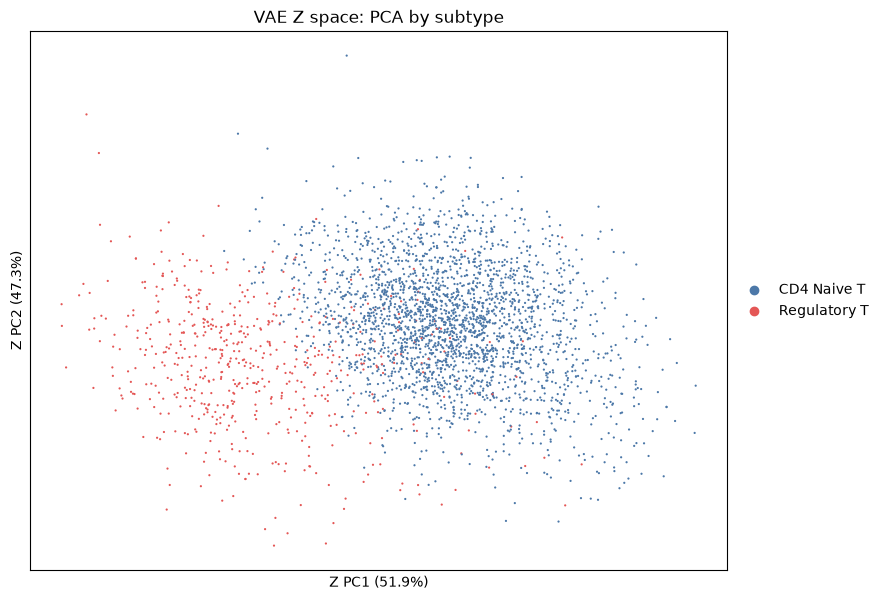

In [27]:
pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Z_space)
adata.obsm['X_z_pca'] = Z_pca

fig, ax = plt.subplots(figsize=(9, 7))
sc.pl.embedding(
    adata,
    basis='z_pca',
    color='subtype',
    palette=['#4C78A8', '#E45756'],
    size=10,
    title='VAE Z space: PCA by subtype',
    ax=ax,
    show=False,
)
ax.set_xlabel(f'Z PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'Z PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.show()

assert set(adata.obs['subtype'].astype(str)) == set(SUBTYPES)
assert X.shape == (adata.n_obs, N_HVG)
assert adata.var_names[adata.var['highly_variable']].equals(hvg_names)
assert adata.obsm['X_z'].shape == (adata.n_obs, LATENT_DIM)
assert Z_pca.shape == (adata.n_obs, 2) and np.isfinite(Z_pca).all()
assert len(ax.collections[0].get_offsets()) == adata.n_obs
np.testing.assert_allclose(pca.transform(Z_space), Z_pca, rtol=1e-4, atol=1e-4)

## 5. 가상 latent 좌표 DQN: Naive PCA median → Treg PCA median

VAE와 PCA는 그대로 유지합니다. 시작/도착점은 실제 세포나 nearest-5 centroid가 아니라 **PCA 공간에서 subtype별 median 좌표**입니다.
이 2차원 median을 기존 PCA의 `inverse_transform`으로 16차원 latent 좌표로 복원하여 사용합니다(PC1–2 이외 성분은 Z 평균). 두 좌표 모두 **가상의 세포 좌표**이며 측정된 세포가 아닙니다.

- **상태**: 연속 16차원 latent 좌표(좌표 그래프 없음). 모든 좌표는 행동으로 새로 생성됩니다.
- **행동 68개**: 목표 방향, 목표 반대 방향, 16개 latent 축의 ±방향 각각에 **L·0.5L 두 이동 길이**를 제공합니다. 실제 세포 좌표를 선택하지 않고 현재 Z에 이동 벡터를 더해 가상 좌표를 생성합니다. 이동 상한은 **`L = 2D/500`** 입니다(`D`=시작–목표 Z 거리). 목표가 L 이내이면 full-length 목표 방향 action만 허용하여 남은 거리만큼 이동하고 즉시 종료합니다. 짧은 이동도 1 action으로 계산하며 500 action 이내 도착 가능성 제약은 최대 이동 길이 L로 계산합니다.
- **최대 500 action, 목표 도착 또는 거리 수렴 시 종료**: DQN step별 목표 거리의 누적 최솟값을 추적합니다. 최근 **20회 이동** 동안 최솟값의 개선량이 **`0.1 * L` 이하**이면 정체로 판단하여 학습 episode와 평가 rollout을 종료합니다. 분산이나 일정한 접근 속도를 기준으로 종료하지 않습니다. 목표 도착 판정은 16차원 거리 `<= L * 1e-4`이며 해당 좌표만 정확한 목표로 맞춥니다. 정체 종료는 목표 도착으로 기록하지 않으며 실제 종료 좌표를 보존합니다. 각 후보의 support·남은 이동 수 내 도착 가능성 제약은 유지합니다. 실제 이동 수 + 1개의 좌표를 저장하며 새 종료 조건으로 DQN을 재학습해야 합니다.
- **Support 규제**: 도착 좌표의 5번째 최근접 실제 세포 거리가 관측 세포 q95 이하인 행동만 허용합니다(데이터 밖의 latent로 이탈 방지, 목표 action 제외).
- PCA는 시각화에만 사용하며 거리·entropy·학습은 모두 16차원 Z에서 계산합니다.

In [28]:
from scipy.special import logsumexp
from sklearn.neighbors import NearestNeighbors
import json
import time

REGION_SIZE = 5
RL_MIN_MOVES, RL_MAX_STEPS = 1, 500
RL_PROGRESS_WEIGHT, RL_STEP_COST, RL_GOAL_BONUS = 1.0, 0.03, 1.0
RL_SHORT_MOVE_WEIGHT, RL_REWARD_SCALE, RL_GAMMA = 1.0, 0.1, 0.99
RL_MOVE_FRACTIONS = (1.0, 0.5)
RL_SUPPORT_QUANTILE = 0.95
RL_N_ENVS, RL_VECTOR_STEPS, RL_UPDATES_PER_STEP = 256, 3000, 2
RL_BATCH_SIZE, RL_REPLAY_SIZE, RL_LR, RL_TARGET_SYNC = 1024, 400000, 3e-4, 500
RL_EVAL_EVERY = 250
RL_DISTANCE_PATIENCE = 20
RL_REWARD_VERSION = 'short_latent_move_goal_progress_distance_convergence_v8'
RL_RESULT_DIR = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/coordinate_dqn')
RL_RESULT_DIR.mkdir(parents=True, exist_ok=True)
rl_rng = np.random.default_rng(SEED + 100)
torch.manual_seed(SEED + 100)

cell_subtypes = adata.obs['subtype'].astype(str).to_numpy()
naive_ids = np.flatnonzero(cell_subtypes == 'CD4 Naive T')
treg_ids = np.flatnonzero(cell_subtypes == 'Regulatory T')
pca_median_xy = np.stack([np.median(Z_pca[naive_ids], axis=0), np.median(Z_pca[treg_ids], axis=0)])
z_start, z_goal = pca.inverse_transform(pca_median_xy).astype(np.float32)
np.testing.assert_allclose(pca.transform(np.stack([z_start, z_goal])), pca_median_xy, atol=1e-5)
start_barcode, end_barcode = 'virtual_CD4_Naive_T_PCA_median', 'virtual_Regulatory_T_PCA_median'
rl_total_distance = float(np.linalg.norm(z_goal - z_start))
RL_STEP_LENGTH = 2 * rl_total_distance / RL_MAX_STEPS
RL_DISTANCE_MIN_DELTA = 0.1 * RL_STEP_LENGTH

rl_decoder = vae.decoder.eval()
Z_tensor = torch.tensor(Z_space, dtype=torch.float32, device=DEVICE)
z_start_t = torch.tensor(z_start, device=DEVICE)
z_goal_t = torch.tensor(z_goal, device=DEVICE)


@torch.no_grad()
def decoded_entropy_t(z: torch.Tensor) -> torch.Tensor:
    linear = torch.expm1(rl_decoder(z).double().clamp_min(0))
    totals = linear.sum(dim=1, keepdim=True)
    if not torch.isfinite(linear).all() or (totals <= 0).any():
        raise FloatingPointError('Decoder entropy requires finite, nonzero decoded CP10K expression.')
    p = linear / totals
    return -torch.xlogy(p, p).sum(dim=1).float()


@torch.no_grad()
def support_distance_t(z: torch.Tensor) -> torch.Tensor:
    return torch.cdist(z.reshape(-1, LATENT_DIM), Z_tensor).topk(REGION_SIZE, largest=False).values[:, -1]


observed_decoded_entropy = torch.cat([decoded_entropy_t(Z_tensor[start:start + 1024])
                                      for start in range(0, len(Z_tensor), 1024)]).cpu().numpy()
rl_entropy_scale = float(observed_decoded_entropy.std(ddof=1))
rl_entropy_floor = float(observed_decoded_entropy.min())
with torch.no_grad():
    observed_fifth = torch.cdist(Z_tensor, Z_tensor).topk(REGION_SIZE + 1, largest=False).values[:, -1]
rl_support_radius = float(torch.quantile(observed_fifth, RL_SUPPORT_QUANTILE))
h_start = float(decoded_entropy_t(z_start_t[None])[0])
h_goal = float(decoded_entropy_t(z_goal_t[None])[0])
z_feature_mean = torch.tensor(Z_space.mean(axis=0), device=DEVICE)
z_feature_scale = torch.tensor(Z_space.std(axis=0), device=DEVICE).clamp_min(1e-6)
latent_axes = torch.eye(LATENT_DIM, device=DEVICE)
N_DIRECTIONS = 2 + 2 * LATENT_DIM
N_ACTIONS = N_DIRECTIONS * len(RL_MOVE_FRACTIONS)
direction_names = ['goal', 'away_from_goal'] + [f'{sign}Z{dimension + 1}'
    for sign in ('+', '-') for dimension in range(LATENT_DIM)]
action_names = [f'{direction}@{fraction:g}L' for fraction in RL_MOVE_FRACTIONS for direction in direction_names]


@torch.no_grad()
def candidate_moves(z: torch.Tensor, t: torch.Tensor):
    delta = z_goal_t - z
    distance = delta.norm(dim=1, keepdim=True)
    direction_goal = delta / distance.clamp_min(1e-12)
    directions = torch.cat([direction_goal[:, None], -direction_goal[:, None],
        torch.cat([latent_axes, -latent_axes])[None].expand(len(z), -1, -1)], dim=1)
    move_groups = []
    for fraction in RL_MOVE_FRACTIONS:
        group = directions * (fraction * RL_STEP_LENGTH)
        group[:, 0] = direction_goal * distance.clamp_max(fraction * RL_STEP_LENGTH)
        move_groups.append(group)
    moves = torch.cat(move_groups, dim=1)
    valid = torch.ones(len(z), N_ACTIONS, dtype=torch.bool, device=DEVICE)
    for offset in range(0, N_ACTIONS, N_DIRECTIONS):
        valid[:, offset:offset + 2] = distance > 1e-7
    return moves, valid


@torch.no_grad()
def action_mask(z: torch.Tensor, t: torch.Tensor):
    moves, valid = candidate_moves(z, t)
    landing = z[:, None] + moves
    support = support_distance_t(landing).reshape(len(z), N_ACTIONS)
    supported = support <= rl_support_radius
    supported[:, ::N_DIRECTIONS] = True
    distance_next = (z_goal_t.double() - landing.double()).norm(dim=2)
    remaining = (RL_MAX_STEPS - t - 1)[:, None]
    tolerance = RL_STEP_LENGTH * 1e-4
    # Reserve float32 rounding room for each remaining move, not just the final move.
    reachable = distance_next <= remaining * RL_STEP_LENGTH * (1 - 1e-4) + tolerance
    distance = (z_goal_t - z).norm(dim=1)
    valid &= (remaining >= 0) & (distance > tolerance)[:, None]
    must_finish = (distance <= RL_STEP_LENGTH)[:, None] | (remaining == 0)
    valid &= ~must_finish | (torch.arange(N_ACTIONS, device=DEVICE)[None] == 0)
    return valid & supported & reachable, moves, support


@torch.no_grad()
def candidate_entropies(z, moves, mask):
    if not mask.any(dim=1).all():
        raise RuntimeError('No feasible latent candidate satisfying the required goal deadline.')
    landing = z[:, None] + moves
    snap_goal = (z_goal_t - landing).norm(dim=2) <= RL_STEP_LENGTH * 1e-4
    landing[snap_goal] = z_goal_t
    values = decoded_entropy_t(landing.reshape(-1, LATENT_DIM)).reshape(len(z), N_ACTIONS)
    return values, values.masked_fill(~mask, torch.inf).amin(dim=1), values.masked_fill(~mask, -torch.inf).amax(dim=1)


def short_latent_move_reward(move_length):
    if not torch.isfinite(move_length).all() or (move_length < 0).any():
        raise ValueError('Latent movement lengths must be finite and nonnegative.')
    if (move_length > RL_STEP_LENGTH * (1 + 1e-4)).any():
        raise ValueError('Latent movement exceeds the L step cap.')
    return RL_SHORT_MOVE_WEIGHT * (1 - move_length / RL_STEP_LENGTH).clamp(0, 1)


@torch.no_grad()
def state_features(z, h, h_min, t):
    distance = (z_goal_t - z).norm(dim=1, keepdim=True)
    slack = (RL_MAX_STEPS - t.float()[:, None] - distance / RL_STEP_LENGTH) / RL_MAX_STEPS
    return torch.cat([(z - z_feature_mean) / z_feature_scale, (z_goal_t - z) / rl_total_distance,
                      distance / rl_total_distance, ((h - h_start) / rl_entropy_scale)[:, None],
                      ((h_min - h_start) / rl_entropy_scale)[:, None], t.float()[:, None] / RL_MAX_STEPS, slack],
                     dim=1)


def transition_reward_components(distance, distance_next, move_length, reached):
    progress = RL_PROGRESS_WEIGHT * (distance - distance_next) / RL_STEP_LENGTH
    short_move = short_latent_move_reward(move_length)
    goal = RL_GOAL_BONUS * reached.float()
    return progress, short_move, goal


@torch.no_grad()
def distance_stop_state(distance_history, distance, t):
    rows = torch.arange(len(distance), device=distance.device)
    size = RL_DISTANCE_PATIENCE + 1
    previous_best = distance_history[(t - 1) % size, rows]
    window_best = distance_history[(t - RL_DISTANCE_PATIENCE) % size, rows].clone()
    best = torch.minimum(previous_best, distance)
    distance_history[t % size, rows] = best
    converged = (t >= RL_DISTANCE_PATIENCE) & (window_best - best <= RL_DISTANCE_MIN_DELTA)
    reached = distance <= RL_STEP_LENGTH * 1e-4
    return reached | converged | (t >= RL_MAX_STEPS)


def distance_stop_status(distance, step):
    if distance <= RL_STEP_LENGTH * 1e-4:
        return f'target_reached_at_step_{step}'
    if step >= RL_MAX_STEPS:
        return f'max_steps_at_step_{step}'
    return f'distance_converged_at_step_{step}'


@torch.no_grad()
def environment_step(z, h_min, t, actions, moves, distance_history):
    distance = (z_goal_t - z).norm(dim=1)
    mask, expected_moves, _ = action_mask(z, t)
    if not mask[torch.arange(len(z), device=DEVICE), actions].all():
        raise ValueError('Chosen latent action violates support, horizon, or mandatory goal arrival.')
    if not torch.allclose(moves, expected_moves):
        raise ValueError('Candidate moves do not match the current virtual latent state.')
    z_next = z + moves[torch.arange(len(z), device=DEVICE), actions]
    reached = (z_goal_t - z_next).norm(dim=1) <= RL_STEP_LENGTH * 1e-4
    z_next[reached] = z_goal_t
    distance_next = (z_goal_t - z_next).norm(dim=1)
    h_next = decoded_entropy_t(z_next)
    move_length = (z_next - z).norm(dim=1)
    terminal_goal = distance_next <= RL_STEP_LENGTH * 1e-4
    progress, short_move, goal = transition_reward_components(
        distance, distance_next, move_length, terminal_goal)
    base = progress + short_move - RL_STEP_COST + goal
    done = distance_stop_state(distance_history, distance_next, t + 1)
    return z_next, h_next, torch.minimum(h_min, h_next), t + 1, base, done


reward_probe_lengths = RL_STEP_LENGTH * torch.tensor([0.25, 0.5, 1.0], device=DEVICE)
torch.testing.assert_close(short_latent_move_reward(reward_probe_lengths),
    RL_SHORT_MOVE_WEIGHT * torch.tensor([0.75, 0.5, 0.], device=DEVICE))
print(f'Virtual 16D latent: distance D={rl_total_distance:.4f}; step cap L={RL_STEP_LENGTH:.5f}; {N_ACTIONS} actions')
print(f'Decoded Shannon H: start={h_start:.4f}, goal={h_goal:.4f}; observation only, not a reward.')
print(f'Reward: goal progress/L + (1 - latent move length/L), weights 1:1, - {RL_STEP_COST}; goal bonus={RL_GOAL_BONUS}; {RL_REWARD_VERSION}')
print(f'At most 500 moves; stop at goal or when best distance improves by <= {RL_DISTANCE_MIN_DELTA:.6g} over {RL_DISTANCE_PATIENCE} moves.')

Virtual 16D latent: distance D=1.9048; step cap L=0.00762; 68 actions
Decoded Shannon H: start=3.4564, goal=4.0002; observation only, not a reward.
Reward: goal progress/L + (1 - latent move length/L), weights 1:1, - 0.03; goal bonus=1.0; short_latent_move_goal_progress_distance_convergence_v8
At most 500 moves; stop at goal or when best distance improves by <= 0.000761915 over 20 moves.


### 보상: Treg median 접근 + 작은 latent 이동 (가중치 1:1)

`r = (d_current - d_next)/L + clip(1 - ||z_next-z_current||/L, 0, 1) - 0.03 + 1.0 * [목표 최초 도착]`

- 첫 항은 기존 Treg PCA-median을 inverse PCA한 16D 목표까지의 거리 감소 보상입니다.
- 두 번째 항은 **가상 좌표의 실제 Euclidean latent 이동량**을 L로 정규화합니다. L 이동은 0, 0.5L 이동은 0.5이며, 목표 도착 시 snap을 적용한 실제 변위로 계산합니다. 목표 접근·작은 이동의 가중치는 각각 1입니다. 방향의 부드러움, start-end 직선 이탈, 주변 실제 세포 분산을 최소화하는 보상은 아닙니다.
- 같은 직선상 목표 방향이면 L 이동은 접근 1 + 작은 이동 0, 0.5L 이동은 접근 0.5 + 작은 이동 0.5이므로 즉시 합산 점수는 같습니다. 가중치 1:1은 짧은 이동을 무조건 강제하지 않으며, 장기 할인 보상·도착 보너스·500-action 제약도 선택에 영향을 줍니다. 짧은 우회도 양의 보상을 받을 수 있으므로 거리 수렴 종료·도착 가능성 제약을 유지합니다. 길이 0의 정지 action은 제공하지 않습니다.
- `H = -sum(p log p)`, `p = expm1(max(decoder(z), 0)) / sum`는 **관찰용 상태 정보·진단 색상일 뿐 보상에 포함하지 않습니다**. 기존 VAE와 PCA는 재학습하지 않습니다. PCA는 생성된 좌표의 시각화에만 사용합니다.
- 목표 보너스 1은 목표 최초 도착 시 지급하고 즉시 종료하여 반복 방문 보너스를 방지합니다. `gamma=0.99`, training reward scale=0.1, step cost=0.03입니다.
- 각 좌표의 Z1-Z16, PCA 좌표, H와 관찰용 delta H, 관찰용 후보 H 최소·최대, 접근/작은 latent 이동/도착/step-cost 보상을 CSV에 저장합니다. `dqn_candidate_movement_audit.csv`에는 후보 H(관찰값), 이동 길이, 허용 여부, 작은 이동 보상, 선택 여부를 저장합니다. 이전 entropy reward CSV를 새 결과로 해석하지 않도록 reward version을 변경합니다. 새 action 수에 맞게 정책을 재생성·재학습해야 합니다.
- 하나의 DQN이 두 보상의 합을 최적화하며, 목표 도착·거리 수렴·최대 500 step 중 먼저 발생한 조건에서 종료한 평가 경로의 할인 누적 합산 보상으로 checkpoint를 선택합니다. 수렴 종료에는 목표 도착 보너스를 주지 않습니다. 모든 step의 entropy 감소는 요구하지 않습니다. PCA에는 종료까지 생성된 경로와 **실제 생성된 step 1–종료 step 중 최소 H 좌표**를 표시합니다. 이는 관측 세포의 최소 entropy나 전체 latent 공간의 전역 최적점이 아닙니다.

In [29]:
class LatentQNetwork(nn.Module):
    def __init__(self, n_features: int, n_actions: int):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(n_features, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(),
                                     nn.Linear(256, n_actions))

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.network(features)


N_STATE_FEATURES = 2 * LATENT_DIM + 5
rl_trained_reward_version = None
latent_q = LatentQNetwork(N_STATE_FEATURES, N_ACTIONS).to(DEVICE)
latent_q_target = deepcopy(latent_q).eval()
rl_optimizer = torch.optim.Adam(latent_q.parameters(), lr=RL_LR)


@torch.no_grad()
def masked_greedy(model, features, mask):
    return model(features).masked_fill(~mask, -torch.inf).argmax(dim=1)


@torch.no_grad()
def latent_rollout(model=None, z0=None, max_steps=RL_MAX_STEPS):
    """Greedy rollout (or straight-line baseline when model is None) from the Naive PCA-median latent."""
    z = (z_start_t if z0 is None else z0)[None].clone()
    h = decoded_entropy_t(z)
    h_min, t = h.clone(), torch.zeros(1, dtype=torch.long, device=DEVICE)
    path, entropies, actions, q_values, rewards, supports = [z[0].cpu().numpy()], [float(h)], [], [], [], [float(support_distance_t(z)[0])]
    if max_steps != RL_MAX_STEPS:
        raise ValueError('Evaluation must use the same 500-move maximum and distance-convergence rule as training.')
    distance_history = (z_goal_t - z).norm(dim=1).repeat(RL_DISTANCE_PATIENCE + 1, 1)
    status = 'incomplete'
    for _ in range(max_steps):
        mask, moves, support = action_mask(z, t)
        if not mask.any():
            raise RuntimeError(f'No feasible rollout action: t={int(t[0])}, '
                f'distance/L={float((z_goal_t - z).norm() / RL_STEP_LENGTH)}, '
                f'nearest5={float(support_distance_t(z)[0])}')
        if model is None:
            goal_distances = (z_goal_t - (z[:, None] + moves)).norm(dim=2).masked_fill(~mask, torch.inf)
            action = goal_distances.argmin(dim=1)
            q_values.append(np.nan)
        else:
            q = model(state_features(z, h, h_min, t)).masked_fill(~mask, -torch.inf)
            action = q.argmax(dim=1)
            q_values.append(float(q[0, action]))
        z, h, h_min, t, base, done = environment_step(z, h_min, t, action, moves, distance_history)
        path.append(z[0].cpu().numpy()); entropies.append(float(h)); actions.append(int(action))
        rewards.append(float(base)); supports.append(float(support[0, action]))
        if bool(done):
            status = distance_stop_status(float((z_goal_t - z).norm()), int(t[0]))
            break
    rewards = np.asarray(rewards)
    if status == 'incomplete':
        raise RuntimeError('Rollout ended without a termination reason.')
    arrival_steps = np.flatnonzero(np.linalg.norm(np.asarray(path) - z_goal, axis=1) <= RL_STEP_LENGTH * 1e-4)
    if len(arrival_steps) and (len(arrival_steps) != 1 or arrival_steps[0] != len(actions)):
        raise RuntimeError('Rollout contains coordinates after its first goal arrival.')
    return {'path_z': np.asarray(path, dtype=np.float32), 'entropy': np.asarray(entropies),
            'actions': np.asarray(actions, dtype=np.int64), 'chosen_Q': np.asarray(q_values),
            'base_rewards': rewards, 'support_distance': np.asarray(supports), 'status': status,
            'base_return': float(np.sum(rewards * RL_GAMMA ** np.arange(len(rewards))))}


@torch.no_grad()
def reset_environments(count: int):
    # Half from the exact Naive median; half from perturbed points on the start-goal segment (exploration starts).
    fraction = torch.rand(count, 1, device=DEVICE) * 0.9
    z = z_start_t + fraction * (z_goal_t - z_start_t) + torch.randn(count, LATENT_DIM, device=DEVICE) * z_feature_scale * 0.5
    keep_start = ((torch.rand(count, device=DEVICE) < 0.5) | (support_distance_t(z) > rl_support_radius)
                  | ((z_goal_t - z).norm(dim=1) > RL_MAX_STEPS * RL_STEP_LENGTH)
                  | ((z_goal_t - z).norm(dim=1) <= RL_STEP_LENGTH * 1e-4))
    z[keep_start] = z_start_t
    h = decoded_entropy_t(z)
    h_min = h.clone()
    return z, h, h_min, torch.zeros(count, dtype=torch.long, device=DEVICE)


replay_features = torch.empty(RL_REPLAY_SIZE, N_STATE_FEATURES, device=DEVICE)
replay_next = torch.empty_like(replay_features)
replay_next_mask = torch.empty(RL_REPLAY_SIZE, N_ACTIONS, dtype=torch.bool, device=DEVICE)
replay_actions = torch.empty(RL_REPLAY_SIZE, dtype=torch.long, device=DEVICE)
replay_rewards = torch.empty(RL_REPLAY_SIZE, device=DEVICE)
replay_done = torch.empty(RL_REPLAY_SIZE, dtype=torch.bool, device=DEVICE)

In [30]:
import time

rl_start_time = time.time()
env_z, env_h, env_h_min, env_t = reset_environments(RL_N_ENVS)
env_distance_history = (z_goal_t - env_z).norm(dim=1).repeat(RL_DISTANCE_PATIENCE + 1, 1)
env_mask, env_moves, _ = action_mask(env_z, env_t)
env_features = state_features(env_z, env_h, env_h_min, env_t)
replay_position, replay_count, rl_updates = 0, 0, 0
rl_history, rl_episodes = [], []
best_rl_step, best_rl_return, best_q_weights = None, -np.inf, None
episode_return = torch.zeros(RL_N_ENVS, device=DEVICE)
for vector_step in range(1, RL_VECTOR_STEPS + 1):
    epsilon = max(0.05, 1.0 - vector_step / (0.6 * RL_VECTOR_STEPS))
    greedy = masked_greedy(latent_q, env_features, env_mask)
    random_actions = torch.multinomial(env_mask.float(), 1).squeeze(1)
    explore = torch.rand(RL_N_ENVS, device=DEVICE) < epsilon
    actions = torch.where(explore, random_actions, greedy)
    env_z, env_h, env_h_min, env_t, base, done = environment_step(env_z, env_h_min, env_t, actions, env_moves, env_distance_history)
    next_features = state_features(env_z, env_h, env_h_min, env_t)
    next_mask, next_moves, _ = action_mask(env_z, env_t)
    slots = (replay_position + torch.arange(RL_N_ENVS, device=DEVICE)) % RL_REPLAY_SIZE
    replay_features[slots], replay_next[slots], replay_next_mask[slots] = env_features, next_features, next_mask
    replay_actions[slots], replay_rewards[slots], replay_done[slots] = actions, RL_REWARD_SCALE * base, done
    replay_position = (replay_position + RL_N_ENVS) % RL_REPLAY_SIZE
    replay_count = min(replay_count + RL_N_ENVS, RL_REPLAY_SIZE)
    episode_return += base
    if done.any():
        for index in torch.nonzero(done).flatten().tolist():
            rl_episodes.append({'vector_step': vector_step, 'moves': int(env_t[index]),
                                'base_return_undiscounted': float(episode_return[index]),
                                'final_distance_to_goal': float((env_z[index] - z_goal_t).norm()),
                                'status': distance_stop_status(float((env_z[index] - z_goal_t).norm()), int(env_t[index]))})
        episode_return[done] = 0
        fresh = reset_environments(int(done.sum()))
        env_z[done], env_h[done], env_h_min[done], env_t[done] = fresh
        env_distance_history[:, done] = (z_goal_t - fresh[0]).norm(dim=1)[None]
        next_mask[done], next_moves[done], _ = action_mask(fresh[0], fresh[3])
        next_features[done] = state_features(*fresh)
    if (~next_mask.any(dim=1)).any():
        failed = ~next_mask.any(dim=1)
        raise RuntimeError(f'No feasible latent action at vector step {vector_step}; '
            f't={env_t[failed].tolist()}, distance/L={((z_goal_t - env_z[failed]).norm(dim=1) / RL_STEP_LENGTH).tolist()}, '
            f'nearest5={support_distance_t(env_z[failed]).tolist()}')
    env_features, env_mask, env_moves = next_features, next_mask, next_moves

    if replay_count >= 8 * RL_BATCH_SIZE:
        for _ in range(RL_UPDATES_PER_STEP):
            batch = torch.randint(replay_count, (RL_BATCH_SIZE,), device=DEVICE)
            prediction = latent_q(replay_features[batch]).gather(1, replay_actions[batch, None]).squeeze(1)
            with torch.no_grad():
                next_action = masked_greedy(latent_q, replay_next[batch], replay_next_mask[batch])
                next_value = latent_q_target(replay_next[batch]).gather(1, next_action[:, None]).squeeze(1)
                expected = replay_rewards[batch] + RL_GAMMA * next_value * (~replay_done[batch]).float()
            loss = nn.functional.smooth_l1_loss(prediction, expected)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite DQN loss.')
            rl_optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(latent_q.parameters(), 5.0)
            rl_optimizer.step()
            rl_updates += 1
            if rl_updates % RL_TARGET_SYNC == 0:
                latent_q_target.load_state_dict(latent_q.state_dict())
    if vector_step % RL_EVAL_EVERY == 0 and rl_updates:
        latent_q.eval()
        evaluation = latent_rollout(latent_q)
        latent_q.train()
        assert 1 <= len(evaluation['actions']) <= RL_MAX_STEPS
        assert evaluation['status'] == distance_stop_status(float(np.linalg.norm(evaluation['path_z'][-1] - z_goal)), len(evaluation['actions']))
        rl_history.append({'vector_step': vector_step, 'transitions': vector_step * RL_N_ENVS, 'updates': rl_updates,
                           'epsilon': epsilon, 'loss': float(loss), 'status': evaluation['status'],
                           'moves': len(evaluation['actions']), 'discounted_base_return': evaluation['base_return'],
                           'min_entropy': float(evaluation['entropy'].min()), 'final_entropy': float(evaluation['entropy'][-1]),
                           'mean_entropy': float(evaluation['entropy'].mean())})
        if evaluation['base_return'] > best_rl_return:
            best_rl_step, best_rl_return = vector_step, evaluation['base_return']
            best_q_weights = deepcopy(latent_q.state_dict())
        print(f'DQN {vector_step:5d}/{RL_VECTOR_STEPS}: eps={epsilon:.2f} loss={float(loss):.4f} '
              f'status={evaluation["status"]} moves={len(evaluation["actions"])} '
              f'return={evaluation["base_return"]:.2f} minH={evaluation["entropy"].min():.4f} '
              f'({time.time() - rl_start_time:.0f}s)', flush=True)
if best_q_weights is None:
    raise RuntimeError('No joint-reward checkpoint with goal/convergence termination was evaluated.')
latent_q.load_state_dict(best_q_weights)
latent_q.eval()
rl_trained_reward_version = RL_REWARD_VERSION
print(f'Selected checkpoint: vector step {best_rl_step}; discounted base return {best_rl_return:.3f}; '
      f'{len(rl_episodes):,} early-terminating training episodes completed; {rl_updates:,} gradient updates')

DQN   250/3000: eps=0.86 loss=0.0009 status=distance_converged_at_step_389 moves=389 return=94.68 minH=3.4564 (6s)
DQN   500/3000: eps=0.72 loss=0.0003 status=target_reached_at_step_468 moves=468 return=96.11 minH=3.4561 (13s)
DQN   750/3000: eps=0.58 loss=0.0002 status=target_reached_at_step_287 moves=287 return=91.51 minH=3.4564 (18s)
DQN  1000/3000: eps=0.44 loss=0.0003 status=target_reached_at_step_500 moves=500 return=96.25 minH=3.4560 (24s)
DQN  1250/3000: eps=0.31 loss=0.0005 status=target_reached_at_step_484 moves=484 return=96.26 minH=3.4564 (30s)
DQN  1500/3000: eps=0.17 loss=0.0001 status=target_reached_at_step_475 moves=475 return=96.15 minH=3.4561 (37s)
DQN  1750/3000: eps=0.05 loss=0.0007 status=target_reached_at_step_486 moves=486 return=96.27 minH=3.4564 (43s)
DQN  2000/3000: eps=0.05 loss=0.0001 status=target_reached_at_step_335 moves=335 return=93.65 minH=3.4564 (48s)
DQN  2250/3000: eps=0.05 loss=0.0004 status=target_reached_at_step_343 moves=343 return=93.92 minH=3.

## 6. 가상 latent 경로 PCA와 학습 진단

보상은 Shannon entropy가 아니라 **목표 거리 감소/L + (1−실제 latent 이동량/L)**이며 가중치는 1:1입니다. 방향별 **0.5L·L** 길이를 선택합니다. DQN은 **최대 500 action**이며 목표 도착 또는 **목표 거리의 개선 수렴** 시 종료합니다. `best_distance[t] = min(distance[0:t+1])`로 두고, `best_distance[t-20] - best_distance[t] <= RL_DISTANCE_MIN_DELTA`이면 종료합니다. 기본 허용 개선량은 `0.1 * L`(현재 데이터에서 약 0.000762)입니다. 학습 episode, DQN 평가, 비교 정책 모두 같은 조건을 사용합니다. 모든 figure와 CSV/NPZ는 action 0부터 실제 종료 action까지만 사용하며 500까지 padding하거나 목표로 보간하지 않습니다. 비교용 entropy 곡선도 DQN 종료 이후는 표시하지 않습니다. 전체 학습 transition 기준 loss/return은 CSV로만 보존합니다. **5절의 설정·함수・network 초기화・학습 셀부터 다시 실행한 뒤 이 절을 실행해야 합니다. 이전 보상·34-action 모델은 재사용하지 않습니다. 기존 figure 출력은 자동 갱신되지 않습니다.**

배경 점은 실제 세포, 선은 학습된 **가상 latent 좌표 → 가상 latent 좌표** 이동입니다. 기존 PCA 변환을 그대로 적용합니다.
실패 경로를 성공 경로나 보간 경로로 대체하지 않습니다. 결과는 `scDQN_results/coordinate_dqn/`에 저장하며, 이후 TF 분석과의 호환을 위해 경로 좌표를 `coordinate_space`로 둡니다(경로 좌표별 주변 실제 세포 5개 정보 포함).

원래 두 패널을 유지합니다. 왼쪽 배경은 실제 세포 subtype, 오른쪽 배경은 실제 세포 latent의 **decoded Shannon entropy**(`viridis`)이며 둘 다 전체 PCA 범위입니다. 두꺼운 경로 선분과 각 화살표는 DQN step **n → n+1**의 실제 PCA 변위이며 **ΔH = H(n+1) − H(n)** 색상을 적용합니다. 파랑은 감소, 빨강은 증가, 흰색은 변화 없음입니다. 배경의 절대 entropy와 경로의 delta H는 별도 colorbar로 구분합니다. 검정 안내 화살표는 실제 경로에 존재하는 20회 이동 구간을 강조합니다. 분홍 마름모는 생성된 step 1–종료 step 중 최소 H 좌표입니다. Treg 목표 X 마커는 유지하며 목표 도착 전 수렴한 경우 실제 종료점을 검정 사각형으로 구분합니다. 그림 제목과 거리 진단 그래프에 종료 사유와 step을 표시합니다. delta H는 관찰값일 뿐 보상의 기준이 아닙니다.

DQN stopped at action 500/500: target_reached_at_step_500; plotting 501 coordinates only.


,policy,status,moves,discounted_base_return,mean_path_entropy,min_path_entropy,final_entropy,min_generated_entropy,min_generated_step,final_distance_to_goal,entropy_decreasing_moves
0,dqn,target_reached_at_step_500,500,96.369317,3.634243,3.456353,4.000167,3.456353,19,0.000000,18
1,straight_goal_only,target_reached_at_step_251,251,89.297027,3.635882,3.456353,4.000167,3.456353,10,0.000000,10
2,entropy_greedy,distance_converged_at_step_20,20,-2.233305,3.451896,3.448321,3.448321,3.448321,20,1.919107,20


,step,coordinate_id,estimated_subtype,estimated_treg_fraction,decoded_entropy_nats,decoded_entropy_min_so_far,delta_entropy_nats,distance_to_goal,PC1,PC2,...,chosen_action,chosen_Q,arrival_progress_reward,arrival_short_latent_move_reward,arrival_feasible_candidate_entropy_min,arrival_feasible_candidate_entropy_max,arrival_goal_bonus,arrival_step_cost,arrival_base_reward,arrival_training_reward
0,0,vlatent_0000,CD4 Naive T,0.0,3.456377,3.456377,NaN,1.904788,0.289279,0.130794,...,goal@0.5L,0.989266,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,vlatent_0001,CD4 Naive T,0.0,3.456375,3.456375,-2.145767e-06,1.900978,0.285662,0.129599,...,goal@0.5L,0.989084,0.499999,0.500000,3.455899,3.456852,0.0,-0.03,0.970016,0.097002
2,2,vlatent_0002,CD4 Naive T,0.0,3.456373,3.456373,-1.907349e-06,1.897169,0.282045,0.128404,...,goal@0.5L,0.988902,0.499999,0.500000,3.455896,3.456851,0.0,-0.03,0.969984,0.096998
19,19,vlatent_0019,CD4 Naive T,0.0,3.456353,3.456353,-7.152557e-07,1.832406,0.220553,0.108083,...,goal@0.5L,0.986060,0.499999,0.500000,3.455867,3.456839,0.0,-0.03,0.970000,0.097000
498,498,vlatent_0498,Regulatory T,1.0,3.997395,3.456353,1.390457e-03,0.007621,-1.512082,-0.464471,...,goal@0.5L,0.909795,0.500000,0.500000,3.994622,3.998782,0.0,-0.03,0.970000,0.097000
499,499,vlatent_0499,Regulatory T,1.0,3.998782,3.456353,1.386881e-03,0.003811,-1.515699,-0.465666,...,goal@1L,0.448333,0.500000,0.500000,3.998771,4.000166,0.0,-0.03,0.970000,0.097000
500,500,vlatent_0500,Regulatory T,1.0,4.000167,3.456353,1.385212e-03,0.000000,-1.519317,-0.466862,...,,NaN,0.500203,0.499797,4.000167,4.000167,1.0,-0.03,1.970000,0.197000


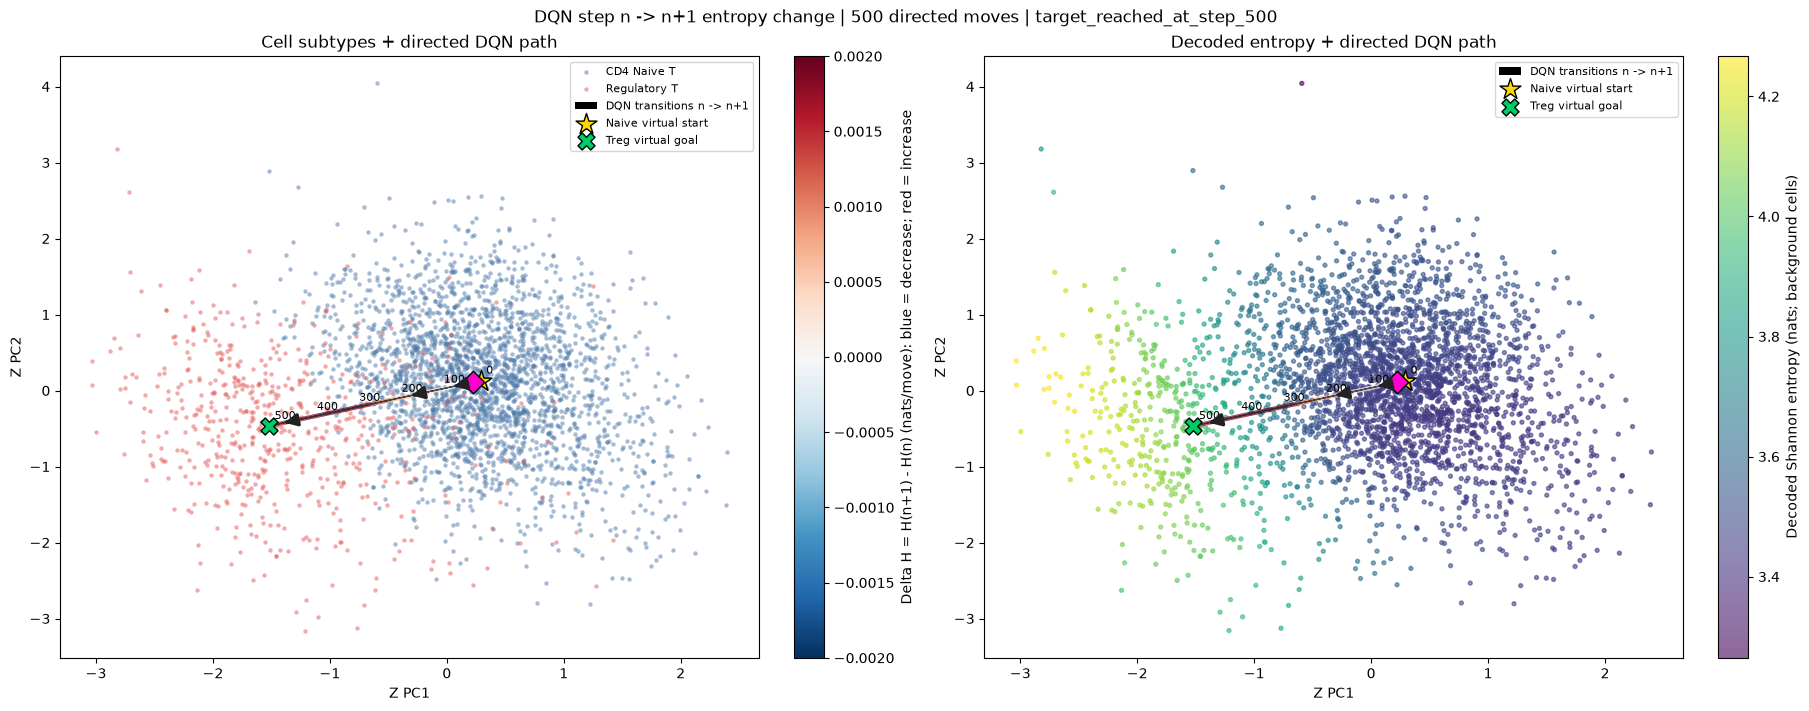

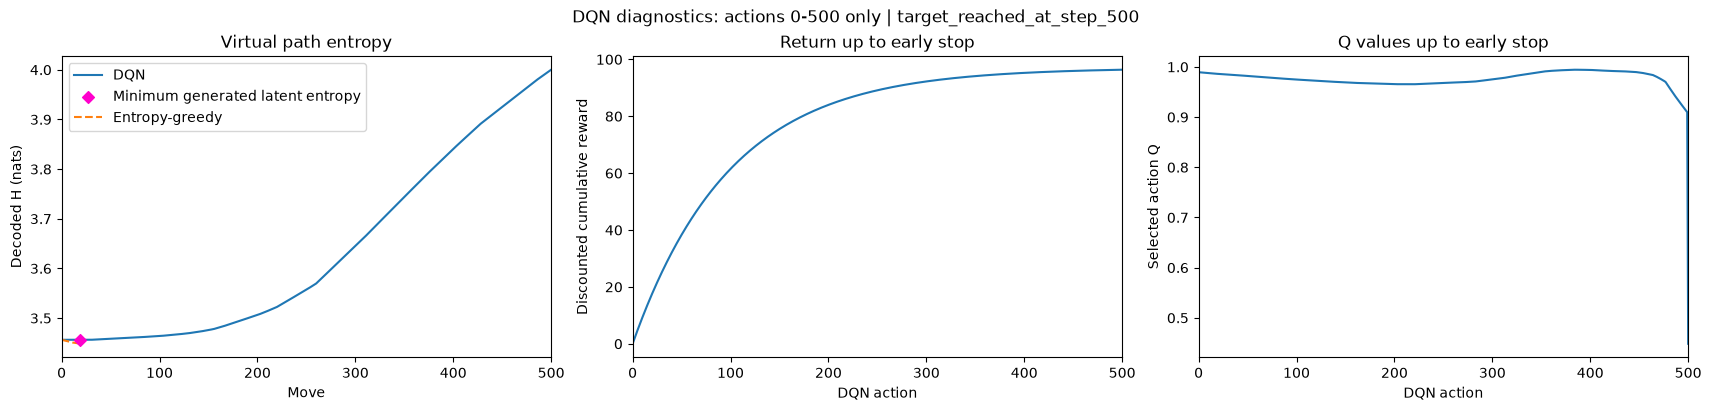

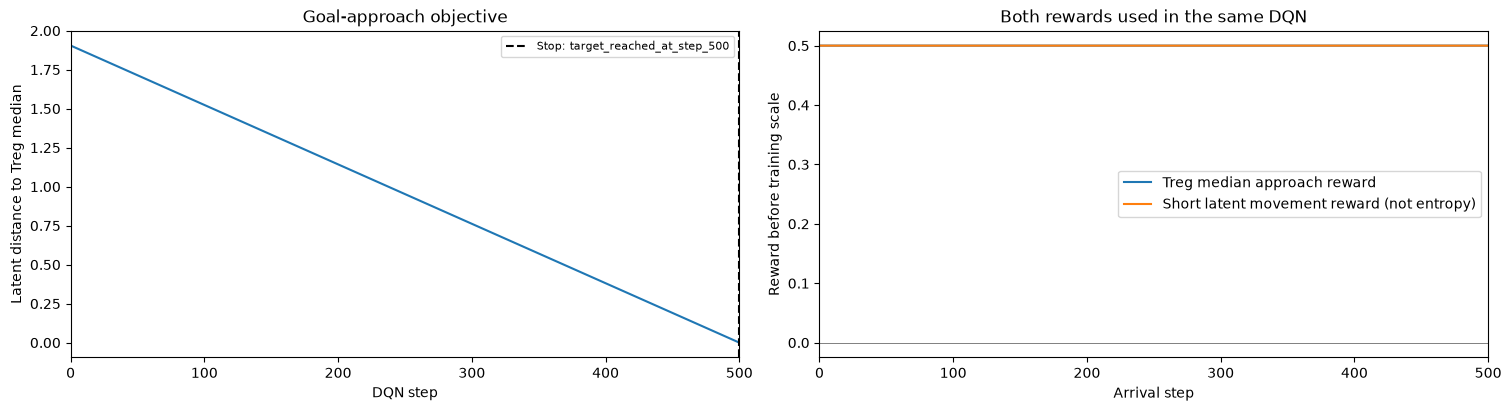

In [31]:
if globals().get('rl_trained_reward_version') != RL_REWARD_VERSION:
    raise RuntimeError('Run all section 5 setup, network initialization and training cells with the new reward before exporting section 6.')

@torch.no_grad()
def entropy_greedy_rollout():
    z = z_start_t[None].clone()
    h_min, t = decoded_entropy_t(z), torch.zeros(1, dtype=torch.long, device=DEVICE)
    path, entropies, rewards = [z[0].cpu().numpy()], [float(h_min)], []
    distance_history = (z_goal_t - z).norm(dim=1).repeat(RL_DISTANCE_PATIENCE + 1, 1)
    for _ in range(RL_MAX_STEPS):
        mask, moves, _ = action_mask(z, t)
        landing_entropy = decoded_entropy_t((z[:, None] + moves)[0]).masked_fill(~mask[0], torch.inf)
        if not mask.any():
            raise RuntimeError('No feasible virtual latent action during entropy-greedy rollout.')
        z, h, h_min, t, base, done = environment_step(z, h_min, t, landing_entropy.argmin()[None], moves, distance_history)
        path.append(z[0].cpu().numpy()); entropies.append(float(h)); rewards.append(float(base))
        if bool(done):
            break
    rewards = np.asarray(rewards)
    return {'path_z': np.asarray(path), 'entropy': np.asarray(entropies), 'base_rewards': rewards,
            'status': distance_stop_status(float((z_goal_t - z).norm()), int(t[0])),
            'base_return': float(np.sum(rewards * RL_GAMMA ** np.arange(len(rewards))))}


def trim_at_first_termination(result):
    path = np.asarray(result['path_z'])
    if path.ndim != 2 or path.shape[1] != LATENT_DIM or not np.isfinite(path).all():
        raise ValueError('Trajectory must contain finite 16D latent coordinates.')
    distances = torch.tensor(np.linalg.norm(path - z_goal, axis=1), device=DEVICE)
    distance_history = distances[:1].repeat(RL_DISTANCE_PATIENCE + 1, 1)
    stop_step = None
    for step in range(1, len(path)):
        if bool(distance_stop_state(distance_history, distances[step:step + 1], torch.tensor([step], device=DEVICE))[0]):
            stop_step = step
            break
    if stop_step is None:
        raise RuntimeError('Trajectory has not reached a goal, distance convergence, or step limit.')
    if not 1 <= stop_step <= RL_MAX_STEPS:
        raise ValueError(f'Invalid first termination step: {stop_step}')
    trimmed = dict(result)
    for key in ('path_z', 'entropy', 'support_distance'):
        if key in trimmed:
            if len(trimmed[key]) != len(path):
                raise ValueError(f'{key} must have one value per trajectory coordinate.')
            trimmed[key] = np.asarray(trimmed[key])[:stop_step + 1].copy()
    for key in ('actions', 'chosen_Q', 'base_rewards'):
        if key in trimmed:
            if len(trimmed[key]) != len(path) - 1:
                raise ValueError(f'{key} must have one value per trajectory action.')
            trimmed[key] = np.asarray(trimmed[key])[:stop_step].copy()
    trimmed['status'] = distance_stop_status(float(distances[stop_step]), stop_step)
    if 'base_rewards' in trimmed:
        trimmed['base_return'] = float(np.sum(trimmed['base_rewards'] * RL_GAMMA ** np.arange(stop_step)))
    elif stop_step != len(path) - 1:
        raise ValueError('Per-step rewards are required to truncate the trajectory return.')
    return trimmed


dqn_result = trim_at_first_termination(latent_rollout(latent_q))
policy_results = {'dqn': dqn_result,
                  'straight_goal_only': trim_at_first_termination(latent_rollout(None)),
                  'entropy_greedy': trim_at_first_termination(entropy_greedy_rollout())}
rl_actions = dqn_result['actions']
dqn_stop_step = len(rl_actions)
coordinate_space = dqn_result['path_z']
rl_path = np.arange(len(coordinate_space))
start_node, goal_node = 0, len(coordinate_space) - 1
coordinate_ids = np.array([f'vlatent_{step:04d}' for step in rl_path])
coordinate_pca = pca.transform(coordinate_space)
coordinate_entropy = dqn_result['entropy']
dqn_trajectory = {'path': rl_path, 'actions': rl_actions, 'status': dqn_result['status'],
                  'base_return': dqn_result['base_return']}
assert 1 <= len(rl_actions) <= RL_MAX_STEPS and len(coordinate_space) == len(rl_actions) + 1
assert dqn_result['status'] == distance_stop_status(float(np.linalg.norm(coordinate_space[-1] - z_goal)), dqn_stop_step)
goal_reached = bool(np.linalg.norm(coordinate_space[-1] - z_goal) <= RL_STEP_LENGTH * 1e-4)
print(f'DQN stopped at action {dqn_stop_step}/{RL_MAX_STEPS}: {dqn_result["status"]}; plotting {dqn_stop_step + 1} coordinates only.')
min_entropy_step = int(np.argmin(coordinate_entropy[1:])) + 1
observed_knn = NearestNeighbors(n_neighbors=REGION_SIZE).fit(Z_space)
support_distances, region_members = observed_knn.kneighbors(coordinate_space)
observed_raw_neighbors = observed_knn.kneighbors(Z_space, n_neighbors=REGION_SIZE + 1)[1]
observed_regions = np.array([np.r_[index, row[row != index][:REGION_SIZE - 1]] for index, row in enumerate(observed_raw_neighbors)])
observed_region_sq = np.sum((Z_space[observed_regions] - Z_space[observed_regions].mean(axis=1)[:, None]) ** 2, axis=2)
entropy_sigma = float(np.median(np.sqrt(observed_region_sq[observed_region_sq > 0])))
support_log_weights = -support_distances ** 2 / (2 * entropy_sigma ** 2)
support_weights = np.exp(support_log_weights - logsumexp(support_log_weights, axis=1, keepdims=True))
coordinate_treg_fraction = (support_weights * (cell_subtypes[region_members] == 'Regulatory T')).sum(axis=1)
coordinate_subtypes = np.where(coordinate_treg_fraction >= 0.5, 'Regulatory T', 'CD4 Naive T')
step_lengths = np.linalg.norm(np.diff(coordinate_space, axis=0), axis=1)
reward_distances = np.linalg.norm(z_goal - coordinate_space, axis=1)
reward_progress = RL_PROGRESS_WEIGHT * (reward_distances[:-1] - reward_distances[1:]) / RL_STEP_LENGTH
candidate_audit_frames, candidate_minima, candidate_maxima = [], [], []
for start in range(len(rl_actions)):
    stop = start + 1
    audit_z = torch.tensor(coordinate_space[start:stop], device=DEVICE)
    audit_t = torch.arange(start, stop, device=DEVICE)
    audit_mask, audit_moves, _ = action_mask(audit_z, audit_t)
    audit_h, audit_min, audit_max = candidate_entropies(audit_z, audit_moves, audit_mask)
    audit_landing = audit_z[:, None] + audit_moves
    audit_snap = (z_goal_t - audit_landing).norm(dim=2) <= RL_STEP_LENGTH * 1e-4
    audit_landing[audit_snap] = z_goal_t
    audit_move_lengths = (audit_landing - audit_z[:, None]).norm(dim=2)
    audit_scores = short_latent_move_reward(audit_move_lengths)
    audit_choices = torch.tensor(rl_actions[start:stop], device=DEVICE)
    audit_rows = torch.arange(stop - start, device=DEVICE)
    assert audit_mask[audit_rows, audit_choices].all()
    np.testing.assert_allclose(audit_h[audit_rows, audit_choices].cpu().numpy(),
                               coordinate_entropy[start + 1:stop + 1], atol=1e-6)
    candidate_minima.append(audit_min.cpu().numpy())
    candidate_maxima.append(audit_max.cpu().numpy())
    candidate_audit_frames.append(pd.DataFrame({
        'from_step': np.repeat(np.arange(start, stop), N_ACTIONS),
        'action': np.tile(action_names, stop - start),
        'feasible': audit_mask.cpu().numpy().ravel(),
        'candidate_entropy_nats': audit_h.cpu().numpy().ravel(),
        'candidate_latent_move_length': audit_move_lengths.cpu().numpy().ravel(),
        'short_latent_move_reward': audit_scores.cpu().numpy().ravel(),
        'selected': (torch.arange(N_ACTIONS, device=DEVICE)[None] == audit_choices[:, None]).cpu().numpy().ravel(),
    }))
reward_candidate_min = np.concatenate(candidate_minima)
reward_candidate_max = np.concatenate(candidate_maxima)
reward_short_move = short_latent_move_reward(torch.tensor(step_lengths, dtype=torch.float32, device=DEVICE)).cpu().numpy()
reward_goal = np.zeros(len(rl_actions))
if reward_distances[-1] <= RL_STEP_LENGTH * 1e-4:
    reward_goal[-1] = RL_GOAL_BONUS
reward_reconstructed = reward_progress + reward_short_move - RL_STEP_COST + reward_goal
np.testing.assert_allclose(reward_reconstructed, dqn_result['base_rewards'], atol=3e-4, rtol=3e-4)
dqn_trajectory_df = pd.DataFrame({
    'step': rl_path, 'coordinate_id': coordinate_ids,
    'estimated_subtype': coordinate_subtypes, 'estimated_treg_fraction': coordinate_treg_fraction,
    'decoded_entropy_nats': coordinate_entropy,
    'decoded_entropy_min_so_far': np.minimum.accumulate(coordinate_entropy),
    'delta_entropy_nats': np.r_[np.nan, np.diff(coordinate_entropy)],
    'distance_to_goal': reward_distances,
    'PC1': coordinate_pca[:, 0], 'PC2': coordinate_pca[:, 1],
    'step_length': np.r_[np.nan, step_lengths], 'support_distance_k5': support_distances[:, -1],
    'chosen_action': [action_names[action] for action in rl_actions] + [''],
    'chosen_Q': np.r_[dqn_result['chosen_Q'], np.nan],
    'arrival_progress_reward': np.r_[np.nan, reward_progress],
    'arrival_short_latent_move_reward': np.r_[np.nan, reward_short_move],
    'arrival_feasible_candidate_entropy_min': np.r_[np.nan, reward_candidate_min],
    'arrival_feasible_candidate_entropy_max': np.r_[np.nan, reward_candidate_max],
    'arrival_goal_bonus': np.r_[np.nan, reward_goal],
    'arrival_step_cost': np.r_[np.nan, np.full(len(rl_actions), -RL_STEP_COST)],
    'arrival_base_reward': np.r_[np.nan, dqn_result['base_rewards']],
    'arrival_training_reward': np.r_[np.nan, RL_REWARD_SCALE * dqn_result['base_rewards']],
})
baseline_rows = [{'policy': name, 'status': result['status'], 'moves': len(result['path_z']) - 1,
                  'discounted_base_return': result['base_return'], 'mean_path_entropy': float(result['entropy'].mean()),
                  'min_path_entropy': float(result['entropy'].min()), 'final_entropy': float(result['entropy'][-1]),
                  'min_generated_entropy': float(result['entropy'][1:].min()),
                  'min_generated_step': int(result['entropy'][1:].argmin()) + 1,
                  'final_distance_to_goal': float(np.linalg.norm(result['path_z'][-1] - z_goal)),
                  'entropy_decreasing_moves': int((np.diff(result['entropy']) < 0).sum())}
                 for name, result in policy_results.items()]
display(pd.DataFrame(baseline_rows))
display(dqn_trajectory_df.iloc[np.unique(np.r_[0:3, min_entropy_step, len(rl_path) - 3:len(rl_path)])])
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm
import matplotlib.patheffects as path_effects

path_delta_h = np.diff(coordinate_entropy)
path_displacements = np.diff(coordinate_pca, axis=0)
np.testing.assert_allclose(path_delta_h, dqn_trajectory_df['delta_entropy_nats'].iloc[1:])
if not np.isfinite(path_delta_h).all() or not np.isfinite(path_displacements).all():
    raise ValueError('Non-finite DQN transition entropy or PCA displacement.')
path_color_limit = max(float(np.abs(path_delta_h).max()), np.finfo(float).eps)
path_delta_norm = TwoSlopeNorm(vmin=-path_color_limit, vcenter=0, vmax=path_color_limit)
fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
for label, color in zip(SUBTYPES, ['#4C78A8', '#E45756']):
    selected = cell_subtypes == label
    axes[0].scatter(*Z_pca[selected].T, s=10, c=color, alpha=0.5, linewidths=0, label=label)
entropy_scatter = axes[1].scatter(*Z_pca.T, c=observed_decoded_entropy,
                                 s=8, cmap='viridis', alpha=0.6)
fig.colorbar(entropy_scatter, ax=axes[1], label='Decoded Shannon entropy (nats; background cells)')
path_arrow_artists = []
path_line_artists = []
path_segments = np.stack([coordinate_pca[:-1], coordinate_pca[1:]], axis=1)
for axis in axes:
    path_lines = LineCollection(path_segments, cmap='RdBu_r', norm=path_delta_norm,
        linewidths=3.0, label='_nolegend_', zorder=3)
    path_lines.set_array(path_delta_h)
    axis.add_collection(path_lines)
    path_line_artists.append(path_lines)
    path_arrows = axis.quiver(coordinate_pca[:-1, 0], coordinate_pca[:-1, 1],
        path_displacements[:, 0], path_displacements[:, 1], path_delta_h,
        angles='xy', scale_units='xy', scale=1, pivot='tail', cmap='RdBu_r', norm=path_delta_norm,
        width=0.004, minlength=0, headwidth=4, headlength=5, headaxislength=4.5,
        label='DQN transitions n -> n+1', zorder=4)
    path_arrows.set_path_effects([path_effects.Stroke(linewidth=0.7, foreground='#333333'),
                                  path_effects.Normal()])
    path_arrow_artists.append(path_arrows)
    axis.scatter(*coordinate_pca[0], marker='*', s=250, c='#FFD700', edgecolors='black', label='Naive virtual start', zorder=5)
    axis.scatter(*pca_median_xy[1], marker='X', s=150, c='#00CC66', edgecolors='black', label='Treg virtual goal', zorder=5)
    if not goal_reached:
        axis.scatter(*coordinate_pca[-1], marker='s', s=90, c='black', label=f'Early stop: step {dqn_stop_step}', zorder=6)
    axis.scatter(*coordinate_pca[min_entropy_step], marker='D', s=130, c='#FF00CC', edgecolors='black',
        label='_nolegend_', zorder=6)
    axis.set(xlabel='Z PC1', ylabel='Z PC2')
    for step in sorted(set(range(0, len(coordinate_pca), 100)) | {len(coordinate_pca) - 1}):
        axis.annotate(str(step), coordinate_pca[step], xytext=(4, 5), textcoords='offset points',
                      fontsize=8, zorder=7)
    axis.legend(fontsize=8, loc='upper right')
    for guide_start in (50, 150, 450):
        guide_end = guide_start + 20
        if guide_end >= len(coordinate_pca):
            continue
        axis.annotate('', xy=coordinate_pca[guide_end], xytext=coordinate_pca[guide_start],
            arrowprops={'arrowstyle': '-|>', 'color': '#222222', 'lw': 2.5, 'mutation_scale': 18}, zorder=8)
axes[0].set_title('Cell subtypes + directed DQN path')
axes[1].set_title('Decoded entropy + directed DQN path')
fig.colorbar(path_arrows, ax=axes[0],
    label='Delta H = H(n+1) - H(n) (nats/move): blue = decrease; red = increase')
np.testing.assert_allclose(entropy_scatter.get_array(), observed_decoded_entropy)
assert entropy_scatter.get_cmap().name == 'viridis'
np.testing.assert_allclose(axes[0].get_xlim(), axes[1].get_xlim())
np.testing.assert_allclose(axes[0].get_ylim(), axes[1].get_ylim())
for lines in path_line_artists:
    np.testing.assert_allclose(lines.get_array(), path_delta_h)
    np.testing.assert_allclose(lines.get_segments(), path_segments)
    assert lines.norm is path_delta_norm and lines.get_cmap().name == 'RdBu_r'
    assert len(lines.get_segments()) == len(rl_actions) <= RL_MAX_STEPS
for arrows in path_arrow_artists:
    np.testing.assert_allclose(arrows.get_array(), path_delta_h)
    np.testing.assert_allclose(np.column_stack([arrows.U, arrows.V]), path_displacements)
    np.testing.assert_allclose(arrows.get_offsets(), coordinate_pca[:-1])
    assert arrows.N == len(rl_actions) <= RL_MAX_STEPS
fig.suptitle(f'DQN step n -> n+1 entropy change | {len(rl_actions)} directed moves | {dqn_result["status"]}')
fig.savefig(RL_RESULT_DIR / 'dqn_coordinate_pca_path.png', dpi=180, bbox_inches='tight')
plt.show()
rl_history_df = pd.DataFrame(rl_history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
axes[0].plot(rl_path, coordinate_entropy, label='DQN')
axes[0].scatter(min_entropy_step, coordinate_entropy[min_entropy_step], c='#FF00CC', marker='D',
                label='Minimum generated latent entropy', zorder=5)
baseline_entropy_plot = policy_results['entropy_greedy']['entropy'][:dqn_stop_step + 1]
axes[0].plot(np.arange(len(baseline_entropy_plot)), baseline_entropy_plot, ls='--', label='Entropy-greedy')
axes[0].set(xlim=(0, dqn_stop_step), xlabel='Move', ylabel='Decoded H (nats)', title='Virtual path entropy')
assert all(np.max(line.get_xdata()) <= dqn_stop_step for line in axes[0].lines)
axes[0].legend()
path_discounted_return = np.r_[0.0, np.cumsum(dqn_result['base_rewards'] * RL_GAMMA ** np.arange(dqn_stop_step))]
np.testing.assert_allclose(path_discounted_return[-1], dqn_result['base_return'])
axes[1].plot(rl_path, path_discounted_return)
axes[1].set(xlabel='DQN action', ylabel='Discounted cumulative reward', title='Return up to early stop')
axes[2].plot(rl_path[1:], dqn_result['chosen_Q'])
axes[2].set(xlabel='DQN action', ylabel='Selected action Q', title='Q values up to early stop')
for axis in axes:
    axis.set_xlim(0, dqn_stop_step)
    for line in axis.lines:
        assert np.all((np.asarray(line.get_xdata()) >= 0) & (np.asarray(line.get_xdata()) <= dqn_stop_step))
fig.suptitle(f'DQN diagnostics: actions 0-{dqn_stop_step} only | {dqn_result["status"]}')
fig.savefig(RL_RESULT_DIR / 'dqn_coordinate_training_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
axes[0].plot(rl_path, reward_distances)
axes[0].axvline(dqn_stop_step, color='black', ls='--', label=f'Stop: {dqn_result["status"]}')
axes[0].legend(fontsize=8)
axes[0].set(xlim=(0, dqn_stop_step), xlabel='DQN step', ylabel='Latent distance to Treg median', title='Goal-approach objective')
axes[1].plot(rl_path[1:], reward_progress, label='Treg median approach reward')
axes[1].plot(rl_path[1:], reward_short_move, label='Short latent movement reward (not entropy)')
axes[1].axhline(0, color='grey', lw=0.7)
axes[1].set(xlim=(0, dqn_stop_step), xlabel='Arrival step', ylabel='Reward before training scale', title='Both rewards used in the same DQN')
axes[1].legend()
fig.savefig(RL_RESULT_DIR / 'dqn_joint_reward_components.png', dpi=180, bbox_inches='tight')
plt.show()
latent_columns = [f'Z{dimension + 1}' for dimension in range(LATENT_DIM)]
coordinate_path_export = pd.concat([dqn_trajectory_df, pd.DataFrame(coordinate_space, columns=latent_columns)], axis=1)
coordinate_path_export.to_csv(RL_RESULT_DIR / 'dqn_trajectory.csv', index=False)
pd.concat(candidate_audit_frames, ignore_index=True).to_csv(RL_RESULT_DIR / 'dqn_candidate_movement_audit.csv', index=False)
coordinate_path_export.iloc[[min_entropy_step]].to_csv(RL_RESULT_DIR / 'dqn_min_entropy_latent.csv', index=False)
rl_history_df.to_csv(RL_RESULT_DIR / 'dqn_training.csv', index=False)
pd.DataFrame(rl_episodes).to_csv(RL_RESULT_DIR / 'dqn_episodes.csv', index=False)
pd.DataFrame(baseline_rows).to_csv(RL_RESULT_DIR / 'policy_summary.csv', index=False)
np.savez_compressed(RL_RESULT_DIR / 'coordinate_graph.npz', Z_space=Z_space,
                    cell_barcodes=adata.obs_names.to_numpy(dtype=str), coordinate_space=coordinate_space,
                    coordinate_pca=coordinate_pca, region_members=region_members, support_weights=support_weights,
                    z_start=z_start, z_goal=z_goal, pca_median_xy=pca_median_xy, decoded_entropy=coordinate_entropy)
coordinate_run_config = {
    'start': 'inverse PCA of CD4 Naive T subtype median (virtual 16D coordinate)',
    'goal': 'inverse PCA of Regulatory T subtype median (virtual 16D coordinate)',
    'pca_median_xy': pca_median_xy.tolist(), 'z_start': z_start.tolist(), 'z_goal': z_goal.tolist(),
    'action_space': f'{N_ACTIONS} virtual latent actions: goal, away from goal, signed latent axes x lengths 0.5L and L; final goal step <= L',
    'state_space': 'continuous virtual 16D latent coordinates generated by actions; no cell graph',
    'step_length_cap_L': RL_STEP_LENGTH, 'latent_start_goal_distance': rl_total_distance,
    'minimum_moves': RL_MIN_MOVES, 'max_episode_moves': RL_MAX_STEPS,
    'termination': 'first goal arrival, best-distance improvement <= min_delta over patience moves, or max steps; no forced goal endpoint',
    'distance_patience': RL_DISTANCE_PATIENCE, 'distance_min_delta': RL_DISTANCE_MIN_DELTA,
    'goal_reached': goal_reached, 'final_distance_to_goal': float(reward_distances[-1]),
    'checkpoint_selection': 'maximum discounted joint reward over greedy evaluations with goal/convergence termination',
    'support_constraint': f'5th nearest observed cell <= {rl_support_radius:.6g} (q{RL_SUPPORT_QUANTILE}); goal action exempt',
    'reward_version': RL_REWARD_VERSION,
    'reward': 'progress_weight*(d_current-d_next)/L + short_move_weight*clip(1-||z_next-z_current||/L,0,1) - step_cost + goal_bonus*(first_goal_arrival)',
    'short_move_reward': '1 - ||z_next - z_current|| / L, clipped to [0,1]; actual snapped arrival displacement',
    'entropy_role': 'observational state feature and diagnostic only; excluded from reward',
    'move_fractions': list(RL_MOVE_FRACTIONS),
    'entropy': 'Shannon H of decoded expression p=expm1(max(decoder(z),0))/sum (nats)',
    'entropy_floor': rl_entropy_floor, 'entropy_scale': rl_entropy_scale,
    'progress_weight': RL_PROGRESS_WEIGHT, 'step_cost': RL_STEP_COST, 'short_move_weight': RL_SHORT_MOVE_WEIGHT,
    'goal_bonus': RL_GOAL_BONUS, 'reward_scale': RL_REWARD_SCALE, 'gamma': RL_GAMMA,
    'selected_checkpoint_vector_step': best_rl_step, 'status': dqn_trajectory['status'],
    'moves': len(rl_actions), 'path_observations': len(rl_path),
    'min_entropy_step': min_entropy_step, 'min_entropy_nats': float(coordinate_entropy[min_entropy_step]),
    'start_cell_barcode': start_barcode, 'goal_cell_barcode': end_barcode,
    'start_coordinate_id': coordinate_ids[0], 'end_coordinate_id': coordinate_ids[-1],
    'goal_coordinate_id': coordinate_ids[-1] if goal_reached else None,
    'minimum_search_scope': f'generated DQN trajectory steps 1-{len(rl_actions)}; not a global optimum guarantee',
    'tf_expression_method': 'Gaussian distance-weighted CP10K of nearest 5 measured cells, then log1p',
    'entropy_sigma': entropy_sigma,
}
(RL_RESULT_DIR / 'run_config.json').write_text(json.dumps(coordinate_run_config, indent=2))
torch.save({'vae': vae.state_dict(), 'latent_q': latent_q.state_dict(),
            'pca_components': pca.components_, 'pca_mean': pca.mean_}, RL_RESULT_DIR / 'coordinate_models.pt')

## 7. 학습된 가상 latent 경로 영상

저장된 학습 결과를 읽어 재학습 없이 영상을 생성합니다. 왼쪽은 기존 PCA의 가상 latent 경로, 오른쪽은 H, 관찰용 이동별 `ΔH[t] = H[t] − H[t−1]`, 동일 이동의 저장된 보상 `arrival_base_reward`입니다. **entropy는 보상에 포함하지 않습니다.** 보상은 목표거리 감소/L와 `1−실제 latent 이동량/L`의 1:1 합에 step cost·도착 보너스를 적용한 값입니다. 보상은 학습용 0.1 배율 적용 전 원래 값이고 누적 보상이 아닙니다. 최대 500회 이내 목표 도착·거리 수렴·최대 step 중 최초 종료까지의 실제 경로와 최소 H 좌표를 표시합니다. 목표 도착 보너스는 실제 도착한 경우에만 지급됩니다. 이전 entropy/34-action 모델을 사용하지 않으며 5절 새 보상과 68 actions로 재학습하고 6절에서 내보낸 v8 결과만 허용합니다.

각 값은 이동의 도착 스텝 t(1부터)에 정렬하며, 이동 전 시작점에는 변화량이나 보상을 만들지 않습니다. `MOVES_PER_FRAME`마다 프레임을 그리지만 그래프에는 그 시점까지의 모든 이동을 포함하고 마지막 이동을 항상 표시합니다.

영상은 `coordinate_dqn/dqn_latent_pca_transition.mp4`로 저장합니다. DQN step은 생물학적 시간이 아닙니다.

In [32]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import torch
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Video, display
import imageio_ffmpeg

VIDEO_DIR = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/coordinate_dqn')
VIDEO_PATH = VIDEO_DIR / 'dqn_latent_pca_transition.mp4'
VIDEO_FPS, MOVES_PER_FRAME = 24, 2
VIDEO_FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()
video_table = pd.read_csv(VIDEO_DIR / 'dqn_trajectory.csv')
video_config = json.loads((VIDEO_DIR / 'run_config.json').read_text())
if video_config.get('reward_version') != 'short_latent_move_goal_progress_distance_convergence_v8':
    raise ValueError('Saved results use an older algorithm. Run section 5 (DQN environment, components and training), then section 6 (export), before section 7. VAE/PCA retraining is not required.')
with np.load(VIDEO_DIR / 'coordinate_graph.npz', allow_pickle=False) as video_saved:
    video_cell_z = video_saved['Z_space'].copy()
    video_path_z = video_saved['coordinate_space'].copy()
    video_saved_xy = video_saved['coordinate_pca'].copy()
    video_barcodes = video_saved['cell_barcodes'].astype(str)
video_checkpoint = torch.load(VIDEO_DIR / 'coordinate_models.pt', map_location='cpu', weights_only=False)
video_components = np.asarray(video_checkpoint['pca_components'])
video_mean = np.asarray(video_checkpoint['pca_mean'])
del video_checkpoint
video_cell_xy = (video_cell_z - video_mean) @ video_components.T
video_xy = video_table[['PC1', 'PC2']].to_numpy()
video_entropy = video_table['decoded_entropy_nats'].to_numpy(dtype=float)
video_delta_entropy = np.diff(video_entropy)
video_rewards = video_table['arrival_base_reward'].to_numpy(dtype=float)[1:]
video_progress_reward = video_table['arrival_progress_reward'].to_numpy(dtype=float)[1:]
video_short_move_reward = video_table['arrival_short_latent_move_reward'].to_numpy(dtype=float)[1:]
video_goal_reward = video_table['arrival_goal_bonus'].to_numpy(dtype=float)[1:]
video_step_cost = video_table['arrival_step_cost'].to_numpy(dtype=float)[1:]
n_moves = len(video_table) - 1
if not 1 <= n_moves <= min(500, video_config['max_episode_moves']):
    raise ValueError('Expected 1 to 500 saved DQN moves, ending at goal arrival or distance convergence.')
if video_config['moves'] != n_moves:
    raise ValueError('Saved configuration and trajectory disagree about the termination step.')
video_move_steps = np.arange(1, n_moves + 1)
if n_moves < 1 or not np.array_equal(video_table['step'].to_numpy(), np.arange(n_moves + 1)):
    raise ValueError('Expected consecutive saved steps from zero.')
for values in (video_path_z, video_xy, video_entropy, video_rewards, video_progress_reward,
               video_short_move_reward, video_goal_reward, video_step_cost):
    if not np.isfinite(values).all():
        raise ValueError('Non-finite saved trajectory or reward.')
np.testing.assert_allclose(video_path_z, video_table[[f'Z{dimension + 1}' for dimension in range(16)]], atol=1e-6)
np.testing.assert_allclose(video_xy, video_saved_xy, atol=1e-5, rtol=1e-4)
np.testing.assert_allclose((video_path_z - video_mean) @ video_components.T, video_xy, atol=1e-5, rtol=1e-4)
video_move_lengths = np.linalg.norm(np.diff(video_path_z, axis=0), axis=1)
np.testing.assert_allclose(video_short_move_reward,
    video_config['short_move_weight'] * np.clip(1 - video_move_lengths / video_config['step_length_cap_L'], 0, 1), atol=1e-5)
np.testing.assert_allclose(video_rewards, video_progress_reward + video_short_move_reward + video_goal_reward + video_step_cost, atol=3e-4, rtol=3e-4)
video_distances = np.linalg.norm(video_path_z - np.asarray(video_config['z_goal']), axis=1)
video_goal_reached = bool(video_distances[-1] <= video_config['step_length_cap_L'] * 1e-4)
video_best_distances = np.minimum.accumulate(video_distances)
video_patience = video_config['distance_patience']
video_stops = video_distances <= video_config['step_length_cap_L'] * 1e-4
video_stops[video_patience:] |= video_best_distances[:-video_patience] - video_best_distances[video_patience:] <= video_config['distance_min_delta']
video_stops |= np.arange(n_moves + 1) >= video_config['max_episode_moves']
if np.flatnonzero(video_stops).tolist() != [n_moves]:
    raise ValueError('Saved trajectory must end at its first goal/convergence/limit termination.')
video_stop_reason = 'target_reached' if video_goal_reached else ('max_steps' if n_moves >= video_config['max_episode_moves'] else 'distance_converged')
if video_config['status'] != f'{video_stop_reason}_at_step_{n_moves}' or video_config['goal_reached'] != video_goal_reached:
    raise ValueError('Saved termination reason does not match the actual endpoint.')
if (video_distances[:-1] <= video_config['step_length_cap_L'] * 1e-4).any():
    raise ValueError('Saved trajectory continues after its first goal arrival.')
np.testing.assert_allclose(video_table['distance_to_goal'], video_distances, atol=1e-6)
np.testing.assert_allclose(video_table['delta_entropy_nats'].iloc[1:], video_delta_entropy, atol=1e-6)
video_expected_goal_reward = np.zeros(n_moves)
if video_goal_reached:
    video_expected_goal_reward[-1] = video_config['goal_bonus']
np.testing.assert_allclose(video_goal_reward, video_expected_goal_reward, atol=1e-6)
np.testing.assert_allclose(video_step_cost, -video_config['step_cost'], atol=1e-6)
np.testing.assert_allclose(video_progress_reward, -video_config['progress_weight'] * np.diff(video_distances) / video_config['step_length_cap_L'], atol=3e-4, rtol=3e-4)
if np.linalg.norm(np.diff(video_path_z, axis=0), axis=1).max() > video_config['step_length_cap_L'] * (1 + 1e-4):
    raise ValueError('Latent action exceeded the saved step cap.')
video_variance_ratio = np.var(video_cell_xy, axis=0, ddof=1) / np.var(video_cell_z, axis=0, ddof=1).sum()
video_source = sc.read_h5ad('/home/Data_Drive_8TB/kykim/8. RL/tdata_sub.h5ad', backed='r')
try:
    video_cell_subtypes = video_source.obs.loc[video_barcodes, 'subtype'].astype(str).to_numpy()
finally:
    video_source.file.close()
frame_schedule = np.r_[np.zeros(VIDEO_FPS, dtype=int),
                       np.unique(np.r_[np.arange(0, len(video_table), MOVES_PER_FRAME), n_moves]),
                       np.full(2 * VIDEO_FPS, n_moves, dtype=int)]
video_fig = plt.figure(figsize=(17, 10), constrained_layout=True)
video_grid = video_fig.add_gridspec(3, 2, width_ratios=[1.7, 1])
video_ax = video_fig.add_subplot(video_grid[:, 0])
entropy_ax = video_fig.add_subplot(video_grid[0, 1])
delta_ax = video_fig.add_subplot(video_grid[1, 1], sharex=entropy_ax)
reward_ax = video_fig.add_subplot(video_grid[2, 1], sharex=entropy_ax)
for label, color in [('CD4 Naive T', '#4C78A8'), ('Regulatory T', '#E45756')]:
    selected = video_cell_subtypes == label
    video_ax.scatter(*video_cell_xy[selected].T, s=9, c=color, alpha=0.35, label=label, zorder=1)
video_ax.scatter(*video_xy[0], marker='*', s=230, c='#FFD700', edgecolors='black', label='Naive virtual start', zorder=5)
video_goal_xy = np.asarray(video_config['pca_median_xy'])[1]
video_ax.scatter(*video_goal_xy, marker='X', s=130, c='#00CC66', edgecolors='black', label='Treg median goal', zorder=5)
trail, = video_ax.plot([], [], '-', c='#222222', lw=1.8, zorder=3)
current_cell = video_ax.scatter(*video_xy[0], s=95, c='#FFD700', edgecolors='black', zorder=6)
video_minimum = video_ax.scatter([], [], marker='D', s=110, c='#FF00CC', edgecolors='black',
                                 label='_nolegend_', zorder=6)
status_text = video_ax.text(0.02, 0.98, '', transform=video_ax.transAxes, va='top', fontsize=9,
                           bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9}, zorder=7)
video_ax.set(xlabel=f'Z PC1 ({video_variance_ratio[0]:.1%})', ylabel=f'Z PC2 ({video_variance_ratio[1]:.1%})',
             title='Learned DQN: generated 16D latent coordinates on fixed PCA')
video_ax.legend(loc='lower left', fontsize=8)
video_series = []
for axis, values, color, label in [
    (entropy_ax, video_entropy, '#4C78A8', 'Decoded H'),
    (delta_ax, video_delta_entropy, '#E45756', 'Delta H = H[next] - H[current]'),
    (reward_ax, video_rewards, '#222222', 'Total'),
    (reward_ax, video_progress_reward, '#59A14F', 'Treg approach'),
    (reward_ax, video_short_move_reward, '#B07AA1', 'Short latent movement'),
    (reward_ax, video_goal_reward, '#F28E2B', 'Arrival bonus'),
    (reward_ax, video_step_cost, '#999999', 'Step cost'),
]:
    line, = axis.plot([], [], color=color, lw=1.4, label=label)
    video_series.append((line, values, axis is entropy_ax))
for axis, values, ylabel in [
    (entropy_ax, video_entropy, 'Decoded Shannon H (nats)'),
    (delta_ax, video_delta_entropy, 'Delta H (nats / move)'),
    (reward_ax, np.concatenate([video_rewards, video_progress_reward, video_short_move_reward, video_goal_reward, video_step_cost]), 'Reward per move (unscaled)'),
]:
    lower, upper = float(values.min()), float(values.max())
    if axis is not entropy_ax:
        lower, upper = min(lower, 0), max(upper, 0)
        axis.axhline(0, c='#777777', lw=0.8, ls='--')
    margin = max((upper - lower) * 0.12, 1e-8)
    axis.set(xlim=(-0.5, n_moves + 0.5), ylim=(lower - margin, upper + margin), ylabel=ylabel, xlabel='Arrival move')
    axis.grid(alpha=0.2)
    axis.legend(fontsize=8, ncol=2 if axis is reward_ax else 1)
video_fig.suptitle(f'{n_moves} virtual latent moves | {video_config["status"]} | approach + short latent movement rewards')


def update_pca_video(step: int):
    trail.set_data(video_xy[:step + 1, 0], video_xy[:step + 1, 1])
    current_cell.set_offsets(video_xy[step:step + 1])
    video_best_step = int(video_entropy[1:step + 1].argmin()) + 1 if step else None
    video_minimum.set_offsets(video_xy[video_best_step:video_best_step + 1] if step else np.empty((0, 2)))
    for line, values, is_state in video_series:
        count = step + 1 if is_state else step
        line.set_data(np.arange(count) if is_state else video_move_steps[:count], values[:count])
    status = video_config['status'] if step == n_moves else 'Moving'
    current_cell.set_facecolor('black' if step == n_moves and not video_goal_reached else '#FFD700')
    transition_text = (f'Delta H={video_delta_entropy[step - 1]:+.6f} nats\n'
                       f'Approach={video_progress_reward[step - 1]:+.4f}; short_move={video_short_move_reward[step - 1]:+.4f}\n'
                       f'Arrival bonus={video_goal_reward[step - 1]:+.1f}; total={video_rewards[step - 1]:+.4f}'
                       if step else 'Start: no transition or reward yet')
    status_text.set_text(f'Move {step}/{n_moves} | {status}\n'
                         f'{video_table.coordinate_id.iloc[step]} | H={video_entropy[step]:.6f}\n'
                         f'Latent distance to Treg={video_table.distance_to_goal.iloc[step]:.5f}\n'
                         f'{transition_text}')
    return trail, current_cell, video_minimum, status_text, *(item[0] for item in video_series)


for video_check_step in (0, 1, n_moves):
    update_pca_video(video_check_step)
    for line, values, is_state in video_series:
        count = video_check_step + 1 if is_state else video_check_step
        np.testing.assert_allclose(line.get_ydata(), values[:count])
pca_animation = animation.FuncAnimation(video_fig, update_pca_video, frames=frame_schedule,
                                        interval=1000 / VIDEO_FPS, blit=False, repeat=False)
video_writer = animation.FFMpegWriter(fps=VIDEO_FPS, codec='libx264', bitrate=2400,
                                      extra_args=['-pix_fmt', 'yuv420p', '-movflags', '+faststart', '-threads', '2'])
try:
    with plt.rc_context({'animation.ffmpeg_path': VIDEO_FFMPEG}):
        pca_animation.save(str(VIDEO_PATH), writer=video_writer, dpi=100)
finally:
    plt.close(video_fig)
video_decode = subprocess.run([VIDEO_FFMPEG, '-v', 'error', '-xerror', '-i', str(VIDEO_PATH),
                               '-progress', 'pipe:1', '-nostats', '-f', 'null', '-'],
                              check=True, capture_output=True, text=True)
video_decoded_frames = [int(line.split('=', 1)[1]) for line in video_decode.stdout.splitlines() if line.startswith('frame=')]
assert video_decoded_frames[-1] == len(frame_schedule)
(VIDEO_DIR / 'video_metadata.json').write_text(json.dumps({
    'reward_version': video_config['reward_version'], 'frames': len(frame_schedule), 'fps': VIDEO_FPS,
    'moves': n_moves, 'minimum_generated_entropy_step': int(video_entropy[1:].argmin()) + 1,
    'status': video_config['status'], 'goal_reached': video_goal_reached,
    'distance_patience': video_config['distance_patience'], 'distance_min_delta': video_config['distance_min_delta'],
    'duration_seconds': len(frame_schedule) / VIDEO_FPS,
    'display': 'saved virtual 16D path on original PCA; H, delta H, separate rewards and total',
    'validation': 'reward reconstruction, coordinate projection, all frames decoded and counted',
}, indent=2))
display(Video(str(VIDEO_PATH), embed=True, html_attributes='controls loop'))

## 8. 좌표 경로의 TF 변동 순위와 latent decoder 발현 히트맵

TF 목록: https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt

경로는 실제 세포가 아닌 가상 Z 좌표이며 early stop까지의 DQN step 0–종료 step만 사용합니다. **첫 번째 figure**는 TF 목록과 원래 VAE 출력 유전자의 교집합 전체를 대상으로, 각 TF의 step별 **decoded 발현 표본분산(variance, ddof=1) 상위 10개를 내림차순**으로 표시합니다. 분산은 유전자별 percentage 정규화 전 decoder 원출력(log1p CP10K scale)에 대해 계산하며, 값이 클수록 경로를 따라 발현 변동이 큽니다. 동점은 TF 이름순입니다. 전체 순위는 `dqn_path_tf_decoded_variance_ranking.csv`에 저장합니다. 기존 이웃 기반 분산 순위 파일과 entropy 순위 파일은 보존하지만 이 두 figure의 순위에는 사용하지 않습니다.

**두 번째 figure의 하단 히트맵**은 각 DQN step의 latent Z 좌표를 저장된 원래 VAE decoder에 직접 입력한 발현을 **유전자별 min–max percentage**로 표시합니다. 각 유전자의 경로 내 최소 발현은 0%(흰색), 최대 발현은 100%(빨강)이며 `(expression - gene_min) / (gene_max - gene_min) * 100`으로 계산합니다. 경로 내 발현이 일정한 유전자는 변동 없음으로 0% 표시하고 목록을 출력합니다. 이는 유전자 간 절대 발현 비교나 전체 발현 중 비율이 아닙니다. Shannon entropy, z-score, smoothing, clipping은 적용하지 않습니다.

**두 번째 figure**는 첫 번째 figure에서 선정한 **동일한 상위 10 TF를 동일한 variance 순서**로 표시합니다. Decoder에 없는 TF를 이웃 발현으로 대체하지 않습니다. Decoder 원출력(log1p CP10K scale)은 `dqn_path_top_tf_decoded_expression.csv`로 저장하고 표시용 percentage는 `dqn_path_top_tf_decoded_percentage.csv`에 별도로 저장합니다. 저장된 latent 경로 및 decoder baseline 재현 여부, variance 순위와 실제 히트맵 배열·CSV의 일치 여부를 검증합니다.

**상단 비율 띠**는 Z 공간 최근접 실제 세포 **10개**의 단순 개수 비율(`Treg 수 / 10`)입니다. 0=파랑(Naive 100%), 0.5=흰색, 1=빨강(Treg 100%)이며 거리 가중치나 다수결 이진 라벨을 사용하지 않습니다. 띠와 범례 높이를 키우고 범례 글자는 12pt로 표시합니다. 이웃 10개는 색상 띠에만 사용하며 TF 순위와 하단 발현값은 decoder로만 계산합니다.

DQN step은 생물학적 시간이 아니며, 공간 보간에 따른 변화는 인과관계나 실제 분화를 증명하지 않습니다.

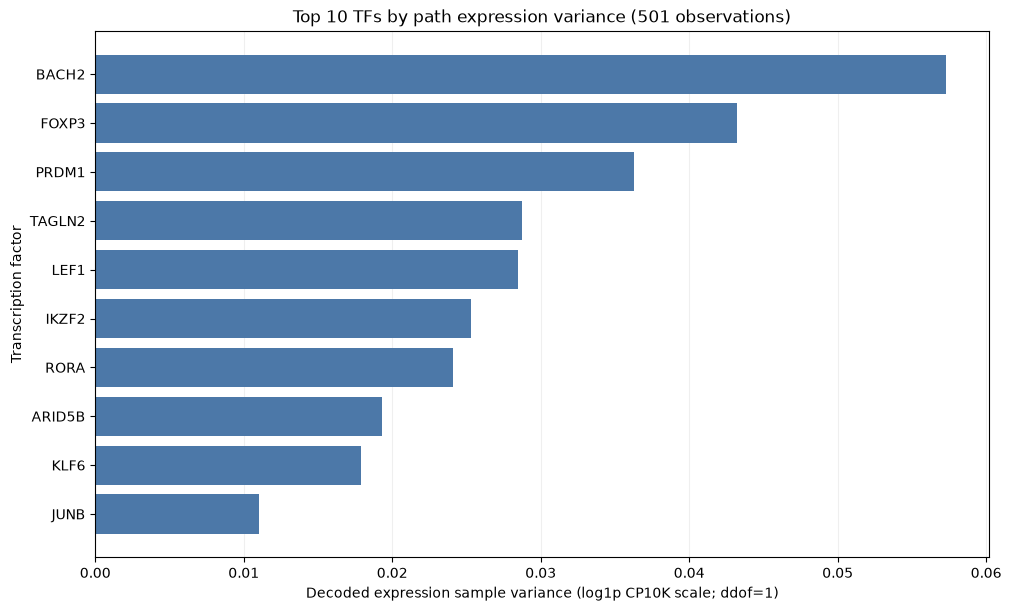

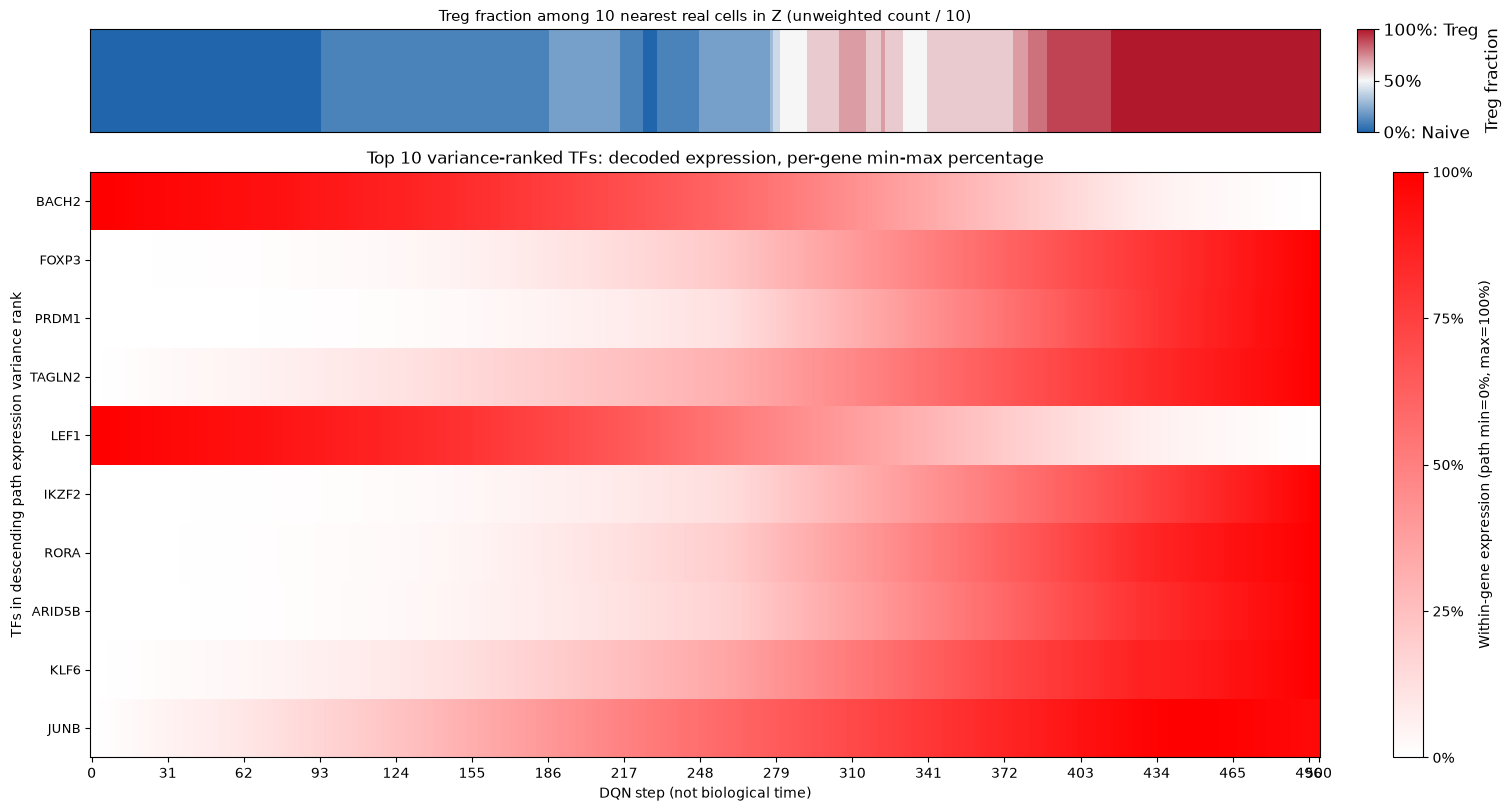

,rank,TF,variance
0,1,BACH2,0.057323
1,2,FOXP3,0.043230
2,3,PRDM1,0.036298
3,4,TAGLN2,0.028719
4,5,LEF1,0.028456
5,6,IKZF2,0.025318
6,7,RORA,0.024084
7,8,ARID5B,0.019333
8,9,KLF6,0.017926
9,10,JUNB,0.011008


In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.neighbors import NearestNeighbors
import scanpy as sc

TF_RESULT_DIR = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/coordinate_dqn')
TF_VARIANCE_TOP_N = 10
tf_variance_symbols = pd.Index((TF_RESULT_DIR.parent / 'allTFs_hg38.txt').read_text().split())
tf_plot_path = pd.read_csv(TF_RESULT_DIR / 'dqn_trajectory.csv')
TF_ANNOTATION_K = 10
with np.load(TF_RESULT_DIR / 'coordinate_graph.npz', allow_pickle=False) as tf_plot_graph:
    tf_plot_cell_z = tf_plot_graph['Z_space'].copy()
    tf_plot_cell_barcodes = tf_plot_graph['cell_barcodes'].astype(str)
    tf_plot_saved_path_z = tf_plot_graph['coordinate_space'].copy()
tf_plot_latent_columns = [f'Z{dimension + 1}' for dimension in range(tf_plot_cell_z.shape[1])]
tf_plot_query = tf_plot_path[tf_plot_latent_columns].to_numpy(dtype=np.float32)
np.testing.assert_allclose(tf_plot_query, tf_plot_saved_path_z, atol=1e-6)
if not np.array_equal(tf_plot_path['step'].to_numpy(), np.arange(len(tf_plot_path))):
    raise ValueError('Expected consecutive DQN steps starting at zero.')

tf_decoder_checkpoint = torch.load(TF_RESULT_DIR / 'coordinate_models.pt', map_location='cpu', weights_only=False)
with np.load(TF_RESULT_DIR.parent / 'ikzf2_latent_counterfactual/latent_counterfactual.npz', allow_pickle=False) as tf_decoder_reference:
    tf_decoder_symbols = tf_decoder_reference['gene_symbols'].astype(str)
    tf_decoder_reference_z = tf_decoder_reference['z_original'].astype(np.float32)
    tf_decoder_reference_expression = tf_decoder_reference['baseline_decoded'].copy()
if len(np.unique(tf_decoder_symbols)) != len(tf_decoder_symbols):
    raise ValueError('Decoder feature symbols must be unique.')
tf_decoder_state = {key.removeprefix('decoder.'): value for key, value in tf_decoder_checkpoint['vae'].items()
                    if key.startswith('decoder.')}
tf_path_decoder = nn.Sequential(
    nn.Linear(tf_decoder_state['0.weight'].shape[1], tf_decoder_state['0.weight'].shape[0]), nn.ReLU(),
    nn.Linear(tf_decoder_state['2.weight'].shape[1], tf_decoder_state['2.weight'].shape[0]), nn.ReLU(),
    nn.Linear(tf_decoder_state['4.weight'].shape[1], tf_decoder_state['4.weight'].shape[0]),
)
tf_path_decoder.load_state_dict(tf_decoder_state)
tf_path_decoder.eval().requires_grad_(False)
if len(tf_decoder_symbols) != tf_decoder_state['4.weight'].shape[0]:
    raise ValueError('Saved gene mapping does not match the original decoder output dimension.')
with torch.no_grad():
    np.testing.assert_allclose(tf_path_decoder(torch.from_numpy(tf_decoder_reference_z)).numpy(),
                               tf_decoder_reference_expression, rtol=1e-5, atol=1e-5)
    tf_path_decoded = np.concatenate([
        tf_path_decoder(torch.from_numpy(tf_plot_query[start:start + 256])).numpy()
        for start in range(0, len(tf_plot_query), 256)
    ])
if not np.isfinite(tf_path_decoded).all():
    raise ValueError('Non-finite decoded path expression.')
tf_variance_positions = np.flatnonzero(pd.Index(tf_decoder_symbols).isin(tf_variance_symbols))
if not len(tf_variance_positions):
    raise ValueError('No TF from allTFs_hg38.txt has an output in the original VAE decoder.')
if len(tf_plot_path) < 2:
    raise ValueError('Path expression sample variance requires at least two observations.')
tf_variance_expression = tf_path_decoded[:, tf_variance_positions].astype(np.float64)
tf_variance_scores = tf_variance_expression.var(axis=0, ddof=1)
tf_plot_ranking = pd.DataFrame({
    'TF': tf_decoder_symbols[tf_variance_positions],
    'variance': tf_variance_scores,
}).sort_values(['variance', 'TF'], ascending=[False, True], kind='stable').reset_index(drop=True)
if len(tf_plot_ranking) < TF_VARIANCE_TOP_N:
    raise ValueError(f'Expected at least {TF_VARIANCE_TOP_N} decoder-available TFs.')
tf_plot_ranking.insert(0, 'rank', np.arange(1, len(tf_plot_ranking) + 1))
tf_plot_top = tf_plot_ranking.head(TF_VARIANCE_TOP_N).copy()
tf_decoder_top = tf_plot_top.copy()
tf_plot_ranking.to_csv(TF_RESULT_DIR / 'dqn_path_tf_decoded_variance_ranking.csv', index=False)
tf_decoder_top_positions = pd.Index(tf_decoder_symbols).get_indexer(tf_decoder_top['TF'])
tf_heat_decoded_expression = tf_path_decoded[:, tf_decoder_top_positions].T
tf_heat_gene_min = tf_heat_decoded_expression.min(axis=1, keepdims=True)
tf_heat_gene_span = np.ptp(tf_heat_decoded_expression, axis=1, keepdims=True)
tf_heat_percentage = np.divide(tf_heat_decoded_expression - tf_heat_gene_min, tf_heat_gene_span,
                                out=np.zeros_like(tf_heat_decoded_expression), where=tf_heat_gene_span > 0) * 100
tf_heat_constant_genes = tf_decoder_top.loc[tf_heat_gene_span.ravel() == 0, 'TF'].tolist()
if tf_heat_constant_genes:
    print(f'Constant-expression TFs displayed as 0% (no within-gene variation): {tf_heat_constant_genes}')

tf_annotation_distances, tf_annotation_members = NearestNeighbors(n_neighbors=TF_ANNOTATION_K).fit(tf_plot_cell_z).kneighbors(tf_plot_query)
tf_plot_source = sc.read_h5ad('/home/Data_Drive_8TB/kykim/8. RL/tdata_sub.h5ad', backed='r')
try:
    tf_plot_cell_types = tf_plot_source.obs.loc[tf_plot_cell_barcodes, 'subtype'].astype(str).to_numpy()
finally:
    tf_plot_source.file.close()
if not np.isin(tf_plot_cell_types, ['CD4 Naive T', 'Regulatory T']).all():
    raise ValueError('Unexpected subtype in the saved reference cells.')
tf_annotation_treg_count = (tf_plot_cell_types[tf_annotation_members] == 'Regulatory T').sum(axis=1)
tf_annotation_treg_fraction = tf_annotation_treg_count / TF_ANNOTATION_K

fig, ax = plt.subplots(figsize=(10, max(6, 0.28 * len(tf_decoder_top))), constrained_layout=True)
tf_bar_order = tf_decoder_top.iloc[::-1]
ax.barh(tf_bar_order['TF'], tf_bar_order['variance'], color='#4C78A8')
ax.set(xlabel='Decoded expression sample variance (log1p CP10K scale; ddof=1)', ylabel='Transcription factor',
       title=f'Top {len(tf_decoder_top)} TFs by path expression variance ({len(tf_plot_path)} observations)')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.savefig(TF_RESULT_DIR / 'dqn_path_top_tf_variability.png', dpi=180, bbox_inches='tight')
plt.show()

tf_ratio_cmap = LinearSegmentedColormap.from_list('naive_to_treg_ratio', ['#2166AC', '#F7F7F7', '#B2182B'])
fig, (type_ax, heat_ax) = plt.subplots(2, 1, figsize=(15, max(8, 0.28 * len(tf_decoder_top))),
                                      gridspec_kw={'height_ratios': [1.4, 8]}, sharex=True,
                                      constrained_layout=True)
type_image = type_ax.imshow(tf_annotation_treg_fraction[None, :], cmap=tf_ratio_cmap,
                           vmin=0, vmax=1, aspect='auto', interpolation='nearest')
type_ax.set_yticks([])
type_ax.tick_params(axis='x', bottom=False, labelbottom=False)
type_ax.set_title('Treg fraction among 10 nearest real cells in Z (unweighted count / 10)', fontsize=11)
tf_ratio_colorbar = fig.colorbar(type_image, ax=type_ax, ticks=[0, 0.5, 1], fraction=0.08, pad=0.02, aspect=6)
tf_ratio_colorbar.ax.set_yticklabels(['0%: Naive', '50%', '100%: Treg'])
tf_ratio_colorbar.ax.tick_params(labelsize=12)
tf_ratio_colorbar.set_label('Treg fraction', fontsize=12)
tf_expression_cmap = LinearSegmentedColormap.from_list('white_to_red', ['#FFFFFF', '#FF0000'])
heat_image = heat_ax.imshow(tf_heat_percentage, cmap=tf_expression_cmap, vmin=0, vmax=100,
                            aspect='auto', interpolation='nearest')
heat_ax.set_yticks(np.arange(len(tf_decoder_top)), labels=tf_decoder_top['TF'].tolist(), fontsize=9)
tick_steps = np.unique(np.r_[np.arange(0, len(tf_plot_path), max(1, len(tf_plot_path) // 16)), len(tf_plot_path) - 1])
heat_ax.set_xticks(tick_steps, labels=tick_steps)
heat_ax.set(xlabel='DQN step (not biological time)', ylabel='TFs in descending path expression variance rank')
heat_ax.set_title(f'Top {len(tf_decoder_top)} variance-ranked TFs: decoded expression, per-gene min-max percentage')
tf_expression_colorbar = fig.colorbar(heat_image, ax=heat_ax, ticks=[0, 25, 50, 75, 100],
                                    label='Within-gene expression (path min=0%, max=100%)')
tf_expression_colorbar.ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%'])
fig.savefig(TF_RESULT_DIR / 'dqn_path_top_tf_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

tf_decoded_export = pd.DataFrame(tf_heat_decoded_expression.T, columns=tf_decoder_top['TF'].tolist(),
                                  index=pd.Index(tf_plot_path['step'], name='DQN_step'))
tf_decoded_export.to_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_expression.csv')
pd.DataFrame(tf_heat_percentage.T, columns=tf_decoder_top['TF'].tolist(),
             index=tf_decoded_export.index).to_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_percentage.csv')
pd.DataFrame({'step': tf_plot_path['step'], 'coordinate_id': tf_plot_path['coordinate_id'],
              'nearest10_Treg_count': tf_annotation_treg_count,
              'nearest10_Treg_fraction': tf_annotation_treg_fraction}).to_csv(
    TF_RESULT_DIR / 'dqn_path_decoded_tf_neighborhood10.csv', index=False)
np.testing.assert_allclose(type_image.get_array().data.ravel(), tf_annotation_treg_fraction)
np.testing.assert_allclose(heat_image.get_array().data, tf_heat_percentage)

display(tf_plot_top)

In [34]:
assert np.isfinite(tf_heat_decoded_expression).all()
assert tf_heat_decoded_expression.shape == (len(tf_decoder_top), len(tf_plot_path))
with torch.no_grad():
    tf_checked_decoded = tf_path_decoder(torch.from_numpy(tf_plot_query)).numpy()
np.testing.assert_allclose(tf_heat_decoded_expression,
                           tf_checked_decoded[:, tf_decoder_top_positions].T, rtol=1e-5, atol=1e-5)
np.testing.assert_allclose(heat_image.get_array().data, tf_heat_percentage)
np.testing.assert_allclose(type_image.get_array().data.ravel(), tf_annotation_treg_fraction)
assert heat_image.get_cmap().name == 'white_to_red'
np.testing.assert_allclose(heat_image.get_cmap()(0.0)[:3], [1, 1, 1])
np.testing.assert_allclose(heat_image.get_cmap()(1.0)[:3], [1, 0, 0])
np.testing.assert_allclose(heat_image.get_clim(), [0, 100])
np.testing.assert_allclose(tf_heat_percentage.min(axis=1), 0, atol=1e-5)
np.testing.assert_allclose(tf_heat_percentage.max(axis=1)[tf_heat_gene_span.ravel() > 0], 100, atol=1e-5)
assert tf_bar_order['TF'].tolist() == tf_decoder_top['TF'].iloc[::-1].tolist()
np.testing.assert_allclose([bar.get_width() for bar in ax.patches], tf_bar_order['variance'])
tf_saved_percentage = pd.read_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_percentage.csv', index_col='DQN_step')
assert tf_saved_percentage.columns.tolist() == tf_decoder_top['TF'].tolist()
np.testing.assert_array_equal(tf_saved_percentage.index, tf_plot_path['step'])
np.testing.assert_allclose(tf_saved_percentage.to_numpy().T, tf_heat_percentage, rtol=1e-6, atol=1e-5)
tf_expected_top = tf_plot_ranking.head(TF_VARIANCE_TOP_N)
pd.testing.assert_frame_equal(tf_plot_top, tf_expected_top)
assert tf_decoder_top['TF'].tolist() == tf_expected_top['TF'].tolist()
assert len(tf_decoder_top) == TF_VARIANCE_TOP_N == 10
assert tf_plot_ranking['TF'].is_unique and tf_plot_ranking['variance'].is_monotonic_decreasing
assert (tf_plot_ranking['variance'] >= 0).all()
tf_checked_variance = pd.DataFrame(tf_checked_decoded[:, tf_variance_positions].astype(np.float64),
                                   columns=tf_decoder_symbols[tf_variance_positions]).var(axis=0, ddof=1)
np.testing.assert_allclose(tf_plot_ranking['variance'], tf_checked_variance.loc[tf_plot_ranking['TF']], atol=1e-8)
tf_saved_ranking = pd.read_csv(TF_RESULT_DIR / 'dqn_path_tf_decoded_variance_ranking.csv')
pd.testing.assert_frame_equal(tf_saved_ranking, tf_plot_ranking, check_exact=False)
assert tf_annotation_members.shape == (len(tf_plot_path), TF_ANNOTATION_K)
assert all(len(np.unique(row)) == TF_ANNOTATION_K for row in tf_annotation_members)
np.testing.assert_array_equal(tf_annotation_treg_count,
    (tf_plot_cell_types[tf_annotation_members] == 'Regulatory T').sum(axis=1))
np.testing.assert_allclose(tf_annotation_treg_fraction, tf_annotation_treg_count / 10)
np.testing.assert_allclose(tf_ratio_cmap(0.0)[:3], (33 / 255, 102 / 255, 172 / 255))
np.testing.assert_allclose(tf_ratio_cmap(1.0)[:3], (178 / 255, 24 / 255, 43 / 255))
tf_saved_decoded = pd.read_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_expression.csv', index_col='DQN_step')
assert tf_saved_decoded.columns.tolist() == tf_decoder_top['TF'].tolist()
np.testing.assert_array_equal(tf_saved_decoded.index, tf_plot_path['step'])
np.testing.assert_allclose(tf_saved_decoded.to_numpy().T, tf_heat_decoded_expression, rtol=1e-6, atol=1e-7)
tf_saved_annotation = pd.read_csv(TF_RESULT_DIR / 'dqn_path_decoded_tf_neighborhood10.csv')
np.testing.assert_array_equal(tf_saved_annotation['step'], tf_plot_path['step'])
np.testing.assert_array_equal(tf_saved_annotation['nearest10_Treg_count'], tf_annotation_treg_count)
np.testing.assert_allclose(tf_saved_annotation['nearest10_Treg_fraction'], tf_annotation_treg_fraction)
assert tf_saved_annotation['coordinate_id'].tolist() == tf_plot_path['coordinate_id'].tolist()
assert min(label.get_fontsize() for label in tf_ratio_colorbar.ax.get_yticklabels()) >= 12
assert type_ax.get_position().height >= 0.08
print('Validated: top 10 TF path expression variance descending (ddof=1); matching bar/heatmap gene order; per-gene 0-100% white-to-red heatmap and CSV; enlarged nearest-10 Treg fraction legend.')

Validated: top 10 TF path expression variance descending (ddof=1); matching bar/heatmap gene order; per-gene 0-100% white-to-red heatmap and CSV; enlarged nearest-10 Treg fraction legend.


### 9. Treg-like DQN step의 FOXP3-zero MLP latent counterfactual

**먼저 실행합니다.** 같은 최근접 실제 세포 10개 기준으로 **Treg fraction ≥0.9인 step**을 선택합니다(9-2의 ≥0.55 기준과 다름). 각 원래 좌표와 그 좌표에서 최적화한 FOXP3-zero 좌표를 일대일로 대응시킵니다. 기존 고정 VAE의 MLP decoder를 사용하며 새 MLP를 학습하거나 FOXP3 출력을 강제로 덮어쓰지 않습니다.

목적함수는 `rho * mean(decoded_FOXP3**2) + 0.1 * mean((z_KO-z_baseline)**2) + 0.001 * mean(z_KO**2)`입니다. 단계적으로 rho를 증가시키고 모든 선택 step에서 `abs(decoded_FOXP3) <= 0.001`인지 검증합니다. Decoder 가중치는 고정하며 발현값을 clipping하지 않습니다. 최적화 후 최근접 실제 세포 거리도 확인합니다. 거리가 커지면 데이터 밖의 외삽 가능성이 있습니다.

**첫 figure:** FOXP3를 제외한 유전자별 `median_over_paired_steps(decoded_KO - decoded_baseline)` 히스토그램입니다. FOXP3 표시선도 그리지 않습니다. 나머지 유전자의 `abs(median_paired_change)` **quantile 0.9 cutoff**를 계산하여 절댓값이 cutoff 미만이면 비유의, 이상이면 유의로 분류합니다. 경계 동점과 분위수 보간에 따라 실제 비유의 비율은 90%와 다를 수 있습니다.

두 번째 figure는 지정 marker 중 KO 대상(FOXP3)을 제외한 유전자의 baseline(파랑)과 FOXP3-zero(빨강) boxplot에 위 분류를 표시합니다. marker 목록에 KO 대상이 들어 있어도 자동으로 plot에서 제외합니다. 유의한 비교에만 빨간 bracket과 빨간 `*`를 표시합니다. **이 유의/비유의와 별표는 사용자 지정 경험적 cutoff 분류이며 p-value, FDR 또는 신뢰수준이 아닙니다.** 절대 변화량 상위 약 10%를 유의로 분류하는 규칙이며 생물학적 중요성을 입증하지 않습니다. 한 경로 내 모델 반사실적 비교이지 실제 KO의 인과 효과가 아닙니다. 기존 경로와 다른 분석은 변경하지 않고 figure·표는 노트북 출력에만 보존합니다.


In [35]:
required_prev = ['tf_plot_path', 'tf_plot_query', 'tf_plot_cell_z', 'tf_plot_cell_types', 'tf_annotation_members',
                 'tf_path_decoder', 'tf_decoder_symbols', 'tf_path_decoded']
missing_prev = [name for name in required_prev if name not in globals()]
if missing_prev:
    raise RuntimeError(f'Run section 8 before this cell. Missing: {missing_prev}')

step_marker_decoder = tf_path_decoder
step_marker_symbols = np.asarray(tf_decoder_symbols).astype(str)
step_marker_path_z = tf_plot_query.astype(np.float32)
step_marker_cell_z = tf_plot_cell_z.astype(np.float32)
step_marker_decoded = tf_path_decoded
step_marker_fraction = ((tf_plot_cell_types[tf_annotation_members] == 'Regulatory T').sum(axis=1)
                        / tf_annotation_members.shape[1]).astype(np.float64)
step_marker_table = pd.DataFrame({'step': tf_plot_path['step'].to_numpy(), 'Treg_fraction': step_marker_fraction})
assert len(step_marker_fraction) == len(step_marker_path_z) == len(step_marker_decoded)
print(f'{len(step_marker_table)} DQN steps; Treg-fraction range {step_marker_fraction.min():.1f}-{step_marker_fraction.max():.1f}; '
      f'steps with fraction >=0.5: {(step_marker_fraction >= 0.5).sum()}')

501 DQN steps; Treg-fraction range 0.0-1.0; steps with fraction >=0.5: 220


,penalty,learning_rate,max_abs_decoded_FOXP3
0,1.0,0.020,0.033165
1,10.0,0.010,0.005699
2,100.0,0.005,0.000618
3,1000.0,0.002,0.000067
4,10000.0,0.001,0.000007


FOXP3 excluded: empirical absolute-change quantile 0.9 = 0.076554525; 1799/1999 genes strictly below cutoff. Not a p-value or FDR.
Selected 220 Treg-like steps (281-500); max abs KO FOXP3=7.3202e-06; decoder unchanged.
Median nearest-real-cell distance: baseline=0.0918, KO=0.1340. Increased distance indicates potential extrapolation.


,median_paired_change,mean_paired_change,baseline_median,KO_median,absolute_median_paired_change,empirical_q90_cutoff,empirical_classification
gene,,,,,,,
CTLA4,-0.484946,-0.470120,0.584364,0.099418,0.484946,0.076555,Significant (empirical rule)
CD8A,-0.046124,-0.040753,0.063722,0.017755,0.046124,0.076555,Not significant (empirical rule)
CCR7,0.711959,0.700000,0.943987,1.655946,0.711959,0.076555,Significant (empirical rule)
CD8B,-0.054176,-0.047739,0.089170,0.034993,0.054176,0.076555,Not significant (empirical rule)
IKZF2,-0.289951,-0.291401,0.325018,0.035084,0.289951,0.076555,Significant (empirical rule)


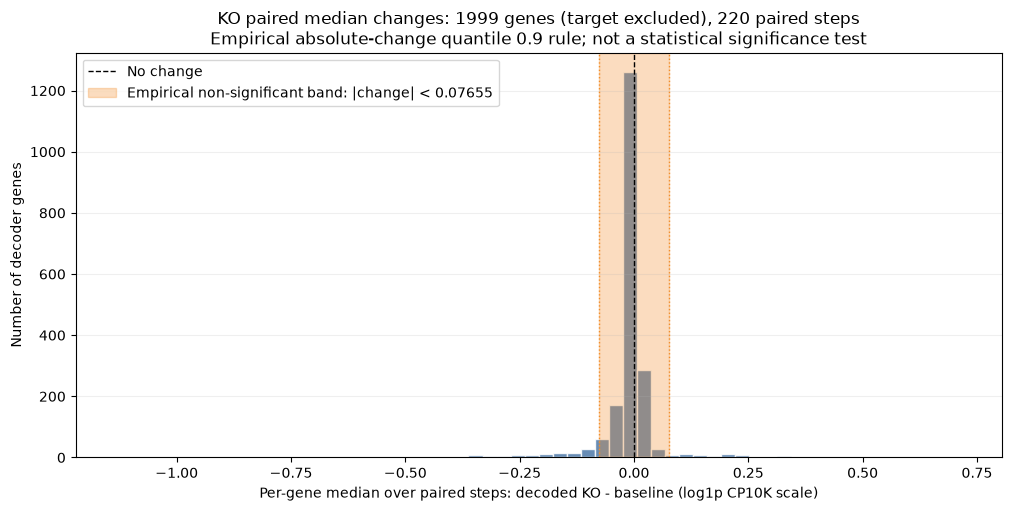

In [36]:
import torch.nn.functional as F

foxp3_required = ['step_marker_fraction', 'step_marker_path_z', 'step_marker_decoded',
                  'step_marker_decoder', 'step_marker_symbols', 'step_marker_table', 'step_marker_cell_z']
foxp3_missing = [name for name in foxp3_required if name not in globals()]
if foxp3_missing:
    raise RuntimeError(f'Run section 9-2 before this cell. Missing: {foxp3_missing}')
FOXP3_STEP_FRACTION = 0.5
FOXP3_STEP_TOLERANCE = 1e-3
FOXP3_STEP_ITERATIONS = 400
FOXP3_STEP_PENALTIES = (1., 10., 100., 1000., 10000.)
FOXP3_STEP_LRS = (0.02, 0.01, 0.005, 0.002, 0.001)
FOXP3_STEP_MARKERS = ['CTLA4', 'CD8A', 'CCR7', 'CD8B','IKZF2']
if not np.isfinite(step_marker_fraction).all() or not np.isfinite(step_marker_path_z).all():
    raise ValueError('Non-finite step fractions or latent path.')
if len(step_marker_fraction) != len(step_marker_path_z) or len(step_marker_table) != len(step_marker_path_z):
    raise ValueError('DQN step arrays are misaligned; rerun section 9-2.')
foxp3_step_mask = step_marker_fraction >= FOXP3_STEP_FRACTION
foxp3_step_ids = step_marker_table.loc[foxp3_step_mask, 'step'].to_numpy()
if not len(foxp3_step_ids):
    raise ValueError('No DQN step has Treg fraction >=0.5.')
foxp3_step_gene_positions = pd.Index(step_marker_symbols).get_indexer(FOXP3_STEP_MARKERS)
if (foxp3_step_gene_positions < 0).any():
    raise ValueError(f'Markers missing from decoder: {np.array(FOXP3_STEP_MARKERS)[foxp3_step_gene_positions < 0].tolist()}')
foxp3_step_output = int(pd.Index(step_marker_symbols).get_indexer(['FOXP3'])[0])
if foxp3_step_output < 0:
    raise ValueError('KO target FOXP3 is missing from the decoder.')
foxp3_step_decoder = step_marker_decoder.eval().requires_grad_(False)
foxp3_step_weights = {key: value.detach().clone() for key, value in foxp3_step_decoder.state_dict().items()}
foxp3_step_device = next(foxp3_step_decoder.parameters()).device
foxp3_step_z_base = torch.tensor(step_marker_path_z[foxp3_step_mask], dtype=torch.float32, device=foxp3_step_device)
with torch.no_grad():
    foxp3_step_baseline = foxp3_step_decoder(foxp3_step_z_base).cpu().numpy()
np.testing.assert_allclose(foxp3_step_baseline, step_marker_decoded[foxp3_step_mask], rtol=1e-5, atol=1e-5)
foxp3_step_z_ko = nn.Parameter(foxp3_step_z_base.clone())
foxp3_step_hidden = foxp3_step_decoder[:-1]
foxp3_step_final = foxp3_step_decoder[-1]
if not isinstance(foxp3_step_final, nn.Linear):
    raise TypeError('Expected the original linear decoder output layer.')
foxp3_step_weight = foxp3_step_final.weight[foxp3_step_output:foxp3_step_output + 1].detach()
foxp3_step_bias = foxp3_step_final.bias[foxp3_step_output:foxp3_step_output + 1].detach()
foxp3_step_log = []
for penalty, learning_rate in zip(FOXP3_STEP_PENALTIES, FOXP3_STEP_LRS):
    foxp3_step_optimizer = torch.optim.Adam([foxp3_step_z_ko], lr=learning_rate)
    for iteration in range(FOXP3_STEP_ITERATIONS):
        prediction = F.linear(foxp3_step_hidden(foxp3_step_z_ko), foxp3_step_weight, foxp3_step_bias).squeeze(1)
        loss = penalty * prediction.square().mean() + 0.1 * (foxp3_step_z_ko - foxp3_step_z_base).square().mean() + 0.001 * foxp3_step_z_ko.square().mean()
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite FOXP3-zero latent optimization loss.')
        foxp3_step_optimizer.zero_grad(set_to_none=True)
        foxp3_step_z_ko.grad, = torch.autograd.grad(loss, foxp3_step_z_ko)
        foxp3_step_optimizer.step()
    with torch.no_grad():
        residual = F.linear(foxp3_step_hidden(foxp3_step_z_ko), foxp3_step_weight, foxp3_step_bias).abs()
        foxp3_step_log.append({'penalty': penalty, 'learning_rate': learning_rate,
                               'max_abs_decoded_FOXP3': float(residual.max())})
display(pd.DataFrame(foxp3_step_log))
with torch.no_grad():
    foxp3_step_ko = foxp3_step_decoder(foxp3_step_z_ko).cpu().numpy()
    foxp3_step_z_ko_array = foxp3_step_z_ko.detach().cpu().numpy()
if not np.isfinite(foxp3_step_ko).all() or not np.isfinite(foxp3_step_z_ko_array).all():
    raise FloatingPointError('Non-finite FOXP3 counterfactual output.')
foxp3_step_residual = np.abs(foxp3_step_ko[:, foxp3_step_output])
if (foxp3_step_residual > FOXP3_STEP_TOLERANCE).any():
    raise RuntimeError(f'FOXP3-zero target not achieved: max residual={foxp3_step_residual.max():.6g}; do not interpret as KO.')
for key, value in foxp3_step_decoder.state_dict().items():
    torch.testing.assert_close(value, foxp3_step_weights[key], rtol=0, atol=0)
foxp3_step_delta = foxp3_step_ko.astype(np.float64) - foxp3_step_baseline.astype(np.float64)
foxp3_step_gene_medians = np.median(foxp3_step_delta, axis=0)
foxp3_step_gene_summary = pd.DataFrame({'gene': step_marker_symbols,
    'median_paired_change': foxp3_step_gene_medians,
    'mean_paired_change': foxp3_step_delta.mean(axis=0),
    'baseline_median': np.median(foxp3_step_baseline, axis=0), 'KO_median': np.median(foxp3_step_ko, axis=0)})
foxp3_hist_gene_mask = np.asarray(step_marker_symbols) != 'FOXP3'
foxp3_hist_values = foxp3_step_gene_medians[foxp3_hist_gene_mask]
if not len(foxp3_hist_values) or not np.isfinite(foxp3_hist_values).all():
    raise ValueError('Expected finite non-FOXP3 paired median changes for the empirical cutoff.')
foxp3_empirical_cutoff = float(np.quantile(np.abs(foxp3_hist_values), 0.9, method='linear'))
foxp3_step_gene_summary['absolute_median_paired_change'] = np.abs(foxp3_step_gene_medians)
foxp3_step_gene_summary['empirical_q90_cutoff'] = foxp3_empirical_cutoff
foxp3_step_gene_summary['empirical_classification'] = np.where(
    ~foxp3_hist_gene_mask, 'KO target: not assessed', np.where(
        np.abs(foxp3_step_gene_medians) < foxp3_empirical_cutoff,
        'Not significant (empirical rule)', 'Significant (empirical rule)'))
foxp3_empirical_non_significant = int((np.abs(foxp3_hist_values) < foxp3_empirical_cutoff).sum())
print(f'FOXP3 excluded: empirical absolute-change quantile 0.9 = {foxp3_empirical_cutoff:.8g}; '
      f'{foxp3_empirical_non_significant}/{len(foxp3_hist_values)} genes strictly below cutoff. Not a p-value or FDR.')
foxp3_step_knn = NearestNeighbors(n_neighbors=1).fit(step_marker_cell_z)
foxp3_step_distance_base = foxp3_step_knn.kneighbors(foxp3_step_z_base.cpu().numpy())[0].ravel()
foxp3_step_distance_ko = foxp3_step_knn.kneighbors(foxp3_step_z_ko_array)[0].ravel()
foxp3_step_diagnostics = pd.DataFrame({'step': foxp3_step_ids,
    'Treg_fraction': step_marker_fraction[foxp3_step_mask],
    'baseline_FOXP3': foxp3_step_baseline[:, foxp3_step_output], 'KO_FOXP3': foxp3_step_ko[:, foxp3_step_output],
    'nearest_cell_distance_baseline': foxp3_step_distance_base, 'nearest_cell_distance_KO': foxp3_step_distance_ko,
    'latent_shift_l2': np.linalg.norm(foxp3_step_z_ko_array - foxp3_step_z_base.cpu().numpy(), axis=1)})
print(f'Selected {len(foxp3_step_ids)} Treg-like steps ({foxp3_step_ids.min()}-{foxp3_step_ids.max()}); max abs KO FOXP3={foxp3_step_residual.max():.6g}; decoder unchanged.')
print(f'Median nearest-real-cell distance: baseline={np.median(foxp3_step_distance_base):.4f}, KO={np.median(foxp3_step_distance_ko):.4f}. Increased distance indicates potential extrapolation.')
display(foxp3_step_gene_summary.set_index('gene').loc[FOXP3_STEP_MARKERS])
foxp3_hist_fig, foxp3_hist_ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
foxp3_hist_counts, foxp3_hist_bins, _ = foxp3_hist_ax.hist(foxp3_hist_values, bins=60, color='#4C78A8', edgecolor='white', alpha=0.85)
foxp3_hist_ax.axvline(0, color='black', ls='--', lw=1, label='No change')
foxp3_hist_ax.axvspan(-foxp3_empirical_cutoff, foxp3_empirical_cutoff, color='#F28E2B', alpha=0.3,
                     label=f'Empirical non-significant band: |change| < {foxp3_empirical_cutoff:.4g}')
foxp3_hist_ax.axvline(-foxp3_empirical_cutoff, color='#F28E2B', ls=':', lw=1)
foxp3_hist_ax.axvline(foxp3_empirical_cutoff, color='#F28E2B', ls=':', lw=1)
foxp3_hist_ax.set(xlabel='Per-gene median over paired steps: decoded KO - baseline (log1p CP10K scale)',
    ylabel='Number of decoder genes', title=f'KO paired median changes: {len(foxp3_hist_values)} genes (target excluded), {len(foxp3_step_ids)} paired steps\nEmpirical absolute-change quantile 0.9 rule; not a statistical significance test')
foxp3_hist_ax.legend()
foxp3_hist_ax.grid(axis='y', alpha=0.2)
plt.show()
assert int(foxp3_hist_counts.sum()) == len(step_marker_symbols) - 1

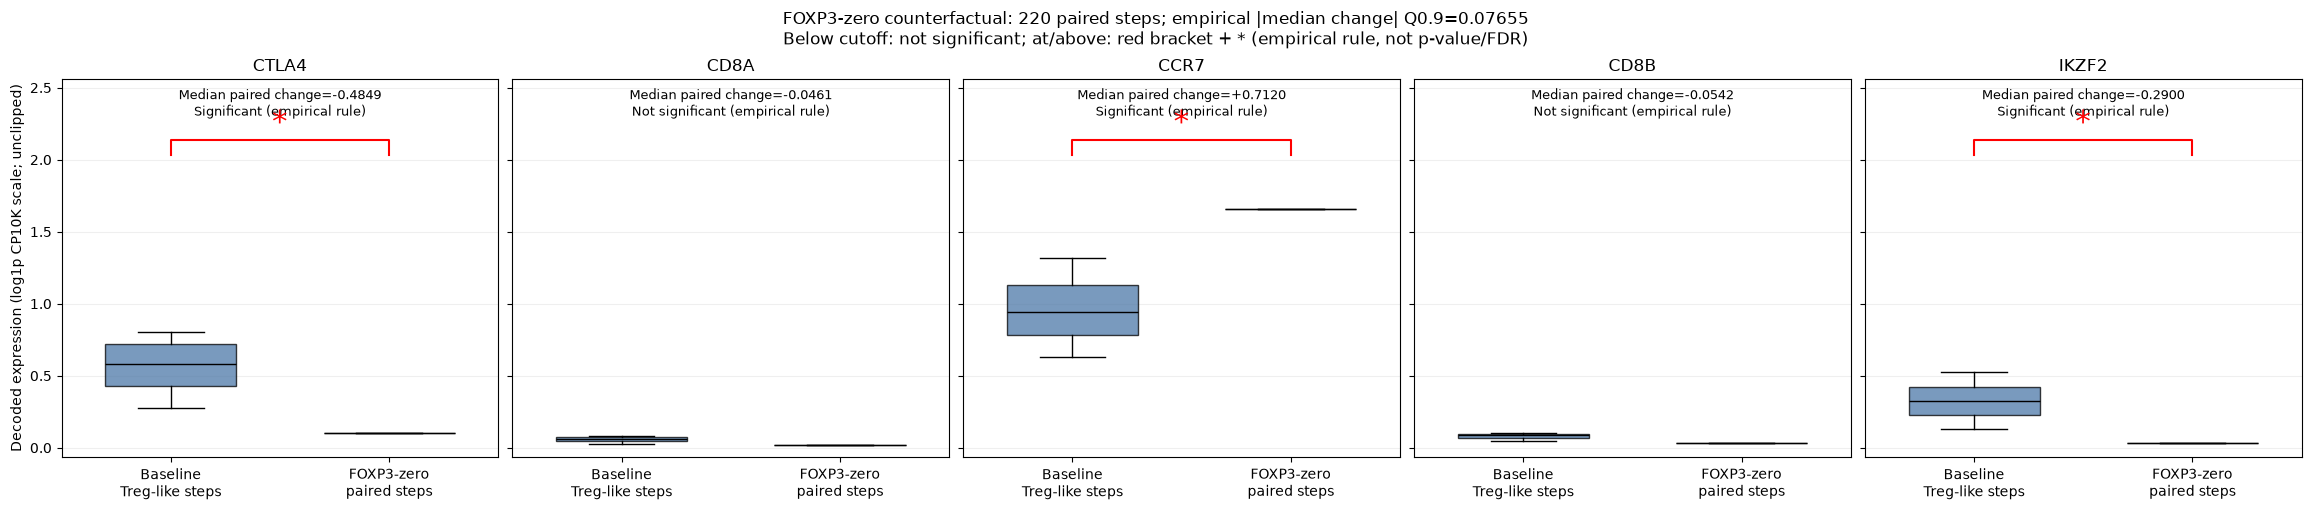

In [37]:
if 'foxp3_step_gene_summary' not in globals() or 'foxp3_empirical_cutoff' not in globals():
    raise RuntimeError('Run the FOXP3-zero optimization and histogram cell first.')
foxp3_box_markers = [gene for gene, position in zip(FOXP3_STEP_MARKERS, foxp3_step_gene_positions) if position != foxp3_step_output]
foxp3_box_positions = foxp3_step_gene_positions[foxp3_step_gene_positions != foxp3_step_output]
if not len(foxp3_box_markers):
    raise ValueError('No non-target markers remain for the boxplot.')
foxp3_box_fig, foxp3_box_axes_grid = plt.subplots(1, len(foxp3_box_markers), figsize=(4.6 * len(foxp3_box_markers), 5), sharey=True, constrained_layout=True, squeeze=False)
foxp3_box_axes = foxp3_box_axes_grid.ravel()
foxp3_box_min = min(foxp3_step_baseline[:, foxp3_box_positions].min(), foxp3_step_ko[:, foxp3_box_positions].min())
foxp3_box_max = max(foxp3_step_baseline[:, foxp3_box_positions].max(), foxp3_step_ko[:, foxp3_box_positions].max())
foxp3_box_span = max(float(foxp3_box_max - foxp3_box_min), 0.1)
for axis, gene, position in zip(foxp3_box_axes, foxp3_box_markers, foxp3_box_positions):
    boxes = axis.boxplot([foxp3_step_baseline[:, position], foxp3_step_ko[:, position]],
        patch_artist=True, widths=0.6, flierprops={'markersize': 2, 'alpha': 0.3}, medianprops={'color': 'black'})
    for patch, color in zip(boxes['boxes'], ['#4C78A8', '#E45756']):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    axis.set_xticks([1, 2], ['Baseline\nTreg-like steps', 'FOXP3-zero\npaired steps'])
    axis.set_title(gene)
    classification = foxp3_step_gene_summary.iloc[position]['empirical_classification']
    axis.text(0.5, 0.98, f'Median paired change={foxp3_step_gene_medians[position]:+.4f}\n{classification}',
              ha='center', va='top', transform=axis.transAxes, fontsize=9)
    axis.set_ylim(foxp3_box_min - 0.05 * foxp3_box_span, foxp3_box_max + 0.55 * foxp3_box_span)
    if classification == 'Significant (empirical rule)':
        axis.plot([1, 1, 2, 2], [0.80, 0.84, 0.84, 0.80], transform=axis.get_xaxis_transform(), color='red', lw=1.5)
        axis.text(1.5, 0.84, '*', transform=axis.get_xaxis_transform(), color='red', fontsize=22, ha='center', va='bottom')
    axis.grid(axis='y', alpha=0.2)
foxp3_box_axes[0].set_ylabel('Decoded expression (log1p CP10K scale; unclipped)')
foxp3_box_fig.suptitle(f'FOXP3-zero counterfactual: {len(foxp3_step_ids)} paired steps; empirical |median change| Q0.9={foxp3_empirical_cutoff:.4g}\nBelow cutoff: not significant; at/above: red bracket + * (empirical rule, not p-value/FDR)')
plt.show()


## 10. TOP10 variance-ranked TF KO response network: edge DataFrame

**8번 섹션을 먼저 실행합니다.** 전체 DQN 경로의 decoder 발현 분산으로 선정한 `tf_decoder_top` TOP10 TF를 사용합니다. 최근접 실제 세포 10개 기준 **Treg fraction ≥0.5**인 step의 원래 latent에서 각 TF를 독립적으로 KO합니다. 9번과 같은 고정 MLP decoder, 단계적 penalty 및 latent proximity/prior 목적함수를 사용하며, 모든 선택 step에서 KO 대상 출력의 절댓값이 0.001 이하인지 확인합니다. 기본 penalty 1~10000으로 실패하면 100000/1000000/10000000으로 추가 최적화합니다. 그래도 실패한 TF는 경고·진단표에 남기고 네트워크에서 제외합니다(0을 출력하도록 값을 덮어쓰지 않음).

각 TF → decoder 유전자 관계의 `network_power = median_over_paired_steps(decoded_KO - decoded_baseline)`입니다. 두 조건 median의 차이가 아닌 **paired 차이의 median**이며, 음수는 **KO 시 감소**, 양수는 **KO 시 증가**를 뜻합니다. 자기 자신은 제외하고 TF별 `abs(network_power)` **quantile 0.9 이상**이면서 변화가 0이 아닌 관계만 `tf_ko_network_edges`에 남깁니다. `tf_ko_network_all`에는 비선택 관계도 보존합니다. Baseline/KO median, 절댓값 power, cutoff, TF 분산 순위와 step 수를 함께 기록합니다.

이 ‘유의’는 사용자 지정 **경험적 상위 약 10% 분류**이지 p-value/FDR가 아닙니다. 방향은 KO TF → 모델 반응 유전자이고, 부호는 KO 반응 부호입니다(정상 TF의 활성화/억제 부호로 반전하지 않음). 직접 결합이나 실제 인과적 GRN을 증명하지 않습니다. 연속 DQN step의 상관성과 외삽 가능성이 있으므로 TF별 최근접 실제 세포 거리도 진단합니다. 경로·decoder를 변경하지 않고, 우선 네트워크 그림 없이 DataFrame만 노트북에 생성합니다.

In [38]:
from copy import deepcopy
import warnings
import torch.nn.functional as F

tf_ko_required = ['tf_decoder_top', 'tf_decoder_symbols', 'tf_path_decoder', 'tf_path_decoded',
                  'tf_plot_query', 'tf_plot_path', 'tf_annotation_treg_fraction', 'tf_plot_cell_z']
tf_ko_missing = [name for name in tf_ko_required if name not in globals()]
if tf_ko_missing:
    raise RuntimeError(f'Run section 8 first. Missing: {tf_ko_missing}')
TF_KO_FRACTION = 0.5
TF_KO_QUANTILE = 0.9
TF_KO_TOLERANCE = 1e-3
TF_KO_ITERATIONS = 400
TF_KO_PENALTIES = (1., 10., 100., 1000., 10000.)
TF_KO_LRS = (0.02, 0.01, 0.005, 0.002, 0.001)
TF_KO_RETRY_PENALTIES = (100000., 1000000., 10000000.)
TF_KO_RETRY_LRS = (0.005, 0.002, 0.001)
tf_ko_sources = tf_decoder_top[['rank', 'TF', 'variance']].copy()
if len(tf_ko_sources) != 10 or tf_ko_sources['TF'].duplicated().any():
    raise ValueError('Expected exactly 10 distinct variance-ranked TFs from section 8.')
tf_ko_symbols = pd.Index(tf_decoder_symbols)
if not tf_ko_symbols.is_unique or (tf_ko_symbols.get_indexer(tf_ko_sources['TF']) < 0).any():
    raise ValueError('TOP10 TFs must map uniquely to decoder outputs.')
if len(tf_annotation_treg_fraction) != len(tf_plot_query) or len(tf_plot_path) != len(tf_plot_query):
    raise ValueError('DQN coordinates, step table and fractions are misaligned.')
if not np.isfinite(tf_annotation_treg_fraction).all() or not np.isfinite(tf_plot_query).all():
    raise ValueError('Non-finite DQN coordinates or fractions.')
tf_ko_step_mask = np.asarray(tf_annotation_treg_fraction) >= TF_KO_FRACTION
tf_ko_step_ids = tf_plot_path.loc[tf_ko_step_mask, 'step'].to_numpy()
if not len(tf_ko_step_ids):
    raise ValueError('No Treg-like DQN steps available for TF KO.')
tf_ko_decoder = deepcopy(tf_path_decoder).eval().requires_grad_(False)
tf_ko_device = next(tf_ko_decoder.parameters()).device
tf_ko_z_base = torch.tensor(tf_plot_query[tf_ko_step_mask], dtype=torch.float32, device=tf_ko_device)
with torch.no_grad():
    tf_ko_baseline = tf_ko_decoder(tf_ko_z_base).cpu().numpy()
np.testing.assert_allclose(tf_ko_baseline, tf_path_decoded[tf_ko_step_mask], rtol=1e-5, atol=1e-5)
if not np.isfinite(tf_ko_baseline).all() or tf_ko_baseline.shape[1] != len(tf_ko_symbols):
    raise ValueError('Invalid decoder baseline or gene mapping.')
tf_ko_knn = NearestNeighbors(n_neighbors=1).fit(tf_plot_cell_z)
tf_ko_base_distance = tf_ko_knn.kneighbors(tf_ko_z_base.cpu().numpy())[0].ravel()

def optimize_tf_ko_latent(decoder, baseline_z, output_position):
    latent = nn.Parameter(baseline_z.clone())
    hidden, final = decoder[:-1], decoder[-1]
    if not isinstance(final, nn.Linear):
        raise TypeError('Expected the original linear decoder output layer.')
    weight = final.weight[output_position:output_position + 1].detach()
    bias = final.bias[output_position:output_position + 1].detach()
    stages = list(zip(TF_KO_PENALTIES, TF_KO_LRS)) + list(zip(TF_KO_RETRY_PENALTIES, TF_KO_RETRY_LRS))
    for stage, (penalty, learning_rate) in enumerate(stages):
        if stage >= len(TF_KO_PENALTIES):
            with torch.no_grad():
                if (F.linear(hidden(latent), weight, bias).abs() <= TF_KO_TOLERANCE).all():
                    break
        optimizer = torch.optim.Adam([latent], lr=learning_rate)
        for _ in range(TF_KO_ITERATIONS):
            prediction = F.linear(hidden(latent), weight, bias).squeeze(1)
            loss = penalty * prediction.square().mean() + 0.1 * (latent - baseline_z).square().mean() + 0.001 * latent.square().mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite TF KO optimization loss.')
            optimizer.zero_grad(set_to_none=True)
            latent.grad, = torch.autograd.grad(loss, latent)
            optimizer.step()
    with torch.no_grad():
        decoded = decoder(latent).cpu().numpy()
    coordinates = latent.detach().cpu().numpy()
    if not np.isfinite(decoded).all() or not np.isfinite(coordinates).all():
        raise FloatingPointError('Non-finite TF KO output.')
    return coordinates, decoded

tf_ko_frames, tf_ko_diagnostic_rows = [], []
tf_ko_counterfactuals = {}
for source in tf_ko_sources.itertuples(index=False):
    position = int(tf_ko_symbols.get_loc(source.TF))
    coordinates, decoded = optimize_tf_ko_latent(tf_ko_decoder, tf_ko_z_base, position)
    residual = np.abs(decoded[:, position])
    passed = bool((residual <= TF_KO_TOLERANCE).all())
    ko_distance = tf_ko_knn.kneighbors(coordinates)[0].ravel()
    tf_ko_diagnostic_rows.append({'source_TF': source.TF, 'tf_variance_rank': source.rank,
        'n_paired_steps': len(tf_ko_step_ids), 'max_abs_KO_target': float(residual.max()),
        'n_failed_steps': int((residual > TF_KO_TOLERANCE).sum()), 'KO_valid': passed,
        'median_nearest_cell_distance_baseline': float(np.median(tf_ko_base_distance)),
        'median_nearest_cell_distance_KO': float(np.median(ko_distance)),
        'median_latent_shift_l2': float(np.median(np.linalg.norm(coordinates - tf_ko_z_base.cpu().numpy(), axis=1)))})
    print(f'{source.TF}: max abs KO target={residual.max():.6g}; valid={passed}', flush=True)
    if not passed:
        warnings.warn(f'{source.TF}: KO tolerance failed; no network edges created for this TF.', RuntimeWarning)
        continue
    tf_ko_counterfactuals[source.TF] = {'latent': coordinates, 'decoded': decoded}
    power = np.median(decoded.astype(np.float64) - tf_ko_baseline.astype(np.float64), axis=0)
    nonself = np.arange(len(tf_ko_symbols)) != position
    cutoff = float(np.quantile(np.abs(power[nonself]), TF_KO_QUANTILE, method='linear'))
    frame = pd.DataFrame({'source_TF': source.TF, 'target_gene': tf_ko_symbols[nonself],
        'tf_variance_rank': source.rank, 'source_path_variance': source.variance,
        'network_power': power[nonself], 'abs_network_power': np.abs(power[nonself]),
        'baseline_median': np.median(tf_ko_baseline[:, nonself], axis=0),
        'KO_median': np.median(decoded[:, nonself], axis=0), 'empirical_q90_cutoff': cutoff,
        'n_paired_steps': len(tf_ko_step_ids)})
    frame['KO_response'] = np.select([frame['network_power'] < 0, frame['network_power'] > 0],
                                      ['decreased_on_KO', 'increased_on_KO'], default='unchanged')
    frame['empirical_significant'] = (frame['abs_network_power'] >= cutoff) & (frame['abs_network_power'] > 0)
    tf_ko_frames.append(frame)
tf_ko_diagnostics = pd.DataFrame(tf_ko_diagnostic_rows)
display(tf_ko_diagnostics)
if not tf_ko_frames:
    raise RuntimeError('All TOP10 TF KO optimizations failed; inspect tf_ko_diagnostics.')
tf_ko_network_all = pd.concat(tf_ko_frames, ignore_index=True)
tf_ko_network_edges = tf_ko_network_all.loc[tf_ko_network_all['empirical_significant']].sort_values(
    ['tf_variance_rank', 'abs_network_power', 'target_gene'], ascending=[True, False, True], kind='stable').reset_index(drop=True)
for key, value in tf_ko_decoder.state_dict().items():
    torch.testing.assert_close(value, tf_path_decoder.state_dict()[key], rtol=0, atol=0)
print(f'{len(tf_ko_frames)}/10 valid TF KOs; {len(tf_ko_network_edges)} directed response edges; '
      f'{len(tf_ko_step_ids)} paired Treg-like steps. Empirical Q0.9 selection, not p-value/FDR.')
display(tf_ko_network_edges)


BACH2: max abs KO target=5.1111e-05; valid=True
FOXP3: max abs KO target=7.3202e-06; valid=True
PRDM1: max abs KO target=6.01485e-05; valid=True
TAGLN2: max abs KO target=0.977145; valid=False


/tmp/ipykernel_895139/2757157721.py:88: RuntimeWarning: TAGLN2: KO tolerance failed; no network edges created for this TF.
  warnings.warn(f'{source.TF}: KO tolerance failed; no network edges created for this TF.', RuntimeWarning)


LEF1: max abs KO target=0.960091; valid=False


/tmp/ipykernel_895139/2757157721.py:88: RuntimeWarning: LEF1: KO tolerance failed; no network edges created for this TF.
  warnings.warn(f'{source.TF}: KO tolerance failed; no network edges created for this TF.', RuntimeWarning)


IKZF2: max abs KO target=0.000192512; valid=True
RORA: max abs KO target=0.000107907; valid=True
ARID5B: max abs KO target=0.0635498; valid=False


/tmp/ipykernel_895139/2757157721.py:88: RuntimeWarning: ARID5B: KO tolerance failed; no network edges created for this TF.
  warnings.warn(f'{source.TF}: KO tolerance failed; no network edges created for this TF.', RuntimeWarning)


... (3 outputs left out)

/tmp/ipykernel_895139/2757157721.py:88: RuntimeWarning: JUNB: KO tolerance failed; no network edges created for this TF.
  warnings.warn(f'{source.TF}: KO tolerance failed; no network edges created for this TF.', RuntimeWarning)


,source_TF,tf_variance_rank,n_paired_steps,max_abs_KO_target,n_failed_steps,KO_valid,median_nearest_cell_distance_baseline,median_nearest_cell_distance_KO,median_latent_shift_l2
0,BACH2,1,220,0.000051,0,True,0.091806,1.476375,2.770213
1,FOXP3,2,220,0.000007,0,True,0.091806,0.134027,0.975572
2,PRDM1,3,220,0.000060,0,True,0.091806,0.485900,1.288914
3,TAGLN2,4,220,0.977145,220,False,0.091806,4.861553,5.747438
4,LEF1,5,220,0.960091,220,False,0.091806,9.506297,9.745392
5,IKZF2,6,220,0.000193,0,True,0.091806,1.973856,2.810991
6,RORA,7,220,0.000108,0,True,0.091806,3.118591,5.272574
7,ARID5B,8,220,0.063550,220,False,0.091806,10.742751,11.452633
8,KLF6,9,220,0.083439,220,False,0.091806,12.596637,13.964931
9,JUNB,10,220,0.375527,159,False,0.091806,6.946280,8.049662


5/10 valid TF KOs; 1000 directed response edges; 220 paired Treg-like steps. Empirical Q0.9 selection, not p-value/FDR.


,source_TF,target_gene,tf_variance_rank,source_path_variance,network_power,abs_network_power,baseline_median,KO_median,empirical_q90_cutoff,n_paired_steps,KO_response,empirical_significant
0,BACH2,HLA-DRB1,1,0.057323,3.498594,3.498594,0.277308,3.775902,0.24966,220,increased_on_KO,True
1,BACH2,CD74,1,0.057323,3.273015,3.273015,1.536164,4.809180,0.24966,220,increased_on_KO,True
2,BACH2,S100A4,1,0.057323,2.887363,2.887363,2.284353,5.171716,0.24966,220,increased_on_KO,True
3,BACH2,ANXA2,1,0.057323,2.620213,2.620213,0.509993,3.130206,0.24966,220,increased_on_KO,True
4,BACH2,LGALS1,1,0.057323,2.468109,2.468109,0.254627,2.722736,0.24966,220,increased_on_KO,True
...,...,...,...,...,...,...,...,...,...,...,...,...
995,RORA,KIAA1109,7,0.024084,-0.170656,0.170656,0.267850,0.097157,0.16758,220,decreased_on_KO,True
996,RORA,TRAV5,7,0.024084,-0.169861,0.169861,0.061300,-0.108566,0.16758,220,decreased_on_KO,True
997,RORA,MAN2A1,7,0.024084,-0.169333,0.169333,0.172086,0.002709,0.16758,220,decreased_on_KO,True
998,RORA,CBLB,7,0.024084,-0.168135,0.168135,0.367033,0.198903,0.16758,220,decreased_on_KO,True


### 10-1. Directed signed TF KO response network

10번의 `tf_ko_network_edges`를 그대로 사용하여 모든 선택 엣지와 연결 노드를 표시합니다. 화살표는 **KO TF → 반응 유전자**, 색은 signed `network_power`의 대칭 연속 척도(**음수 파랑 → 0 흰색 → 양수 빨강**)입니다. 두께는 절댓값 power에 비례합니다. TF 목록(`tf_variance_symbols`, 8번)에 있는 노드는 삼각형, 나머지 유전자는 원으로 구분합니다. KO 출발 TF는 주황색, 나머지 TF는 보라색, 일반 유전자는 연한 회색입니다. 모든 노드·엣지는 포함하되 가독성을 위해 TF와 절대 power 상위 20개 target만 이름을 표시합니다. 노드별 이름·모양·좌표는 `tf_ko_network_nodes`에 보존합니다. Layout은 고정 seed의 시각화 좌표이며 생물학적 거리나 DQN latent 좌표가 아닙니다. 색은 정상 TF의 활성/억제 관계가 아닌 **KO 시 변화의 부호**이며, 별도 네트워크 파일은 저장하지 않습니다.

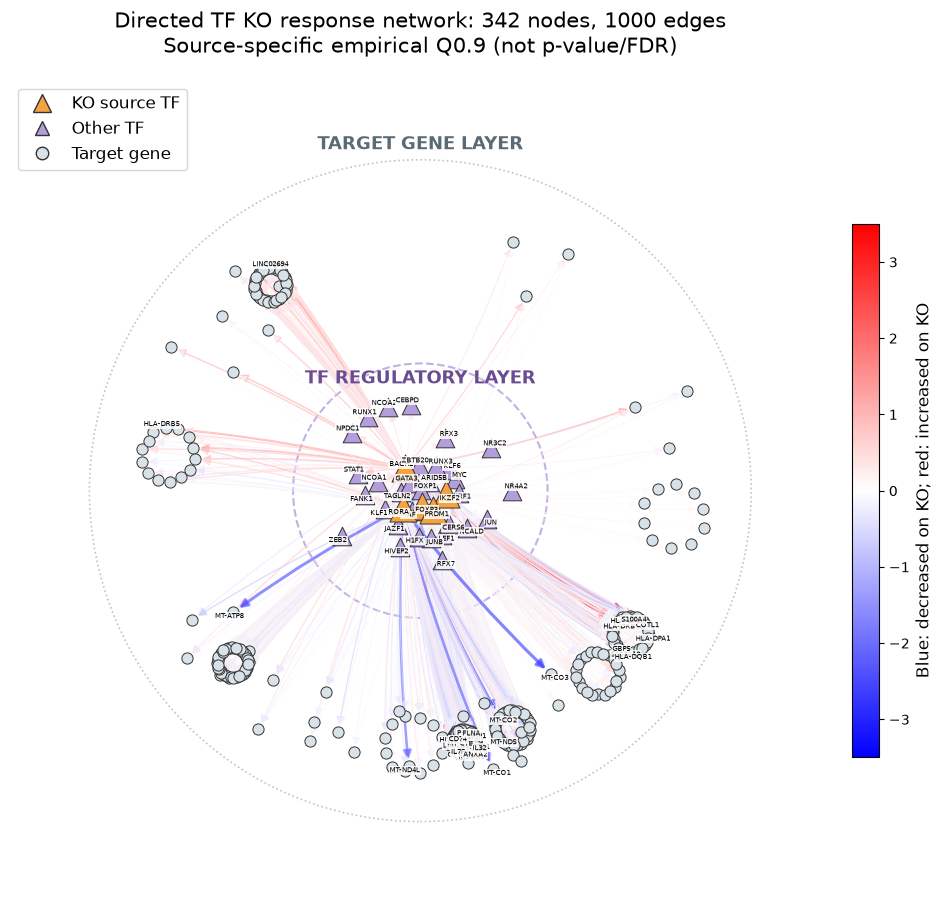

In [39]:
import networkx as nx
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'tf_ko_network_edges' not in globals() or 'tf_variance_symbols' not in globals():
    raise RuntimeError('Run sections 8 and 10 before plotting the KO network.')

tf_ko_plot_edges = tf_ko_network_edges.copy()

if tf_ko_plot_edges.empty:
    raise ValueError('No selected KO network edges to plot.')
if not np.isfinite(tf_ko_plot_edges['network_power']).all():
    raise ValueError('Network powers must be finite.')
if tf_ko_plot_edges[['source_TF', 'target_gene']].duplicated().any():
    raise ValueError('Duplicate directed network edges would overwrite powers.')

tf_ko_graph = nx.from_pandas_edgelist(
    tf_ko_plot_edges,
    'source_TF',
    'target_gene',
    edge_attr=['network_power', 'abs_network_power'],
    create_using=nx.DiGraph()
)

tf_ko_source_nodes = set(tf_ko_plot_edges['source_TF'])
tf_ko_tf_names = set(tf_variance_symbols) | tf_ko_source_nodes
tf_ko_tf_nodes = [g for g in tf_ko_graph.nodes if g in tf_ko_tf_names]
tf_ko_gene_nodes = [g for g in tf_ko_graph.nodes if g not in tf_ko_tf_names]

tf_ko_network_nodes = pd.DataFrame({'gene': list(tf_ko_graph.nodes)})
tf_ko_network_nodes['is_TF'] = tf_ko_network_nodes['gene'].isin(tf_ko_tf_names)
tf_ko_network_nodes['is_KO_source'] = tf_ko_network_nodes['gene'].isin(tf_ko_source_nodes)
tf_ko_network_nodes['node_shape'] = np.where(tf_ko_network_nodes['is_TF'], '^', 'o')

tf_ko_positions = {}

tf_ko_tf_subgraph = tf_ko_graph.subgraph(tf_ko_tf_nodes).to_undirected()

if len(tf_ko_tf_nodes) > 1:
    tf_ko_tf_layout = nx.spring_layout(
        tf_ko_tf_subgraph,
        seed=42,
        k=2.5 / np.sqrt(len(tf_ko_tf_nodes)),
        iterations=200
    )
else:
    tf_ko_tf_layout = {g: np.array([0.0, 0.0]) for g in tf_ko_tf_nodes}

tf_ko_tf_coords = np.array([tf_ko_tf_layout[g] for g in tf_ko_tf_nodes])

if len(tf_ko_tf_nodes) > 1:
    tf_ko_tf_coords -= tf_ko_tf_coords.mean(axis=0)
    tf_ko_tf_radius = np.linalg.norm(tf_ko_tf_coords, axis=1).max()
    if tf_ko_tf_radius > 0:
        tf_ko_tf_coords *= 1.8 / tf_ko_tf_radius

for i, g in enumerate(tf_ko_tf_nodes):
    tf_ko_positions[g] = tf_ko_tf_coords[i] if len(tf_ko_tf_nodes) > 1 else np.array([0.0, 0.0])

tf_ko_target_groups = {
    g: [
        tf for tf in tf_ko_tf_nodes
        if tf_ko_graph.has_edge(tf, g)
    ]
    for g in tf_ko_gene_nodes
}

tf_ko_gene_groups = {}

for g in tf_ko_gene_nodes:
    connected_tfs = tf_ko_target_groups[g]
    if connected_tfs:
        tf_ko_anchor = np.mean(
            [tf_ko_positions[tf] for tf in connected_tfs],
            axis=0
        )
        tf_ko_angle = np.arctan2(tf_ko_anchor[1], tf_ko_anchor[0])
        tf_ko_gene_groups.setdefault(round(tf_ko_angle, 1), []).append(g)
    else:
        tf_ko_gene_groups.setdefault(0.0, []).append(g)

tf_ko_group_angles = sorted(tf_ko_gene_groups)

for tf_ko_group_index, tf_ko_angle_key in enumerate(tf_ko_group_angles):
    tf_ko_group = tf_ko_gene_groups[tf_ko_angle_key]
    tf_ko_angle = tf_ko_angle_key

    tf_ko_group_subgraph = tf_ko_graph.subgraph(tf_ko_group).to_undirected()

    if len(tf_ko_group) > 1:
        tf_ko_group_layout = nx.spring_layout(
            tf_ko_group_subgraph,
            seed=42 + tf_ko_group_index,
            k=0.8 / np.sqrt(len(tf_ko_group)),
            iterations=100
        )
    else:
        tf_ko_group_layout = {tf_ko_group[0]: np.array([0.0, 0.0])}

    tf_ko_group_coords = np.array([tf_ko_group_layout[g] for g in tf_ko_group])

    if len(tf_ko_group) > 1:
        tf_ko_group_coords -= tf_ko_group_coords.mean(axis=0)
        tf_ko_group_radius = np.linalg.norm(tf_ko_group_coords, axis=1).max()
        if tf_ko_group_radius > 0:
            tf_ko_group_coords *= min(0.65, 2.0 / np.sqrt(len(tf_ko_group)))

    tf_ko_radial_center = np.array([
        5.0 * np.cos(tf_ko_angle),
        5.0 * np.sin(tf_ko_angle)
    ])

    tf_ko_tangent = np.array([
        -np.sin(tf_ko_angle),
        np.cos(tf_ko_angle)
    ])

    for i, g in enumerate(tf_ko_group):
        tf_ko_positions[g] = (
            tf_ko_radial_center
            + tf_ko_group_coords[i][0] * tf_ko_tangent
            + tf_ko_group_coords[i][1] * np.array([
                np.cos(tf_ko_angle),
                np.sin(tf_ko_angle)
            ])
        )

for g in tf_ko_graph.nodes:
    if g not in tf_ko_positions:
        tf_ko_positions[g] = np.array([
            5.0 * np.cos(2 * np.pi * len(tf_ko_positions) / max(1, len(tf_ko_graph))),
            5.0 * np.sin(2 * np.pi * len(tf_ko_positions) / max(1, len(tf_ko_graph)))
        ])

tf_ko_network_nodes['x'] = [tf_ko_positions[g][0] for g in tf_ko_network_nodes['gene']]
tf_ko_network_nodes['y'] = [tf_ko_positions[g][1] for g in tf_ko_network_nodes['gene']]

tf_ko_draw_edges = list(tf_ko_graph.edges)
tf_ko_draw_power = np.array([
    tf_ko_graph[u][v]['network_power']
    for u, v in tf_ko_draw_edges
])

tf_ko_color_limit = float(np.abs(tf_ko_draw_power).max())

if tf_ko_color_limit <= 0:
    raise ValueError('Expected nonzero selected KO network powers.')

tf_ko_color_norm = TwoSlopeNorm(
    vmin=-tf_ko_color_limit,
    vcenter=0,
    vmax=tf_ko_color_limit
)

tf_ko_edge_cmap = plt.get_cmap('bwr')
tf_ko_edge_colors = tf_ko_edge_cmap(tf_ko_color_norm(tf_ko_draw_power))
tf_ko_edge_widths = 0.4 + 2.6 * np.abs(tf_ko_draw_power) / tf_ko_color_limit

tf_ko_network_fig, tf_ko_network_ax = plt.subplots(
    figsize=(12, 9),
    constrained_layout=True
)

tf_ko_network_ax.add_patch(plt.Circle(
    (0, 0), 2.5,
    fill=False,
    edgecolor='#B39DDB',
    linewidth=1.5,
    linestyle='--',
    alpha=0.8
))

tf_ko_network_ax.add_patch(plt.Circle(
    (0, 0), 6.5,
    fill=False,
    edgecolor='#9EADB5',
    linewidth=1.2,
    linestyle=':',
    alpha=0.7
))

nx.draw_networkx_edges(
    tf_ko_graph,
    tf_ko_positions,
    ax=tf_ko_network_ax,
    edgelist=tf_ko_draw_edges,
    edge_color=tf_ko_edge_colors,
    width=tf_ko_edge_widths,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=12,
    node_size=100,
    connectionstyle='arc3,rad=0.04',
    alpha=0.65,
    min_source_margin=3,
    min_target_margin=5
)

for is_tf, is_source, color, size in [
    (False, False, '#D9E2E8', 65),
    (True, False, '#B39DDB', 180),
    (True, True, '#F4A340', 380)
]:
    group = tf_ko_network_nodes.loc[
        (tf_ko_network_nodes['is_TF'] == is_tf) &
        (tf_ko_network_nodes['is_KO_source'] == is_source),
        'gene'
    ].tolist()

    if group:
        nx.draw_networkx_nodes(
            tf_ko_graph,
            tf_ko_positions,
            ax=tf_ko_network_ax,
            nodelist=group,
            node_shape='^' if is_tf else 'o',
            node_color=color,
            node_size=size,
            edgecolors='#333333',
            linewidths=0.7
        )

tf_ko_strong_targets = set(
    tf_ko_plot_edges.groupby('target_gene')['abs_network_power']
    .max()
    .nlargest(30)
    .index
)

tf_ko_label_nodes = {
    g for g in tf_ko_graph
    if g in tf_ko_tf_names or g in tf_ko_strong_targets
}

tf_ko_label_positions = {}

for g in tf_ko_label_nodes:
    x, y = tf_ko_positions[g]
    tf_ko_label_positions[g] = (
        x + 0.08 * np.sign(x if x != 0 else 1),
        y + 0.08 * np.sign(y if y != 0 else 1)
    )

nx.draw_networkx_labels(
    tf_ko_graph,
    tf_ko_label_positions,
    labels={g: g for g in tf_ko_label_nodes},
    ax=tf_ko_network_ax,
    font_size=5,
    font_weight='medium',
    bbox={
        'facecolor': 'white',
        'alpha': 0.85,
        'edgecolor': 'none',
        'pad': 0.7
    }
)

tf_ko_colorbar = tf_ko_network_fig.colorbar(
    ScalarMappable(norm=tf_ko_color_norm, cmap=tf_ko_edge_cmap),
    ax=tf_ko_network_ax,
    shrink=0.65,
    pad=0.02
)

tf_ko_colorbar.set_label(
    'Blue: decreased on KO; red: increased on KO',
    fontsize=12
)

tf_ko_network_ax.legend(
    handles=[
        Line2D([], [], marker='^', color='none', markerfacecolor='#F4A340',
               markeredgecolor='#333333', markersize=13, label='KO source TF'),
        Line2D([], [], marker='^', color='none', markerfacecolor='#B39DDB',
               markeredgecolor='#333333', markersize=10, label='Other TF'),
        Line2D([], [], marker='o', color='none', markerfacecolor='#D9E2E8',
               markeredgecolor='#333333', markersize=9, label='Target gene')
    ],
    loc='upper left',
    fontsize=12,
    frameon=True
)

tf_ko_network_ax.text(
    0, 2.2, 'TF REGULATORY LAYER',
    ha='center', va='center',
    fontsize=13, fontweight='bold',
    color='#6A4C93'
)

tf_ko_network_ax.text(
    0, 6.8, 'TARGET GENE LAYER',
    ha='center', va='center',
    fontsize=13, fontweight='bold',
    color='#596B75'
)

tf_ko_network_ax.set_title(
    f'Directed TF KO response network: {tf_ko_graph.number_of_nodes()} nodes, '
    f'{tf_ko_graph.number_of_edges()} edges\n'
    'Source-specific empirical Q0.9 (not p-value/FDR)',
    fontsize=15,
    pad=20
)

tf_ko_network_ax.set_aspect('equal')
tf_ko_network_ax.margins(0.12)
tf_ko_network_ax.set_axis_off()

plt.show()

### 10-2. Top3 TF individual KO response networks

8번의 **분산 순위 Top3** TF 각각의 outgoing KO 반응 관계를 별도 figure로 표시합니다(중심성 순위가 아님). 10-1의 TF/유전자 레이어 좌표, 삼각형/원, 색상, 화살표와 라벨 스타일을 유지합니다. 엣지 색과 두께는 전체 네트워크의 동일한 척도를 사용하여 세 그림을 비교할 수 있습니다. 각 그림에서 해당 KO source만 주황색이며 다른 TF target은 보라색입니다. 모든 선택 target·엣지를 포함하고, TF와 해당 source의 절대 power 상위 30개 target에 이름을 표시합니다. KO 실패 등으로 Top3 source의 엣지가 없으면 다른 TF로 대체하지 않고 오류를 알립니다. 10-1을 먼저 실행하며 KO를 다시 최적화하지 않습니다.

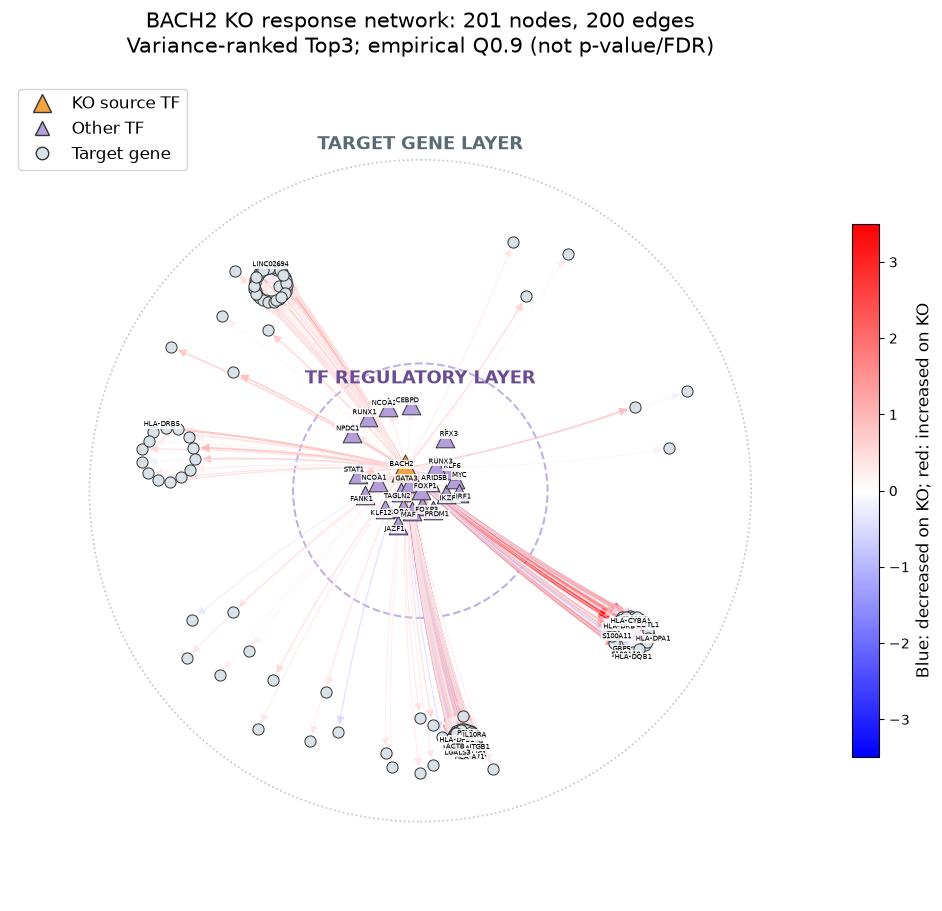

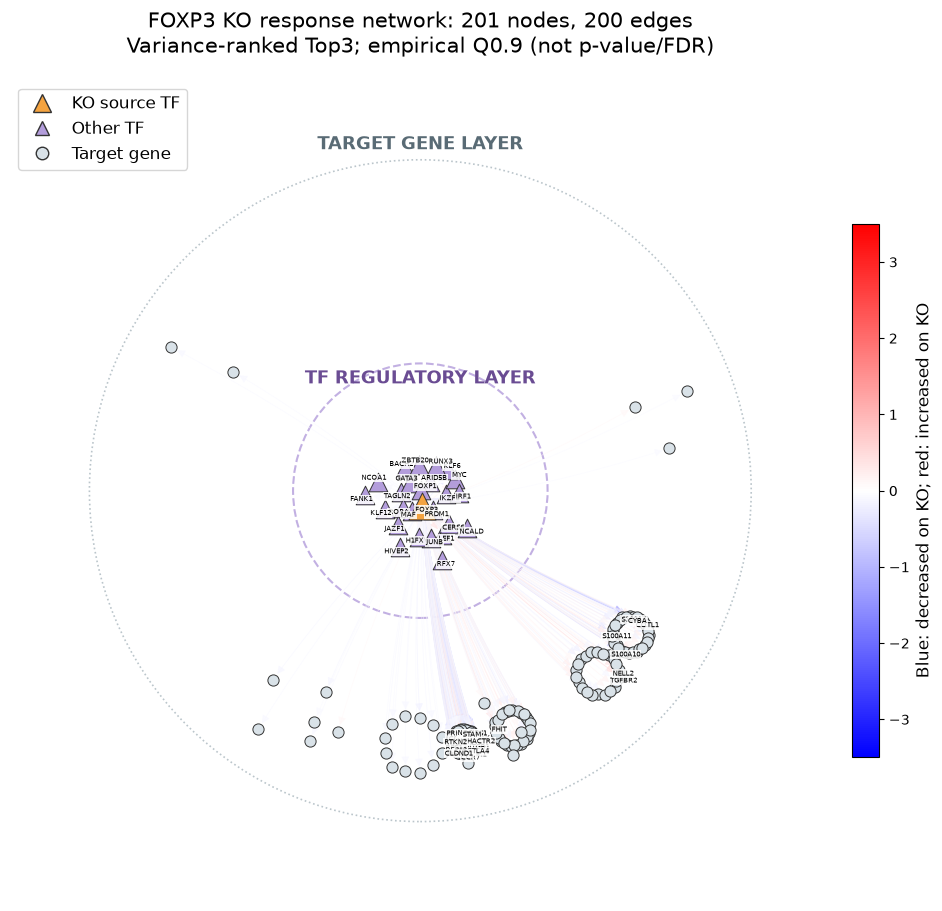

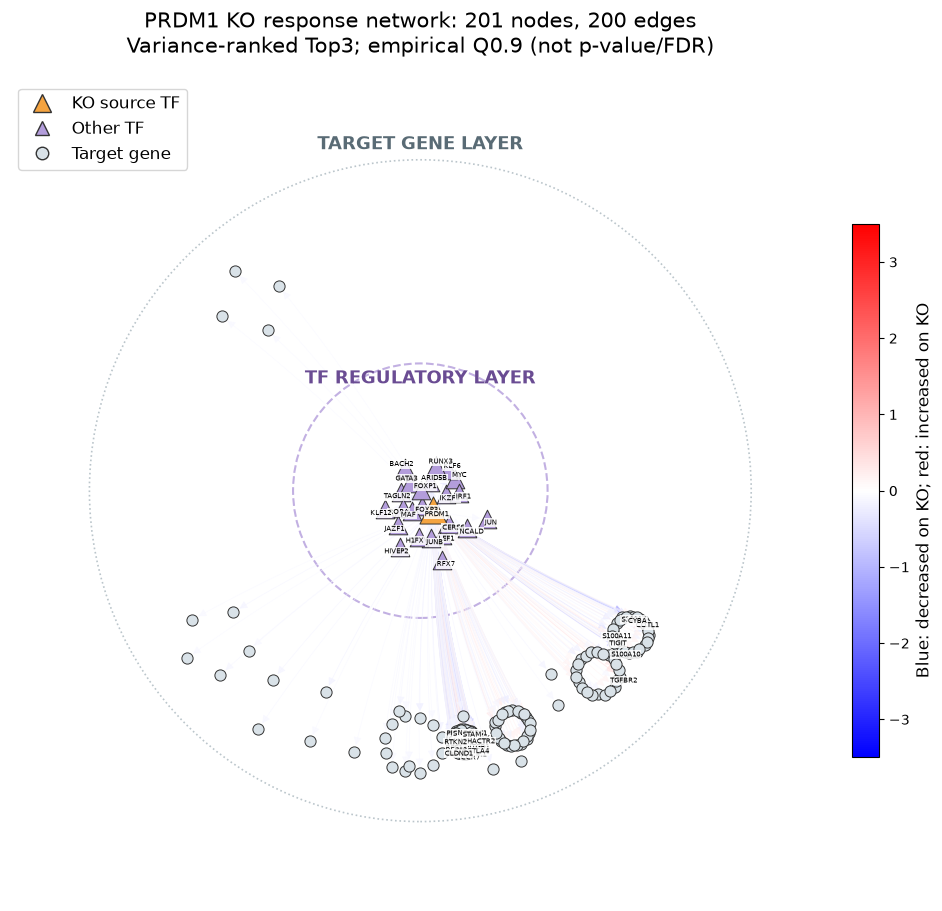

In [40]:
tf_ko_top3_required = ['tf_ko_sources', 'tf_ko_graph', 'tf_ko_positions', 'tf_ko_tf_names',
                       'tf_ko_color_norm', 'tf_ko_edge_cmap', 'tf_ko_color_limit', 'tf_ko_network_ax']
if any(name not in globals() for name in tf_ko_top3_required):
    raise RuntimeError('Run sections 10 and 10-1 before plotting individual Top3 networks.')
tf_ko_top3_sources = tf_ko_sources.sort_values('rank').head(3)['TF'].tolist()
if len(tf_ko_top3_sources) != 3:
    raise ValueError('Expected three variance-ranked source TFs.')
tf_ko_top3_missing = [g for g in tf_ko_top3_sources if g not in tf_ko_graph or tf_ko_graph.out_degree(g) == 0]
if tf_ko_top3_missing:
    raise ValueError(f'Top3 TFs have no valid KO edges: {tf_ko_top3_missing}; inspect tf_ko_diagnostics.')
tf_ko_top3_figures, tf_ko_top3_graphs = {}, {}
for source in tf_ko_top3_sources:
    graph = tf_ko_graph.edge_subgraph(list(tf_ko_graph.out_edges(source))).copy()
    edges = list(graph.edges)
    powers = np.array([graph[u][v]['network_power'] for u, v in edges])
    fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
    ax.add_patch(plt.Circle((0, 0), 2.5, fill=False, edgecolor='#B39DDB', linewidth=1.5, linestyle='--', alpha=0.8))
    ax.add_patch(plt.Circle((0, 0), 6.5, fill=False, edgecolor='#9EADB5', linewidth=1.2, linestyle=':', alpha=0.7))
    nx.draw_networkx_edges(graph, tf_ko_positions, ax=ax, edgelist=edges,
        edge_color=tf_ko_edge_cmap(tf_ko_color_norm(powers)),
        width=0.4 + 2.6 * np.abs(powers) / tf_ko_color_limit, arrows=True, arrowstyle='-|>',
        arrowsize=12, node_size=100, connectionstyle='arc3,rad=0.04', alpha=0.65,
        min_source_margin=3, min_target_margin=5)
    groups = [([g for g in graph if g not in tf_ko_tf_names], 'o', '#D9E2E8', 65),
              ([g for g in graph if g in tf_ko_tf_names and g != source], '^', '#B39DDB', 180),
              ([source], '^', '#F4A340', 380)]
    for nodes, shape, color, size in groups:
        if nodes:
            nx.draw_networkx_nodes(graph, tf_ko_positions, ax=ax, nodelist=nodes, node_shape=shape,
                node_color=color, node_size=size, edgecolors='#333333', linewidths=0.7)
    strongest = sorted(graph.successors(source), key=lambda g: (-abs(graph[source][g]['network_power']), g))[:30]
    labels = {g: g for g in graph if g in tf_ko_tf_names or g in strongest}
    label_positions = {g: (tf_ko_positions[g][0] + 0.08 * np.sign(tf_ko_positions[g][0] or 1),
                           tf_ko_positions[g][1] + 0.08 * np.sign(tf_ko_positions[g][1] or 1)) for g in labels}
    nx.draw_networkx_labels(graph, label_positions, labels=labels, ax=ax, font_size=5, font_weight='medium',
        bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none', 'pad': 0.7})
    colorbar = fig.colorbar(ScalarMappable(norm=tf_ko_color_norm, cmap=tf_ko_edge_cmap), ax=ax, shrink=0.65, pad=0.02)
    colorbar.set_label('Blue: decreased on KO; red: increased on KO', fontsize=12)
    ax.legend(handles=[
        Line2D([], [], marker='^', color='none', markerfacecolor='#F4A340', markeredgecolor='#333333', markersize=13, label='KO source TF'),
        Line2D([], [], marker='^', color='none', markerfacecolor='#B39DDB', markeredgecolor='#333333', markersize=10, label='Other TF'),
        Line2D([], [], marker='o', color='none', markerfacecolor='#D9E2E8', markeredgecolor='#333333', markersize=9, label='Target gene')],
        loc='upper left', fontsize=12, frameon=True)
    ax.text(0, 2.2, 'TF REGULATORY LAYER', ha='center', va='center', fontsize=13, fontweight='bold', color='#6A4C93')
    ax.text(0, 6.8, 'TARGET GENE LAYER', ha='center', va='center', fontsize=13, fontweight='bold', color='#596B75')
    ax.set_title(f'{source} KO response network: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges\n'
                 'Variance-ranked Top3; empirical Q0.9 (not p-value/FDR)', fontsize=15, pad=20)
    ax.set_aspect('equal')
    ax.set_xlim(tf_ko_network_ax.get_xlim())
    ax.set_ylim(tf_ko_network_ax.get_ylim())
    ax.set_axis_off()
    tf_ko_top3_graphs[source] = graph
    tf_ko_top3_figures[source] = fig
    plt.show()

### 10-3. All decoder-available TF KO network: TF-only centrality Top10

**8번·10번 실행 후 이 셀을 실행합니다.** 분산 Top10에 한정하지 않고 TF 목록과 원래 decoder 유전자의 교집합인 **전체 TF(현재 141개)**를 각각 KO합니다. 10번의 동일한 고정 decoder·최적화 함수·Treg fraction ≥0.5 step을 사용합니다. TF별 자기 자신을 제외한 전체 decoder 유전자의 `abs(median(KO−baseline))` quantile 0.9 이상이며 0이 아닌 관계를 선택합니다. 모든 선택 step에서 KO 출력 절댓값 ≤0.001을 충족하지 못하면 경고·진단표에 남기고 해당 source의 outgoing edge를 만들지 않습니다. 기존 Top10 네트워크와 그림은 변경하지 않습니다. 전체 TF 최적화는 시간이 걸립니다.

전체 TF·target 유전자의 **방향성·무가중 그래프에서 중심성을 계산한 뒤 TF만 추려 지표별 Top10**을 그립니다. Betweenness(normalized), incoming Closeness(wf_improved), total in+out Degree/(N−1), incoming Eigenvector(L2 정규화·수렴/잔차 검증), PageRank(alpha=0.85)를 사용합니다. Power 부호·크기는 이번 위상 분석에 가중치로 쓰지 않습니다. 고립 TF도 노드로 포함합니다. 동점은 유전자명순입니다. Incoming 지표는 영향을 받는 TF를 강조하며 source 조절력 순위와 다릅니다.

전체 관계: `all_tf_ko_network_all`; 선택 관계: `all_tf_ko_network_edges`; KO 진단: `all_tf_ko_diagnostics`. 전체 노드 점수: `tf_ko_centrality_scores`; TF 점수: `all_tf_centrality_tf_scores`; 지표별 Top10: `tf_ko_centrality_top10`. 주황색은 source KO 성공 TF, 회색은 KO 실패 TF입니다(다른 성공 source로부터의 incoming edge는 유지).

**KO 실패 TF의 낮은 중심성을 생물학적 중요도 부재로 해석하지 않습니다.** 비양수 baseline 발현과 외삽 거리도 진단표에서 확인해야 합니다. Quantile 기준은 경험적 선택이며 p-value/FDR·직접 결합·인과성 증거가 아닙니다. 그림·표는 노트북에만 저장하며 기존 분석을 덮어쓰지 않습니다.


[1/141] ABL1: max abs target=0.000101328; KO_valid=True
[2/141] ACO1: max abs target=0.00022383; KO_valid=True
[3/141] AIRE: max abs target=2.53767e-05; KO_valid=True
[4/141] ANXA1: max abs target=0.357845; KO_valid=False


/tmp/ipykernel_895139/65359300.py:47: RuntimeWarning: ANXA1: full-TF KO tolerance failed; no outgoing response edges created.
  warnings.warn(f'{source}: full-TF KO tolerance failed; no outgoing response edges created.', RuntimeWarning)


[5/141] ARG1: max abs target=4.4778e-05; KO_valid=True
[6/141] ARID3A: max abs target=0.000197421; KO_valid=True
[7/141] ARID5B: max abs target=0.0635498; KO_valid=False


/tmp/ipykernel_895139/65359300.py:47: RuntimeWarning: ARID5B: full-TF KO tolerance failed; no outgoing response edges created.
  warnings.warn(f'{source}: full-TF KO tolerance failed; no outgoing response edges created.', RuntimeWarning)


[8/141] ASCL2: max abs target=1.87941e-05; KO_valid=True
[9/141] BACH2: max abs target=5.1111e-05; KO_valid=True
[10/141] BARX1: max abs target=1.61938e-05; KO_valid=True
[11/141] BCL6: max abs target=0.000129446; KO_valid=True
[12/141] BHLHE40: max abs target=8.08239e-05; KO_valid=True
[13/141] BOLL: max abs target=1.20029e-05; KO_valid=True
[14/141] BRCA1: max abs target=4.97252e-05; KO_valid=True
[15/141] CEBPD: max abs target=7.25836e-05; KO_valid=True
[16/141] CERS6: max abs target=3.3224e-05; KO_valid=True
[17/141] CNOT6: max abs target=4.0561e-05; KO_valid=True
[18/141] CXXC5: max abs target=0.00013952; KO_valid=True
[19/141] DMRT2: max abs target=3.5882e-05; KO_valid=True
[20/141] E2F3: max abs target=7.10264e-05; KO_valid=True
[21/141] EBF1: max abs target=4.14243e-05; KO_valid=True
[22/141] EBF4: max abs target=0.000128296; KO_valid=True
[23/141] EN1: max abs target=4.92558e-05; KO_valid=True
[24/141] EOMES: max abs target=4.90546e-05; KO_valid=True
[25/141] FANK1: max abs ta

/tmp/ipykernel_895139/65359300.py:47: RuntimeWarning: FOXP1: full-TF KO tolerance failed; no outgoing response edges created.
  warnings.warn(f'{source}: full-TF KO tolerance failed; no outgoing response edges created.', RuntimeWarning)


... (38 outputs left out)

[115/141] ZKSCAN3: max abs target=0.000244424; KO_valid=True
[116/141] ZNF248: max abs target=1.1825e-05; KO_valid=True
[117/141] ZNF331: max abs target=2.37674e-05; KO_valid=True
[118/141] ZNF404: max abs target=6.32852e-05; KO_valid=True
[119/141] ZNF407: max abs target=0.0230374; KO_valid=False


/tmp/ipykernel_895139/65359300.py:47: RuntimeWarning: ZNF407: full-TF KO tolerance failed; no outgoing response edges created.
  warnings.warn(f'{source}: full-TF KO tolerance failed; no outgoing response edges created.', RuntimeWarning)


[120/141] ZNF418: max abs target=4.14997e-05; KO_valid=True
[121/141] ZNF438: max abs target=0.000383779; KO_valid=True
[122/141] ZNF440: max abs target=0.000838071; KO_valid=True
[123/141] ZNF461: max abs target=0.000174999; KO_valid=True
[124/141] ZNF516: max abs target=2.98209e-05; KO_valid=True
[125/141] ZNF532: max abs target=2.18302e-05; KO_valid=True
[126/141] ZNF569: max abs target=4.29973e-05; KO_valid=True
[127/141] ZNF578: max abs target=9.05208e-05; KO_valid=True
[128/141] ZNF595: max abs target=8.15094e-06; KO_valid=True
[129/141] ZNF621: max abs target=6.35684e-05; KO_valid=True
[130/141] ZNF646: max abs target=9.29087e-05; KO_valid=True
[131/141] ZNF66: max abs target=2.34619e-05; KO_valid=True
[132/141] ZNF670: max abs target=0.000164762; KO_valid=True
[133/141] ZNF683: max abs target=2.67578e-05; KO_valid=True
[134/141] ZNF704: max abs target=0.000124261; KO_valid=True
[135/141] ZNF710: max abs target=5.12935e-05; KO_valid=True
[136/141] ZNF717: max abs target=1.62348e

,source_TF,KO_valid,n_paired_steps,max_abs_KO_target,n_failed_steps,baseline_source_median,median_nearest_cell_distance_baseline,median_nearest_cell_distance_KO,median_latent_shift_l2
0,ABL1,True,220,0.000101,0,0.044277,0.091806,1.861388,2.468354
1,ACO1,True,220,0.000224,0,0.027871,0.091806,2.349075,2.463314
2,AIRE,True,220,0.000025,0,0.004480,0.091806,0.241980,0.311400
3,ANXA1,False,220,0.357845,220,0.675619,0.091806,11.339820,12.543132
4,ARG1,True,220,0.000045,0,0.028811,0.091806,1.745747,2.097915
...,...,...,...,...,...,...,...,...,...
136,ZNF765,True,220,0.000089,0,0.074301,0.091806,5.466558,5.594838
137,ZNF80,True,220,0.000033,0,0.041350,0.091806,1.867416,2.134695
138,ZNF81,True,220,0.000031,0,0.037152,0.091806,4.193664,4.224400
139,ZNF853,True,220,0.000101,0,0.016451,0.091806,3.539063,3.642032


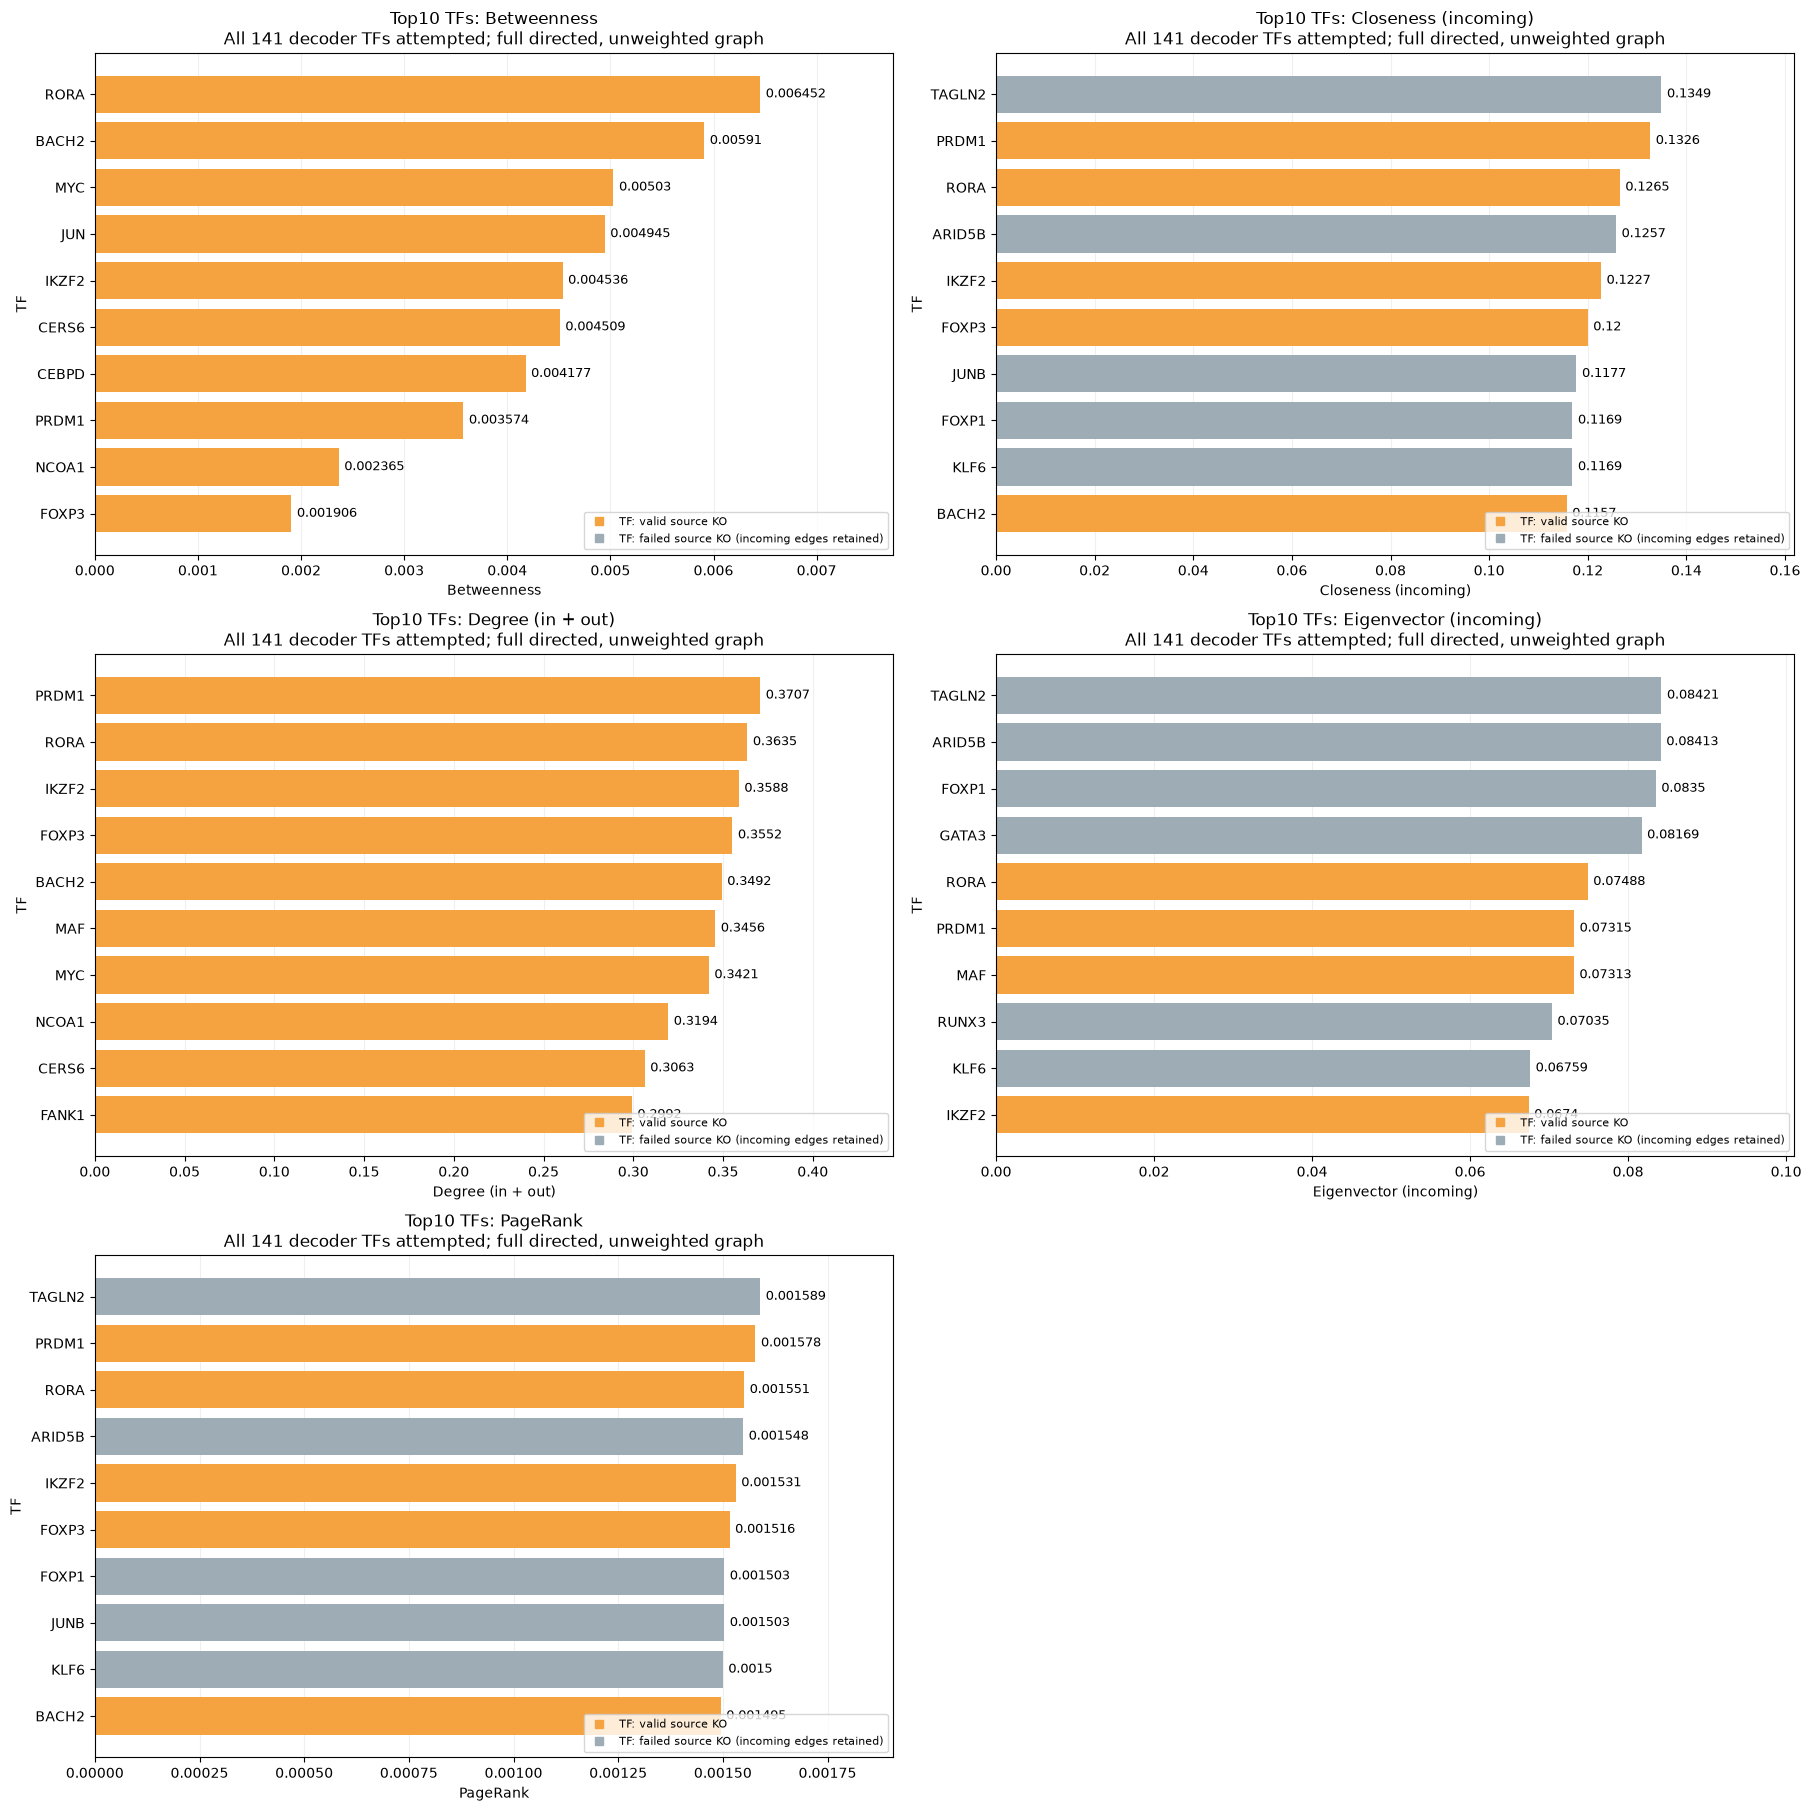

,gene,is_TF,KO_valid,Betweenness,Closeness (incoming),Degree (in + out),Eigenvector (incoming),PageRank
3,ABL1,True,True,0.000000,0.000000,0.238379,1.380047e-19,0.001059
41,ACO1,True,True,0.000835,0.056456,0.241955,6.042065e-03,0.001074
56,AIRE,True,True,0.000040,0.001192,0.239571,2.484085e-18,0.001063
87,ANXA1,True,False,0.000000,0.058851,0.028605,3.749374e-03,0.001168
99,ARG1,True,True,0.000000,0.000000,0.238379,1.380047e-19,0.001059
...,...,...,...,...,...,...,...,...
833,ZNF765,True,True,0.000000,0.000000,0.238379,1.380047e-19,0.001059
834,ZNF80,True,True,0.000000,0.000000,0.238379,1.380047e-19,0.001059
835,ZNF81,True,True,0.000000,0.000000,0.238379,1.380047e-19,0.001059
836,ZNF853,True,True,0.000000,0.000000,0.238379,1.380047e-19,0.001059


In [41]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings

all_tf_required = ['optimize_tf_ko_latent', 'tf_ko_symbols', 'tf_ko_decoder', 'tf_ko_z_base',
                   'tf_ko_baseline', 'tf_ko_knn', 'tf_ko_base_distance', 'tf_ko_step_ids',
                   'tf_variance_symbols', 'tf_plot_ranking', 'tf_path_decoder']
all_tf_missing = [name for name in all_tf_required if name not in globals()]
if all_tf_missing:
    raise RuntimeError(f'Run sections 8 and 10 first. Missing: {all_tf_missing}')

all_tf_sources = pd.Index(tf_ko_symbols[tf_ko_symbols.isin(tf_variance_symbols)]).sort_values()
if all_tf_sources.empty or not all_tf_sources.is_unique:
    raise ValueError('Expected distinct decoder-available TFs.')

if TF_KO_FRACTION != 0.5 or TF_KO_QUANTILE != 0.9 or TF_KO_TOLERANCE != 1e-3:
    raise ValueError('Expected section 10 settings: Treg fraction >=0.5, quantile 0.9, KO tolerance 0.001.')

all_tf_frames, all_tf_diagnostic_rows = [], []

for source_index, source in enumerate(all_tf_sources, 1):
    position = int(tf_ko_symbols.get_loc(source))
    coordinates, decoded = optimize_tf_ko_latent(tf_ko_decoder, tf_ko_z_base, position)
    residual = np.abs(decoded[:, position])
    passed = bool((residual <= TF_KO_TOLERANCE).all())
    distance = tf_ko_knn.kneighbors(coordinates)[0].ravel()

    all_tf_diagnostic_rows.append({
        'source_TF': source,
        'KO_valid': passed,
        'n_paired_steps': len(tf_ko_step_ids),
        'max_abs_KO_target': float(residual.max()),
        'n_failed_steps': int((residual > TF_KO_TOLERANCE).sum()),
        'baseline_source_median': float(np.median(tf_ko_baseline[:, position])),
        'median_nearest_cell_distance_baseline': float(np.median(tf_ko_base_distance)),
        'median_nearest_cell_distance_KO': float(np.median(distance)),
        'median_latent_shift_l2': float(np.median(np.linalg.norm(
            coordinates - tf_ko_z_base.cpu().numpy(), axis=1)))
    })

    print(f'[{source_index}/{len(all_tf_sources)}] {source}: max abs target={residual.max():.6g}; KO_valid={passed}', flush=True)

    if not passed:
        warnings.warn(f'{source}: full-TF KO tolerance failed; no outgoing response edges created.', RuntimeWarning)
        continue

    power = np.median(decoded.astype(np.float64) - tf_ko_baseline.astype(np.float64), axis=0)
    nonself = np.arange(len(tf_ko_symbols)) != position
    cutoff = float(np.quantile(np.abs(power[nonself]), 0.9, method='linear'))

    frame = pd.DataFrame({
        'source_TF': source,
        'target_gene': tf_ko_symbols[nonself],
        'network_power': power[nonself],
        'abs_network_power': np.abs(power[nonself]),
        'baseline_median': np.median(tf_ko_baseline[:, nonself], axis=0),
        'KO_median': np.median(decoded[:, nonself], axis=0),
        'empirical_q90_cutoff': cutoff,
        'n_paired_steps': len(tf_ko_step_ids)
    })

    frame['KO_response'] = np.select(
        [frame.network_power < 0, frame.network_power > 0],
        ['decreased_on_KO', 'increased_on_KO'],
        default='unchanged'
    )

    frame['empirical_significant'] = (
        (frame.abs_network_power >= cutoff) &
        (frame.abs_network_power > 0)
    )

    all_tf_frames.append(frame)

all_tf_ko_diagnostics = pd.DataFrame(all_tf_diagnostic_rows)
display(all_tf_ko_diagnostics)

if not all_tf_frames:
    raise RuntimeError('All decoder-available TF KOs failed; inspect all_tf_ko_diagnostics.')

all_tf_ko_network_all = pd.concat(all_tf_frames, ignore_index=True)

all_tf_ko_network_edges = all_tf_ko_network_all.loc[
    all_tf_ko_network_all.empirical_significant
].sort_values(
    ['source_TF', 'abs_network_power', 'target_gene'],
    ascending=[True, False, True],
    kind='stable'
).reset_index(drop=True)

if all_tf_ko_network_edges.empty:
    raise RuntimeError('No nonzero selected edges in full-TF KO network.')

for key, value in tf_ko_decoder.state_dict().items():
    torch.testing.assert_close(value, tf_path_decoder.state_dict()[key], rtol=0, atol=0)

tf_ko_centrality_graph = nx.from_pandas_edgelist(
    all_tf_ko_network_edges,
    'source_TF',
    'target_gene',
    create_using=nx.DiGraph()
)

tf_ko_centrality_graph.add_nodes_from(all_tf_sources)
tf_ko_centrality_nodes = sorted(tf_ko_centrality_graph)

tf_ko_centrality_metrics = {
    'Betweenness': nx.betweenness_centrality(
        tf_ko_centrality_graph,
        normalized=True,
        weight=None,
        endpoints=False
    ),
    'Closeness (incoming)': nx.closeness_centrality(
        tf_ko_centrality_graph,
        distance=None,
        wf_improved=True
    ),
    'Degree (in + out)': nx.degree_centrality(tf_ko_centrality_graph),
    'Eigenvector (incoming)': nx.eigenvector_centrality(
        tf_ko_centrality_graph,
        max_iter=10000,
        tol=1e-12,
        weight=None
    ),
    'PageRank': nx.pagerank(
        tf_ko_centrality_graph,
        alpha=0.85,
        max_iter=10000,
        tol=1e-12,
        weight=None
    )
}

tf_ko_centrality_adjacency = nx.to_scipy_sparse_array(
    tf_ko_centrality_graph,
    nodelist=tf_ko_centrality_nodes,
    weight=None,
    dtype=float
)

tf_ko_centrality_eigenvector = np.array([
    tf_ko_centrality_metrics['Eigenvector (incoming)'][g]
    for g in tf_ko_centrality_nodes
])

tf_ko_centrality_product = tf_ko_centrality_adjacency.T @ tf_ko_centrality_eigenvector

tf_ko_centrality_eigenvalue = float(
    tf_ko_centrality_eigenvector @ tf_ko_centrality_product
)

tf_ko_centrality_residual = float(np.linalg.norm(
    tf_ko_centrality_product -
    tf_ko_centrality_eigenvalue * tf_ko_centrality_eigenvector
))

if tf_ko_centrality_eigenvalue <= 1e-8 or tf_ko_centrality_residual > 1e-7:
    raise RuntimeError(
        f'Degenerate/inaccurate eigenvector: eigenvalue={tf_ko_centrality_eigenvalue}, '
        f'residual={tf_ko_centrality_residual}.'
    )

tf_ko_centrality_scores = pd.DataFrame({'gene': tf_ko_centrality_nodes})

tf_ko_centrality_scores['is_TF'] = tf_ko_centrality_scores.gene.isin(all_tf_sources)

tf_ko_centrality_scores['KO_valid'] = tf_ko_centrality_scores.gene.map(
    all_tf_ko_diagnostics.set_index('source_TF').KO_valid
).astype('boolean')

for metric, scores in tf_ko_centrality_metrics.items():
    tf_ko_centrality_scores[metric] = tf_ko_centrality_scores.gene.map(scores)

    if not np.isfinite(tf_ko_centrality_scores[metric]).all() or (
        tf_ko_centrality_scores[metric] < 0
    ).any():
        raise FloatingPointError(f'Invalid centrality scores: {metric}')

all_tf_centrality_tf_scores = tf_ko_centrality_scores.loc[
    tf_ko_centrality_scores.is_TF
].copy()

tf_ko_centrality_top10, tf_ko_centrality_figures = {}, {}

fig, axes = plt.subplots(3, 2, figsize=(18, 18), constrained_layout=True)
axes = axes.flatten()

for i, metric in enumerate(tf_ko_centrality_metrics):
    top = all_tf_centrality_tf_scores[
        ['gene', 'KO_valid', metric]
    ].sort_values(
        [metric, 'gene'],
        ascending=[False, True],
        kind='stable'
    ).head(10).reset_index(drop=True)

    top.insert(0, 'rank', np.arange(1, len(top) + 1))
    tf_ko_centrality_top10[metric] = top
    draw = top.iloc[::-1]
    ax = axes[i]

    bars = ax.barh(
        draw.gene,
        draw[metric],
        color=np.where(draw.KO_valid, '#F4A340', '#9EADB5')
    )

    ax.bar_label(
        bars,
        labels=[f'{v:.4g}' for v in draw[metric]],
        padding=4,
        fontsize=9
    )

    ax.margins(x=0.2)

    ax.set(
        xlabel=metric,
        ylabel='TF',
        title=f'Top10 TFs: {metric}\n'
              f'All {len(all_tf_sources)} decoder TFs attempted; full directed, unweighted graph'
    )

    ax.legend(
        handles=[
            Line2D([], [], marker='s', ls='none', color='#F4A340',
                   label='TF: valid source KO'),
            Line2D([], [], marker='s', ls='none', color='#9EADB5',
                   label='TF: failed source KO (incoming edges retained)')
        ],
        loc='lower right',
        fontsize=8
    )

    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    tf_ko_centrality_figures[metric] = fig

for i in range(len(tf_ko_centrality_metrics), len(axes)):
    axes[i].set_visible(False)

plt.show()


display(all_tf_centrality_tf_scores)

### 11. 기존 DQN PCA 좌표 고정: FOXP3 KO 세포별 네트워크 반응 벡터

- **8번·10번을 먼저 실행합니다.** 새 `tf_ko_network_edges`의 FOXP3 관계만 사용하며 expanded/IKZF2 GRN이나 그 reference는 사용하지 않습니다.
- 원래 고정 VAE와 PCA에서 실제 Naive·Treg **전체 세포의 Z_space**를 decode합니다. 그리드 중심이나 관측 발현에 KO를 적용하지 않습니다.
- 참조 발현은 네트워크 추정에 사용한 Treg fraction ≥0.5 DQN step의 `median(decoded_FOXP3)`입니다. 세포별 `response_scale = max(decoded_FOXP3, 0) / reference`를 사용합니다. Reference보다 큰 세포는 외삽이며 배율 상한은 자르지 않습니다.
- 새 power 부호는 **KO−baseline**이므로 `target_KO = target + response_scale * network_power`, `FOXP3_KO = 0`을 한 번 적용합니다. Raw decoder log1p 출력은 0 clipping하지 않습니다. 비target은 그대로 유지합니다. FOXP3가 0 이하이면 target 배율은 0이고 source만 0으로 설정합니다. 음수 발현과 reference 초과 세포 수를 진단표에 기록합니다.
- 방향은 `(original_encoder_mu(xKO) − original_encoder_mu(xBaseline)) @ original_pca.components_.T`입니다. 양쪽을 같은 encoder로 재인코딩하여 decoder 재구성 오차를 이동량에서 제거합니다. 화살표 시작점은 원래 실제 세포 PCA 좌표입니다.
- 길이는 **적용된 target 변화량 L2 × 모든 세포 공통 선형 배율**입니다. Source 자체 제거량은 target power에서 제외합니다. 큰 power를 clipping하거나 화살표 길이를 고정하지 않습니다. 방향이 수치적으로 0이면 0 벡터로 기록하고 경고합니다.
- 점 색은 기존 세포타입 색(Naive 파랑, Treg 빨강)입니다. 그리드 평균 없이 모든 세포에 벡터를 계산합니다. `foxp3_vec_cell_vectors`, `foxp3_vec_cell_edges`, `foxp3_vec_cell_diagnostics` 및 figure는 노트북에만 보존합니다. 기존 모델·경로·IKZF2 결과 파일은 덮어쓰지 않습니다.
- **검증:** 저장된 DQN PCA 좌표, 고정 decoder, 유전자 순서, signed target 변화, 비target 보존, 화살표 길이와 target L2 power 비례를 확인합니다.
- Treg-like DQN 네트워크를 전체 세포에 전이하는 모델 가정이며, 실제 KO 인과효과·시간 velocity가 아닙니다.

- 표시 조정: 세포 점 alpha=0.9, 최대 화살표 길이는 PCA 최대 축 범위의 3%(기존 8%의 37.5%). 세포 간 power 비례는 유지합니다.


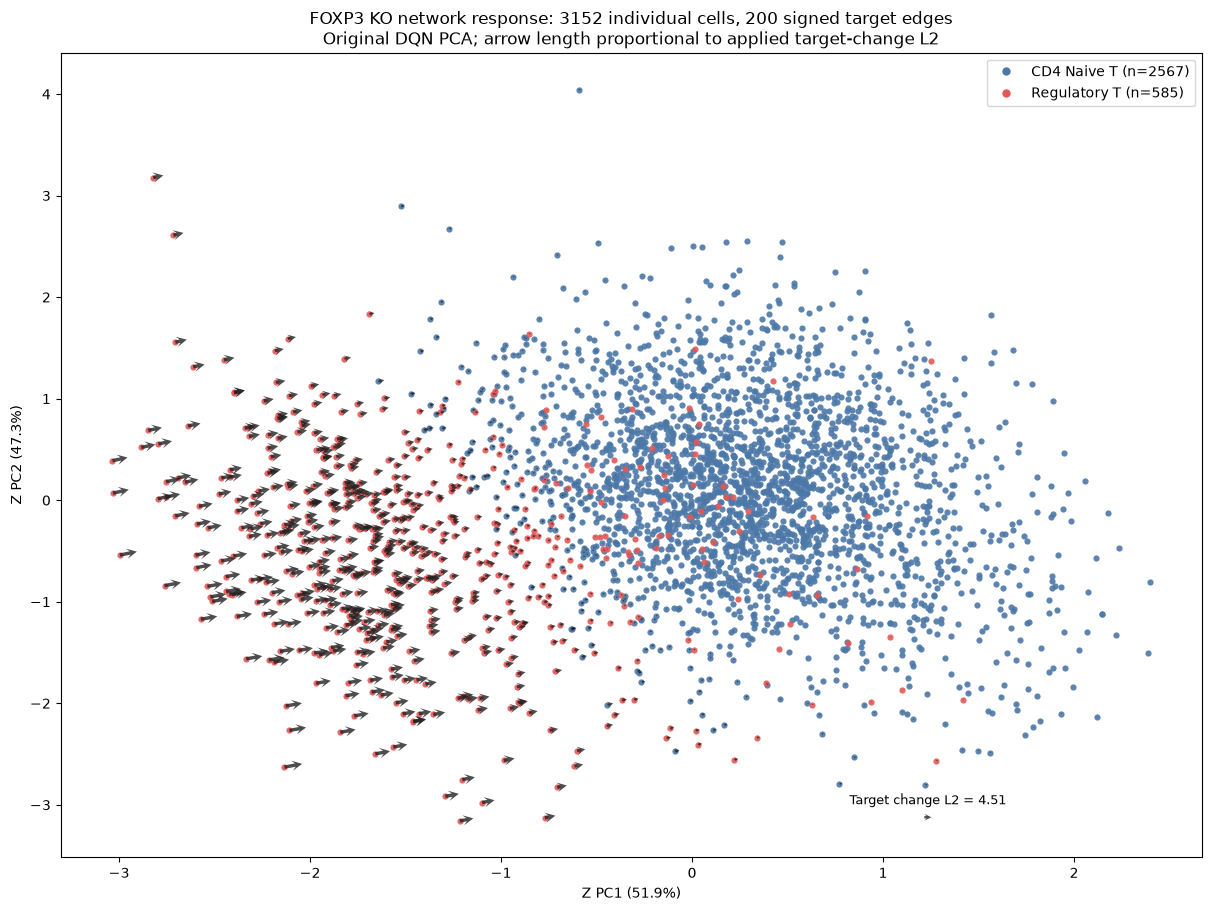

In [42]:

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

foxp3_vec_required = ['tf_ko_network_edges', 'tf_ko_baseline', 'tf_ko_step_ids', 'tf_ko_sources',
                  'tf_ko_diagnostics', 'tf_decoder_symbols', 'tf_path_decoder', 'tf_plot_cell_z',
                  'tf_plot_cell_barcodes', 'tf_plot_cell_types', 'TF_RESULT_DIR']
foxp3_vec_missing = [name for name in foxp3_vec_required if name not in globals()]
if foxp3_vec_missing:
    raise RuntimeError(f'Run sections 8 and 10 first. Missing: {foxp3_vec_missing}')
foxp3_vec_cell_edges = tf_ko_network_edges.loc[tf_ko_network_edges['source_TF'] == 'FOXP3'].copy()
if foxp3_vec_cell_edges.empty or not tf_ko_diagnostics.set_index('source_TF').loc['FOXP3', 'KO_valid']:
    raise ValueError('No valid FOXP3 KO network; inspect section 10 diagnostics.')
foxp3_vec_cell_symbols = pd.Index(tf_decoder_symbols)
foxp3_vec_source_position = int(foxp3_vec_cell_symbols.get_indexer(['FOXP3'])[0])
foxp3_vec_target_positions = foxp3_vec_cell_symbols.get_indexer(foxp3_vec_cell_edges['target_gene'])
foxp3_vec_cell_power = foxp3_vec_cell_edges['network_power'].to_numpy(dtype=np.float64)
if (foxp3_vec_source_position < 0 or (foxp3_vec_target_positions < 0).any()
        or (foxp3_vec_target_positions == foxp3_vec_source_position).any()
        or foxp3_vec_cell_edges['target_gene'].duplicated().any()
        or not np.isfinite(foxp3_vec_cell_power).all()):
    raise ValueError('Invalid FOXP3 source, targets or signed network powers.')
foxp3_vec_reference = float(np.median(tf_ko_baseline[:, foxp3_vec_source_position]))
if not np.isfinite(foxp3_vec_reference) or foxp3_vec_reference <= 0:
    raise ValueError('FOXP3 reference must be a positive finite Treg-like-step baseline median.')
foxp3_vec_checkpoint = torch.load(Path(TF_RESULT_DIR) / 'coordinate_models.pt', map_location='cpu', weights_only=False)
foxp3_vec_components = np.asarray(foxp3_vec_checkpoint['pca_components'], dtype=np.float64)
foxp3_vec_mean = np.asarray(foxp3_vec_checkpoint['pca_mean'], dtype=np.float64)
with np.load(Path(TF_RESULT_DIR) / 'coordinate_graph.npz', allow_pickle=False) as saved:
    foxp3_vec_z = saved['Z_space'].copy()
    foxp3_vec_barcodes = saved['cell_barcodes'].astype(str)
    foxp3_vec_path_z = saved['coordinate_space'].copy()
    foxp3_vec_saved_path_xy = saved['coordinate_pca'].copy()
np.testing.assert_array_equal(foxp3_vec_z, tf_plot_cell_z)
np.testing.assert_array_equal(foxp3_vec_barcodes, tf_plot_cell_barcodes)
foxp3_vec_subtypes = np.asarray(tf_plot_cell_types).astype(str)
if len(foxp3_vec_subtypes) != len(foxp3_vec_z) or not np.isin(foxp3_vec_subtypes, ['CD4 Naive T', 'Regulatory T']).all():
    raise ValueError('Invalid subtype overlay or cell ordering.')
foxp3_vec_cell_xy = (foxp3_vec_z.astype(np.float64) - foxp3_vec_mean) @ foxp3_vec_components.T
np.testing.assert_allclose((foxp3_vec_path_z - foxp3_vec_mean) @ foxp3_vec_components.T, foxp3_vec_saved_path_xy, atol=1e-4, rtol=1e-4)
foxp3_vec_path_csv = pd.read_csv(Path(TF_RESULT_DIR) / 'dqn_trajectory.csv')
np.testing.assert_allclose(foxp3_vec_saved_path_xy, foxp3_vec_path_csv[['PC1', 'PC2']].to_numpy(), atol=1e-4, rtol=1e-4)
if all(name in globals() for name in ('pca', 'Z_pca')):
    np.testing.assert_array_equal(pca.components_, foxp3_vec_checkpoint['pca_components'])
    np.testing.assert_array_equal(pca.mean_, foxp3_vec_checkpoint['pca_mean'])
    np.testing.assert_allclose(Z_pca, foxp3_vec_cell_xy, atol=1e-4, rtol=1e-4)
foxp3_vec_state = foxp3_vec_checkpoint['vae']
foxp3_vec_encoder = nn.Sequential(
    nn.Linear(foxp3_vec_state['encoder.0.weight'].shape[1], foxp3_vec_state['encoder.0.weight'].shape[0]), nn.ReLU(),
    nn.Linear(foxp3_vec_state['encoder.2.weight'].shape[1], foxp3_vec_state['encoder.2.weight'].shape[0]), nn.ReLU())
foxp3_vec_mu = nn.Linear(foxp3_vec_state['mu.weight'].shape[1], foxp3_vec_state['mu.weight'].shape[0])
for module, prefix in [(foxp3_vec_encoder, 'encoder.'), (foxp3_vec_mu, 'mu.')]:
    module.load_state_dict({k.removeprefix(prefix): v for k, v in foxp3_vec_state.items() if k.startswith(prefix)})
    module.eval().requires_grad_(False)
for key, value in tf_path_decoder.state_dict().items():
    torch.testing.assert_close(value.cpu(), foxp3_vec_state['decoder.' + key], rtol=0, atol=0)
if len(foxp3_vec_cell_symbols) != foxp3_vec_state['encoder.0.weight'].shape[1]:
    raise ValueError('Original encoder input dimension does not match the decoder gene mapping.')
foxp3_vec_mean_encoder = nn.Sequential(foxp3_vec_encoder, foxp3_vec_mu)


def foxp3_vec_forward(module, values):
    if not len(values) or not np.isfinite(values).all():
        raise ValueError('Expected nonempty finite model inputs.')
    device = next(module.parameters()).device
    with torch.no_grad():
        outputs = np.concatenate([module(torch.tensor(values[start:start + 256], dtype=torch.float32, device=device)).cpu().numpy()
                                  for start in range(0, len(values), 256)]).astype(np.float64)
    if not np.isfinite(outputs).all():
        raise FloatingPointError('Non-finite FOXP3 vector model output.')
    return outputs


foxp3_vec_before = foxp3_vec_forward(tf_path_decoder, foxp3_vec_z)
foxp3_vec_response_scale = np.maximum(foxp3_vec_before[:, foxp3_vec_source_position], 0) / foxp3_vec_reference
foxp3_vec_target_delta = foxp3_vec_response_scale[:, None] * foxp3_vec_cell_power[None, :]
foxp3_vec_after = foxp3_vec_before.copy()
foxp3_vec_after[:, foxp3_vec_target_positions] += foxp3_vec_target_delta
foxp3_vec_after[:, foxp3_vec_source_position] = 0
foxp3_vec_encoded_before = foxp3_vec_forward(foxp3_vec_mean_encoder, foxp3_vec_before)
foxp3_vec_encoded_after = foxp3_vec_forward(foxp3_vec_mean_encoder, foxp3_vec_after)
foxp3_vec_delta_z = foxp3_vec_encoded_after - foxp3_vec_encoded_before
foxp3_vec_delta_pc = foxp3_vec_delta_z @ foxp3_vec_components.T
foxp3_vec_pca_magnitude = np.linalg.norm(foxp3_vec_delta_pc, axis=1)
foxp3_vec_target_power_l2 = np.linalg.norm(foxp3_vec_after[:, foxp3_vec_target_positions] - foxp3_vec_before[:, foxp3_vec_target_positions], axis=1)
foxp3_vec_has_direction = foxp3_vec_pca_magnitude > 1e-12
foxp3_vec_direction = np.divide(foxp3_vec_delta_pc, foxp3_vec_pca_magnitude[:, None],
                             out=np.zeros_like(foxp3_vec_delta_pc), where=foxp3_vec_has_direction[:, None])
foxp3_vec_extent = float(np.ptp(foxp3_vec_cell_xy, axis=0).max())
if foxp3_vec_extent <= 0 or foxp3_vec_target_power_l2.max() <= 0:
    raise ValueError('Degenerate PCA extent or zero FOXP3 network response power.')
foxp3_vec_length_per_power = 0.03 * foxp3_vec_extent / float(foxp3_vec_target_power_l2.max())
foxp3_vec_arrow_length = foxp3_vec_target_power_l2 * foxp3_vec_length_per_power
foxp3_vec_arrows = foxp3_vec_direction * foxp3_vec_arrow_length[:, None]
foxp3_vec_undefined_direction = (foxp3_vec_target_power_l2 > 0) & ~foxp3_vec_has_direction
if foxp3_vec_undefined_direction.any():
    warnings.warn(f'{foxp3_vec_undefined_direction.sum()} cells have target power but no measurable PCA direction; arrows set to zero.', RuntimeWarning)
foxp3_vec_unaffected = np.ones(len(foxp3_vec_cell_symbols), dtype=bool)
foxp3_vec_unaffected[foxp3_vec_target_positions] = False
foxp3_vec_unaffected[foxp3_vec_source_position] = False
np.testing.assert_array_equal(foxp3_vec_before[:, foxp3_vec_unaffected], foxp3_vec_after[:, foxp3_vec_unaffected])
np.testing.assert_allclose(foxp3_vec_after[:, foxp3_vec_target_positions] - foxp3_vec_before[:, foxp3_vec_target_positions],
                           foxp3_vec_target_delta, rtol=1e-12, atol=1e-12)
np.testing.assert_array_equal(foxp3_vec_after[:, foxp3_vec_source_position], np.zeros(len(foxp3_vec_z)))
np.testing.assert_allclose(np.linalg.norm(foxp3_vec_arrows[foxp3_vec_has_direction], axis=1),
                           foxp3_vec_arrow_length[foxp3_vec_has_direction], rtol=1e-12, atol=1e-12)
foxp3_vec_cell_vectors = pd.DataFrame({
    'cell_barcode': foxp3_vec_barcodes, 'subtype': foxp3_vec_subtypes, 'PC1': foxp3_vec_cell_xy[:, 0], 'PC2': foxp3_vec_cell_xy[:, 1],
    'baseline_FOXP3': foxp3_vec_before[:, foxp3_vec_source_position], 'KO_FOXP3': foxp3_vec_after[:, foxp3_vec_source_position],
    'reference_FOXP3': foxp3_vec_reference, 'response_scale': foxp3_vec_response_scale,
    'network_target_power_L2': foxp3_vec_target_power_l2, 'delta_PC1': foxp3_vec_delta_pc[:, 0], 'delta_PC2': foxp3_vec_delta_pc[:, 1],
    'PCA_displacement_L2': foxp3_vec_pca_magnitude, 'PCA_direction_defined': foxp3_vec_has_direction,
    'arrow_PC1': foxp3_vec_arrows[:, 0], 'arrow_PC2': foxp3_vec_arrows[:, 1],
    'display_arrow_length': np.linalg.norm(foxp3_vec_arrows, axis=1)})
foxp3_vec_cell_diagnostics = pd.DataFrame([{
    'n_cells': len(foxp3_vec_z), 'n_FOXP3_edges': len(foxp3_vec_cell_edges), 'n_reference_steps': len(tf_ko_step_ids),
    'reference_FOXP3': foxp3_vec_reference, 'n_scale_above_reference': int((foxp3_vec_response_scale > 1).sum()),
    'n_nonpositive_baseline_FOXP3': int((foxp3_vec_before[:, foxp3_vec_source_position] <= 0).sum()),
    'n_negative_baseline_values': int((foxp3_vec_before < 0).sum()), 'n_negative_KO_values': int((foxp3_vec_after < 0).sum()),
    'n_power_without_PCA_direction': int(foxp3_vec_undefined_direction.sum()),
    'length_per_power': foxp3_vec_length_per_power}])
foxp3_vec_vector_fig, foxp3_vec_vector_ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
foxp3_vec_handles = []
for subtype, color in [('CD4 Naive T', '#4C78A8'), ('Regulatory T', '#E45756')]:
    mask = foxp3_vec_subtypes == subtype
    foxp3_vec_vector_ax.scatter(*foxp3_vec_cell_xy[mask].T, s=20, c=color, alpha=0.9, linewidths=0, zorder=1)
    foxp3_vec_handles.append(Line2D([], [], marker='o', ls='none', markerfacecolor=color, markeredgecolor='none',
                              label=f'{subtype} (n={mask.sum()})'))
foxp3_vec_quiver = foxp3_vec_vector_ax.quiver(
    foxp3_vec_cell_xy[:, 0], foxp3_vec_cell_xy[:, 1], foxp3_vec_arrows[:, 0], foxp3_vec_arrows[:, 1],
    color='#202020', angles='xy', scale_units='xy', scale=2.2, pivot='tail', width=0.003,
    headwidth=3, headlength=3, headaxislength=2, minlength=0, alpha=0.8, zorder=1)
foxp3_vec_key_power = float(np.quantile(foxp3_vec_target_power_l2[foxp3_vec_target_power_l2 > 0], 0.75))
foxp3_vec_vector_ax.quiverkey(foxp3_vec_quiver, 0.76, 0.05, foxp3_vec_key_power * foxp3_vec_length_per_power,
    f'Target change L2 = {foxp3_vec_key_power:.3g}', coordinates='axes', labelpos='N', fontproperties={'size': 9})
foxp3_vec_ratio = np.var(foxp3_vec_cell_xy, axis=0, ddof=1) / np.var(foxp3_vec_z, axis=0, ddof=1).sum()
foxp3_vec_vector_ax.legend(handles=foxp3_vec_handles, loc='upper right')
foxp3_vec_vector_ax.set(xlabel=f'Z PC1 ({foxp3_vec_ratio[0]:.1%})', ylabel=f'Z PC2 ({foxp3_vec_ratio[1]:.1%})',
    title=f'FOXP3 KO network response: {len(foxp3_vec_z)} individual cells, {len(foxp3_vec_cell_edges)} signed target edges\n'
          'Original DQN PCA; arrow length proportional to applied target-change L2')
foxp3_vec_endpoints = foxp3_vec_cell_xy + foxp3_vec_arrows
foxp3_vec_vector_ax.update_datalim(np.vstack([foxp3_vec_cell_xy, foxp3_vec_endpoints]))
foxp3_vec_vector_ax.autoscale_view()

plt.show()

## 14. Treg-centroid KO DQN: FOXP3↓ small-step walks, hierarchical branches

**Regulatory T centroid 가상 latent 좌표**(Regulatory T 세포 Z의 평균)에서 출발하며 **endpoint는 지정하지 않습니다**. 좌표 그래프 없이 각 action이 새 latent 좌표를 직접 생성합니다.

- **Action**: 현재 latent 차원의 각 축 × ± 방향(총 2 × latent dimension개). 한 action은 해당 축 관측 SD의 **0.01배** 고정 이동입니다.
- **보상**: `(FOXP3_t − FOXP3_t+1)/FOXP3_start`, 가중치 1. Shannon entropy는 관찰용 상태·CSV·그림에만 사용하며 **보상에는 포함하지 않습니다**.
- **Support 규제**: 모든 sub-step의 5번째 최근접 실제 세포 거리가 관측 q95 이하이며, 도착 decoded FOXP3 ≥ 0이고 FOXP3가 감소하는 action만 허용합니다. 현재 FOXP3는 기록한 값이며 감소량이 `8 × dtype epsilon × max(abs(FOXP3_t),1)`보다 커야 합니다. 감소 후보가 없으면 종료하고 일시적 증가를 통한 우회는 허용하지 않습니다.
- **종료**: 최대 **500 move** 또는 감소 후보 소진. 시뮬레이션은 최근 **10 move**의 latent 순변위(관측 SD 단위)가 최대 이동 거리의 **40% 이하(0.04 SD)**이면 early stop합니다. 학습에는 정체 종료를 적용하지 않으며 horizon과 감소 후보 소진은 실제 terminal입니다.
- **다수 시뮬레이션 → hierarchical branch**: 독립 seed의 DQN 4개를 학습하고, 각 모델에서 greedy 1개 + ε-diversified 11개(ε 0.05–0.30) 시뮬레이션을 만듭니다. 각 시뮬레이션을 초·중·후반 3구간의 축별 순변위(관측 SD 단위, 48차원)로 요약하여 **Ward hierarchical clustering**하고, branch 수 k는 **silhouette 곡선의 elbow**로 정합니다(k=2–8 중, silhouette이 크게 무너지기(0.1 초과 하락) 직전의 가장 큰 k; 하락이 없으면 증가량이 최대의 25% 미만이 되는 첫 k). 각 cluster의 medoid 시뮬레이션이 대표 branch이며 비슷한 action 패턴은 하나로 묶입니다.
- 결과: `scDQN_results/treg_foxp3_only_branch_dqn/` (simulation_summary.csv, branch_summary.csv, branch*_trajectory.csv, simulation_paths.npz, PCA·dendrogram figure). 오른쪽은 같은 관측 PCA 위의 이동 후 방문 밀도(step 0 제외, 반복 방문 포함)입니다. 두 패널은 같은 범위·1:1 종횡비입니다. Fixed-VAE 모델 궤적이며 causal KO나 검증된 분화 경로가 아닙니다.

현재 T-cell 데이터와 Treg centroid 시작점을 유지하며 ATF6/Adamson으로 바꾸지 않습니다. 좌표·배경·CSV·영상은 **4절 기존 PCA**를 그대로 사용합니다. **기존 entropy 보상 결과는 재사용하지 않고 14절을 재학습·저장한 뒤 14-1과 14-2를 실행하세요.**

Start = Regulatory T centroid in Z (PCA=(-1.384, -0.500)); FOXP3=0.5595, H=3.9519 nats; actions=32; no endpoint.
Each action moves 0.01 SD. Max 500 moves; early stop when the net latent displacement over 10 steps <= 0.04 SD units (40% of the maximum travel).
Model 1 step 250: return=0.565, moves=500, maximum_moves, FOXP3 0.560->0.220, H 3.952->3.656 (5s)
Model 1 step 500: return=0.375, moves=500, maximum_moves, FOXP3 0.560->0.344, H 3.952->3.758 (11s)
Model 1 step 750: return=0.711, moves=500, maximum_moves, FOXP3 0.560->0.144, H 3.952->3.591 (16s)
Model 1 step 1000: return=0.837, moves=500, maximum_moves, FOXP3 0.560->0.068, H 3.952->3.520 (22s)
Model 1 step 1250: return=0.875, moves=500, maximum_moves, FOXP3 0.560->0.042, H 3.952->3.499 (28s)
Model 1 step 1500: return=0.898, moves=500, maximum_moves, FOXP3 0.560->0.023, H 3.952->3.485 (33s)
Model 2 step 250: return=0.003, moves=500, maximum_moves, FOXP3 0.560->0.558, H 3.952->3.964 (5s)
Model 2 step 500: return=0.326, moves=500, maxi

,branch,n_simulations,fraction,representative_simulation,representative_model,representative_moves,representative_status,dominant_latent_axes,FOXP3_start,FOXP3_end_rep,FOXP3_end_cluster_mean,entropy_start,entropy_end_rep,entropy_end_cluster_mean,PCA_endpoint_displacement,mean_moves
0,1,36,0.75,45,4,500,maximum_moves,"+Z3, +Z9, -Z14",0.559536,0.000322,0.000690,3.951927,3.461650,3.461304,1.281126,489.861111
1,2,12,0.25,11,1,500,maximum_moves,"+Z8, +Z3, +Z10",0.559536,0.055076,0.043605,3.951927,3.504604,3.496740,1.006172,500.000000


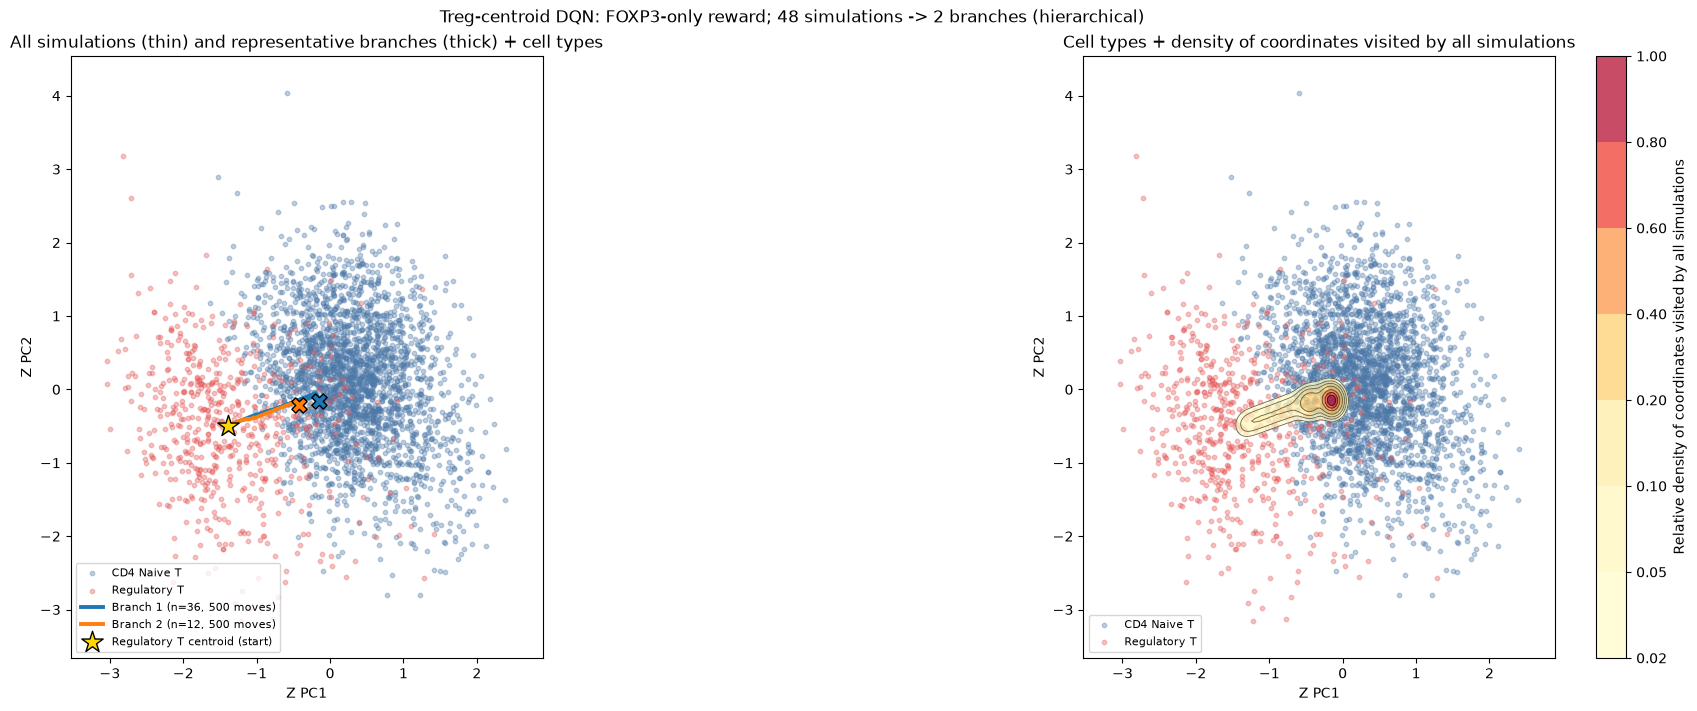

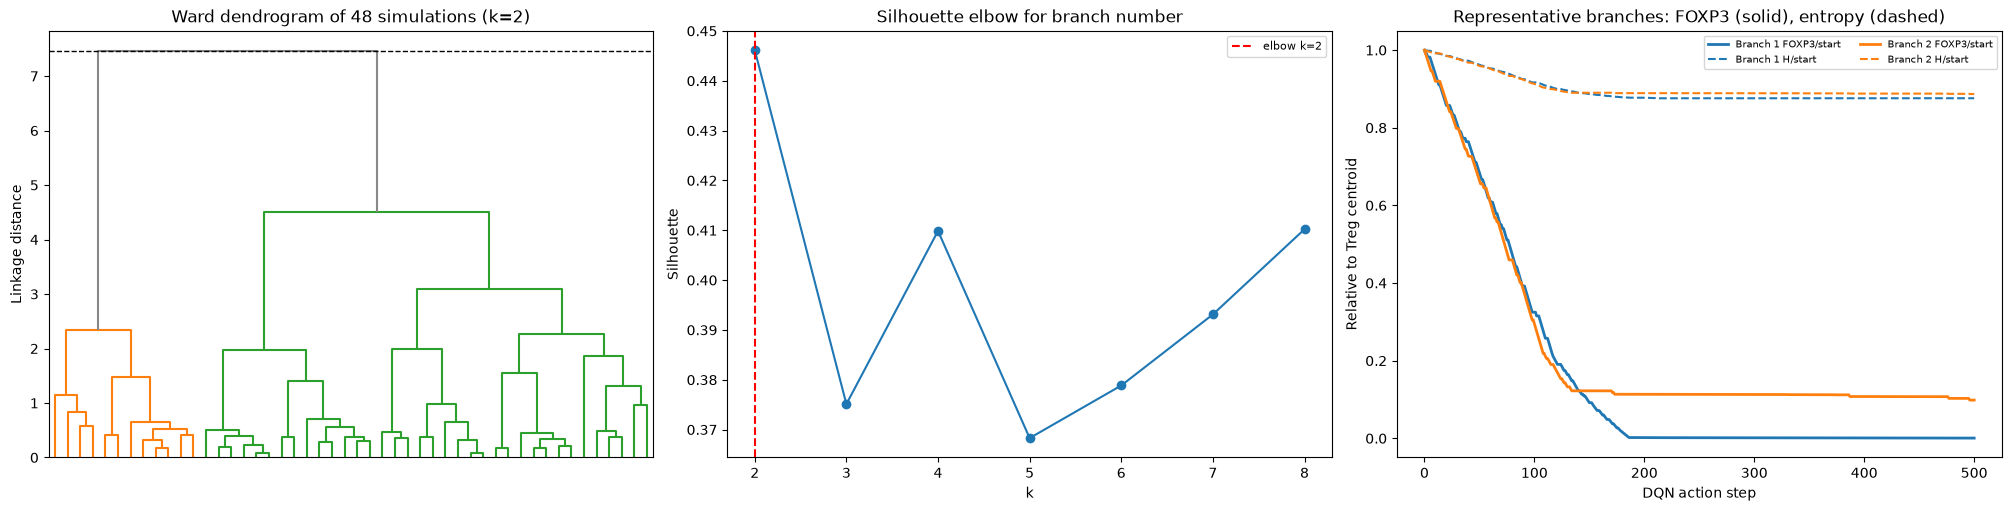

In [43]:
from pathlib import Path
from copy import deepcopy
import json
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from scipy.ndimage import gaussian_filter
from sklearn.metrics import silhouette_score
from IPython.display import display

LG_ROOT = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results')
LG_REWARD_VERSION = 'foxp3_decrease_only_small_steps_v1'
lg_completed_reward_version = None
LG_DIR = LG_ROOT / 'treg_foxp3_only_branch_dqn'
LG_DIR.mkdir(parents=True, exist_ok=True)
LG_SEED = 20261028
LG_STRIDES = (1,)                   # one fixed small latent step per action (move distance is capped)
LG_STEP_FRACTION = 0.01
LG_SUPPORT_QUANTILE = 0.95
LG_FOXP3_WEIGHT = 1.0
LG_MAX_MOVES = 500                  # maximum moves per simulation
LG_MOVE_PATIENCE, LG_MOVE_FRACTION = 10, 0.40
LG_N_MODELS, LG_SIMS_PER_MODEL, LG_EPS_RANGE = 4, 12, (0.05, 0.30)
LG_N_ENVS, LG_VECTOR_STEPS, LG_BATCH, LG_GAMMA, LG_LR = 256, 1500, 1024, 0.999, 3e-4
LG_TARGET_SYNC, LG_EVAL_EVERY = 500, 250
LG_K_MAX, LG_ELBOW_GAIN_FRACTION, LG_ELBOW_DROP = 8, 0.25, 0.1
LG_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

with np.load(LG_ROOT / 'coordinate_dqn/coordinate_graph.npz', allow_pickle=False) as saved:
    lg_z = saved['Z_space'].astype(np.float32)
    lg_barcodes = saved['cell_barcodes'].astype(str)
lg_h5ad = sc.read_h5ad('/home/Data_Drive_8TB/kykim/8. RL/tdata_sub.h5ad', backed='r')
try:
    lg_types = lg_h5ad.obs.loc[lg_barcodes, 'subtype'].astype(str).to_numpy()
finally:
    lg_h5ad.file.close()
if not (lg_types == 'Regulatory T').any():
    raise ValueError('No Regulatory T cells found for the centroid.')
lg_start_z = lg_z[lg_types == 'Regulatory T'].mean(axis=0).astype(np.float32)    # Regulatory T centroid (virtual latent)
lg_checkpoint = torch.load(LG_ROOT / 'coordinate_dqn/coordinate_models.pt', map_location='cpu', weights_only=False)
lg_pca_mean, lg_components = lg_checkpoint['pca_mean'], lg_checkpoint['pca_components']
lg_start_xy = (lg_start_z - lg_pca_mean) @ lg_components.T
lg_decoder = nn.Sequential(nn.Linear(16, 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 2000))
lg_decoder.load_state_dict({k.removeprefix('decoder.'): v
                            for k, v in lg_checkpoint['vae'].items() if k.startswith('decoder.')})
lg_decoder = lg_decoder.to(LG_DEVICE).eval().requires_grad_(False)
with np.load(LG_ROOT / 'ikzf2_latent_counterfactual/latent_counterfactual.npz', allow_pickle=False) as saved:
    lg_symbols = saved['gene_symbols'].astype(str)
lg_fox_matches = np.flatnonzero(lg_symbols == 'FOXP3')
if len(lg_fox_matches) != 1:
    raise ValueError('Expected one decoded FOXP3 output.')
LG_FOXP3_INDEX = int(lg_fox_matches[0])
lg_dim = lg_z.shape[1]
lg_cells_t = torch.tensor(lg_z, device=LG_DEVICE)
lg_start_t = torch.tensor(lg_start_z, device=LG_DEVICE)


@torch.no_grad()
def lg_measure(z: torch.Tensor):
    # Decoded Shannon entropy (same definition as Section 5), decoded FOXP3 and 5th-NN support distance.
    flat = z.reshape(-1, lg_dim)
    decoded = lg_decoder(flat)
    linear = torch.expm1(decoded.double().clamp_min(0))
    p = linear / linear.sum(dim=1, keepdim=True)
    entropy = -torch.xlogy(p, p).sum(dim=1).float()
    support = torch.cdist(flat, lg_cells_t).topk(5, largest=False).values[:, -1]
    shape = z.shape[:-1]
    return entropy.reshape(shape), decoded[:, LG_FOXP3_INDEX].reshape(shape), support.reshape(shape)


lg_cell_entropy, lg_cell_fox, _ = (v.cpu().numpy() for v in lg_measure(lg_cells_t))
with torch.no_grad():
    lg_cell_fifth = torch.cdist(lg_cells_t, lg_cells_t).topk(6, largest=False).values[:, -1]
lg_support_radius = float(torch.quantile(lg_cell_fifth, LG_SUPPORT_QUANTILE))
lg_h_mean, lg_h_scale = float(lg_cell_entropy.mean()), float(lg_cell_entropy.std(ddof=1))
lg_start_h, lg_start_fox, lg_start_support = (float(v[0]) for v in lg_measure(lg_start_t[None]))
lg_f_scale = lg_start_fox
if lg_f_scale <= 0:
    raise ValueError('Regulatory T centroid must have positive decoded FOXP3.')
lg_axis_step = torch.tensor(LG_STEP_FRACTION * lg_z.std(axis=0), device=LG_DEVICE)
lg_directions = torch.cat([torch.diag(lg_axis_step), -torch.diag(lg_axis_step)])        # (32, 16)
lg_direction_names = [f'{sign}Z{i + 1}' for sign in '+-' for i in range(lg_dim)]
lg_n_dir, lg_max_stride = len(lg_directions), max(LG_STRIDES)
LG_N_ACTIONS = lg_n_dir * len(LG_STRIDES)
lg_action_names = [f'{name} x{stride}' for stride in LG_STRIDES for name in lg_direction_names]
lg_substep_index = torch.arange(1, lg_max_stride + 1, device=LG_DEVICE, dtype=torch.float32)
lg_diversity_scale = float(np.quantile(np.linalg.norm(lg_z - lg_z.mean(axis=0), axis=1), .95))
lg_feature_mean = torch.tensor(lg_z.mean(axis=0), device=LG_DEVICE)
lg_feature_scale = torch.tensor(lg_z.std(axis=0), device=LG_DEVICE).clamp_min(1e-6)
lg_z_sd = lg_z.std(axis=0)
if not np.isfinite(lg_z_sd).all() or np.any(lg_z_sd <= 0):
    raise ValueError('Each latent axis must have positive finite observed SD.')
if not np.isfinite(lg_h_scale) or lg_h_scale <= 0:
    raise ValueError('Observed decoded entropy SD must be positive for state features.')


def lg_distance(fox, entropy):
    return LG_FOXP3_WEIGHT * fox / lg_f_scale


@torch.no_grad()
def lg_candidates(z: torch.Tensor, current_fox: torch.Tensor):
    """Each action lands after `stride` sub-steps; every sub-step must stay inside the observed-cell support."""
    sub = z[:, None, None] + lg_substep_index[None, None, :, None] * lg_directions[None, :, None]   # (B, 32, 4, 16)
    entropy, fox, support = lg_measure(sub)
    out = {'z': [], 'h': [], 'f': [], 's': [], 'valid': []}
    for stride in LG_STRIDES:
        out['z'].append(sub[:, :, stride - 1]); out['h'].append(entropy[:, :, stride - 1])
        out['f'].append(fox[:, :, stride - 1]); out['s'].append(support[:, :, stride - 1])
        next_fox = fox[:, :, stride - 1]
        tolerance = 8 * torch.finfo(next_fox.dtype).eps * current_fox.abs().clamp_min(1)
        decrease = (current_fox[:, None] - next_fox) > tolerance[:, None]
        out['valid'].append((support[:, :, :stride] <= lg_support_radius).all(dim=2)
                            & (next_fox >= 0) & torch.isfinite(next_fox) & decrease)
    return {key: torch.cat(value, dim=1) for key, value in out.items()}


@torch.no_grad()
def lg_features(z, f, h):
    return torch.cat([(z - lg_feature_mean) / lg_feature_scale, (z - lg_start_t) / lg_feature_scale,
                      (f / lg_f_scale)[:, None], ((h - lg_h_mean) / lg_h_scale)[:, None],
                      ((z - lg_start_t).norm(dim=1) / lg_diversity_scale)[:, None]], dim=1)


@torch.no_grad()
def lg_reward(f, h, f_next, h_next):
    return LG_FOXP3_WEIGHT * (f - f_next) / lg_f_scale


_probe = lg_candidates(lg_start_t[None], torch.tensor([lg_start_fox], device=LG_DEVICE))
if not bool(_probe['valid'].any()):
    raise ValueError('No supported FOXP3-decreasing action from the Regulatory T centroid.')
# Net latent displacement (observed-SD units) over the patience window; one action moves LG_STEP_FRACTION SD on one axis.
LG_MOVE_MIN = LG_MOVE_FRACTION * LG_MOVE_PATIENCE * LG_STEP_FRACTION * max(LG_STRIDES)
print(f'Start = Regulatory T centroid in Z (PCA=({lg_start_xy[0]:.3f}, {lg_start_xy[1]:.3f})); '
      f'FOXP3={lg_start_fox:.4f}, H={lg_start_h:.4f} nats; actions={LG_N_ACTIONS}; no endpoint.')
print(f'Each action moves {LG_STEP_FRACTION} SD. Max {LG_MAX_MOVES} moves; early stop when the net latent displacement over '
      f'{LG_MOVE_PATIENCE} steps <= {LG_MOVE_MIN:.3g} SD units ({LG_MOVE_FRACTION:.0%} of the maximum travel).')


class LgTracker:
    """Early stop when the net latent displacement over the last `patience` moves is small or zero."""

    def __init__(self, z0):
        self.size = LG_MOVE_PATIENCE + 1
        self.hist = z0[None].repeat(self.size, 1, 1)

    def update(self, idx, t, z):
        self.hist[t % self.size, idx] = z
        past = self.hist[(t - LG_MOVE_PATIENCE) % self.size, idx]
        net = ((z - past) / lg_feature_scale).norm(dim=1)
        return (t >= LG_MOVE_PATIENCE) & (net <= LG_MOVE_MIN)


class LongRangeLatentQ(nn.Module):
    def __init__(self, features, actions):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(features, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(),
                                     nn.Linear(256, actions))

    def forward(self, features):
        return self.network(features)


@torch.no_grad()
def lg_simulate(model, epsilons, seed):
    """Vectorised simulations from the Treg centroid; epsilon injects action diversity (0 = greedy)."""
    eps = torch.tensor(epsilons, dtype=torch.float32, device=LG_DEVICE)
    count = len(eps)
    generator = torch.Generator(device=LG_DEVICE).manual_seed(seed)
    z = lg_start_t[None].repeat(count, 1)
    f = torch.full((count,), lg_start_fox, device=LG_DEVICE)
    h = torch.full((count,), lg_start_h, device=LG_DEVICE)
    t = torch.zeros(count, dtype=torch.long, device=LG_DEVICE)
    tracker = LgTracker(z)
    shape = (LG_MAX_MOVES + 1, count)
    paths = np.full(shape + (lg_dim,), np.nan, np.float32); paths[0] = lg_start_z
    fox_hist, h_hist, sup_hist = (np.full(shape, np.nan, np.float32) for _ in range(3))
    fox_hist[0], h_hist[0], sup_hist[0] = lg_start_fox, lg_start_h, lg_start_support
    rewards = np.zeros((LG_MAX_MOVES, count), np.float32)
    actions = np.full((LG_MAX_MOVES, count), -1, np.int64)
    lengths = np.zeros(count, dtype=np.int64)
    status = ['maximum_moves'] * count
    active = torch.ones(count, dtype=torch.bool, device=LG_DEVICE)
    for _ in range(LG_MAX_MOVES):
        idx = active.nonzero().squeeze(1)
        if not len(idx):
            break
        c = lg_candidates(z[idx], f[idx])
        valid = c['valid']
        dead = ~valid.any(dim=1)
        q = model(lg_features(z[idx], f[idx], h[idx])).masked_fill(~valid, -torch.inf)
        safe = valid | dead[:, None]
        random_action = torch.multinomial(safe.float(), 1, generator=generator).squeeze(1)
        use_random = torch.rand(len(idx), device=LG_DEVICE, generator=generator) < eps[idx]
        action = torch.where(use_random, random_action, q.argmax(dim=1))
        for row in dead.nonzero().squeeze(1).tolist():
            status[int(idx[row])] = 'no_foxp3_decreasing_action'
        active[idx[dead]] = False
        keep = ~dead
        if not keep.any():
            continue
        idx, action = idx[keep], action[keep]
        rows = torch.arange(len(idx), device=LG_DEVICE)
        zn, fn, hn, sn = (c[key][keep][rows, action] for key in ('z', 'f', 'h', 's'))
        reward = lg_reward(f[idx], h[idx], fn, hn)
        z[idx], f[idx], h[idx] = zn, fn, hn
        t[idx] += 1
        converged = tracker.update(idx, t[idx], zn)
        step_numbers, index_np = t[idx].cpu().numpy(), idx.cpu().numpy()
        paths[step_numbers, index_np] = zn.cpu().numpy()
        fox_hist[step_numbers, index_np], h_hist[step_numbers, index_np] = fn.cpu().numpy(), hn.cpu().numpy()
        sup_hist[step_numbers, index_np] = sn.cpu().numpy()
        rewards[step_numbers - 1, index_np] = reward.cpu().numpy()
        actions[step_numbers - 1, index_np] = action.cpu().numpy()
        lengths[index_np] = step_numbers
        finished = converged | (t[idx] >= LG_MAX_MOVES)
        for row in finished.nonzero().squeeze(1).tolist():
            status[int(idx[row])] = 'early_stop_low_movement' if bool(converged[row]) else 'maximum_moves'
        active[idx[finished]] = False
    results = []
    for b in range(count):
        n = int(lengths[b])
        results.append({'path': paths[:n + 1, b], 'fox': fox_hist[:n + 1, b], 'entropy': h_hist[:n + 1, b],
                        'support': sup_hist[:n + 1, b], 'actions': actions[:n, b], 'rewards': rewards[:n, b],
                        'status': status[b], 'epsilon': float(eps[b]),
                        'score': float(np.sum(rewards[:n, b] * LG_GAMMA ** np.arange(n)))})
    return results


@torch.no_grad()
def lg_reset(count, generator):
    # Half the environments start at the Treg centroid; half at supported measured cells with FOXP3 >= 0 (exploration).
    eligible = torch.tensor(np.flatnonzero(lg_cell_fox >= 0), device=LG_DEVICE)
    z = lg_cells_t[eligible[torch.randint(len(eligible), (count,), device=LG_DEVICE, generator=generator)]].clone()
    z[torch.rand(count, device=LG_DEVICE, generator=generator) < 0.5] = lg_start_t
    h, f, _ = lg_measure(z)
    return z, f, h


def lg_train(model_index):
    seed = LG_SEED + model_index
    torch.manual_seed(seed)
    generator = torch.Generator(device=LG_DEVICE).manual_seed(seed)
    n_features = 2 * lg_dim + 3
    model = LongRangeLatentQ(n_features, LG_N_ACTIONS).to(LG_DEVICE)
    target = deepcopy(model).eval()
    optimizer = torch.optim.Adam(model.parameters(), lr=LG_LR)
    capacity = LG_N_ENVS * LG_VECTOR_STEPS
    buffer = {'f': torch.empty(capacity, n_features, device=LG_DEVICE), 'n': torch.empty(capacity, n_features, device=LG_DEVICE),
              'm': torch.empty(capacity, LG_N_ACTIONS, dtype=torch.bool, device=LG_DEVICE),
              'a': torch.empty(capacity, dtype=torch.long, device=LG_DEVICE),
              'r': torch.empty(capacity, device=LG_DEVICE), 'd': torch.empty(capacity, dtype=torch.bool, device=LG_DEVICE)}
    z, f, h = lg_reset(LG_N_ENVS, generator)
    t = torch.zeros(LG_N_ENVS, dtype=torch.long, device=LG_DEVICE)
    all_envs = torch.arange(LG_N_ENVS, device=LG_DEVICE)
    candidates = lg_candidates(z, f)
    count, updates, log = 0, 0, []
    best_score, best_weights, started = -np.inf, None, time.time()
    for vector_step in range(1, LG_VECTOR_STEPS + 1):
        dead = ~candidates['valid'].any(dim=1)
        reset_attempts = 0
        while dead.any():
            reset_attempts += 1
            if reset_attempts > 64:
                raise RuntimeError('Could not reset training environments to FOXP3-decreasing supported states.')
            z[dead], f[dead], h[dead] = lg_reset(int(dead.sum()), generator)
            t[dead] = 0
            candidates = lg_candidates(z, f)
            dead = ~candidates['valid'].any(dim=1)
        features, valid = lg_features(z, f, h), candidates['valid']
        epsilon = max(0.05, 1.0 - vector_step / (0.6 * LG_VECTOR_STEPS))
        greedy = model(features).masked_fill(~valid, -torch.inf).argmax(dim=1)
        random_actions = torch.multinomial(valid.float(), 1, generator=generator).squeeze(1)
        actions = torch.where(torch.rand(LG_N_ENVS, device=LG_DEVICE, generator=generator) < epsilon, random_actions, greedy)
        zn, fn, hn = (candidates[key][all_envs, actions] for key in ('z', 'f', 'h'))
        reward = lg_reward(f, h, fn, hn)
        z, f, h, t = zn.clone(), fn.clone(), hn.clone(), t + 1
        next_candidates = lg_candidates(z, f)
        next_valid = next_candidates['valid']
        terminal = ~next_valid.any(dim=1) | (t >= LG_MAX_MOVES)
        slots = torch.arange(count, count + LG_N_ENVS, device=LG_DEVICE)
        buffer['f'][slots], buffer['n'][slots], buffer['m'][slots] = features, lg_features(z, f, h), next_valid
        buffer['a'][slots], buffer['r'][slots], buffer['d'][slots] = actions, reward, terminal
        count += LG_N_ENVS
        reset = terminal
        if reset.any():
            z[reset], f[reset], h[reset] = lg_reset(int(reset.sum()), generator)
            t[reset] = 0
            next_candidates = lg_candidates(z, f)
        candidates = next_candidates
        if count >= 4 * LG_BATCH:
            for _ in range(2):
                batch = torch.randint(count, (LG_BATCH,), device=LG_DEVICE, generator=generator)
                prediction = model(buffer['f'][batch]).gather(1, buffer['a'][batch, None]).squeeze(1)
                with torch.no_grad():
                    next_mask = buffer['m'][batch]
                    next_action = model(buffer['n'][batch]).masked_fill(~next_mask, -torch.inf).argmax(dim=1)
                    next_q = target(buffer['n'][batch]).gather(1, next_action[:, None]).squeeze(1)
                    next_q = torch.where(next_mask.any(dim=1), next_q, torch.zeros_like(next_q))
                    expected = buffer['r'][batch] + LG_GAMMA * next_q * (~buffer['d'][batch]).float()
                loss = nn.functional.smooth_l1_loss(prediction, expected)
                if not torch.isfinite(loss):
                    raise FloatingPointError('Non-finite DQN loss.')
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                optimizer.step()
                updates += 1
                if updates % LG_TARGET_SYNC == 0:
                    target.load_state_dict(model.state_dict())
        if vector_step % LG_EVAL_EVERY == 0 and updates:
            model.eval()
            result = lg_simulate(model, [0.0], seed)[0]
            model.train()
            log.append({'model': model_index, 'vector_step': vector_step, 'updates': updates, 'epsilon': epsilon,
                        'greedy_return': result['score'], 'moves': len(result['actions']), 'status': result['status'],
                        'FOXP3_end': float(result['fox'][-1]), 'entropy_end': float(result['entropy'][-1])})
            if result['score'] > best_score:
                best_score, best_weights = result['score'], deepcopy(model.state_dict())
            print(f'Model {model_index} step {vector_step}: return={result["score"]:.3f}, moves={len(result["actions"])}, '
                  f'{result["status"]}, FOXP3 {lg_start_fox:.3f}->{result["fox"][-1]:.3f}, '
                  f'H {lg_start_h:.3f}->{result["entropy"][-1]:.3f} ({time.time() - started:.0f}s)', flush=True)
    if best_weights is None:
        raise RuntimeError(f'Model {model_index}: no evaluation checkpoint was produced.')
    model.load_state_dict(best_weights)
    return model.eval(), pd.DataFrame(log)


lg_models, lg_logs = [], []
for model_index in range(1, LG_N_MODELS + 1):
    model, log = lg_train(model_index)
    lg_models.append(model); lg_logs.append(log)

# Many simulations: one greedy rollout + epsilon-diversified rollouts per independently trained DQN.
lg_sims, lg_sim_model = [], []
for model_index, model in enumerate(lg_models, start=1):
    epsilons = [0.0] + list(np.linspace(*LG_EPS_RANGE, LG_SIMS_PER_MODEL - 1))
    for result in lg_simulate(model, epsilons, LG_SEED + 100 * model_index):
        lg_sims.append(result); lg_sim_model.append(model_index)
lg_n_sims = len(lg_sims)
for result in lg_sims:
    assert len(result['actions']) >= 1 and np.allclose(result['path'][0], lg_start_z)
    assert len(result['actions']) <= LG_MAX_MOVES
    assert np.all(result['support'][1:] <= lg_support_radius + 1e-6) and np.all(result['fox'][1:] >= -1e-6)
    tolerance = 8 * np.finfo(result['fox'].dtype).eps * np.maximum(np.abs(result['fox'][:-1]), 1)
    assert np.all(result['fox'][:-1] - result['fox'][1:] > tolerance)
    np.testing.assert_allclose(result['rewards'], LG_FOXP3_WEIGHT * -np.diff(result['fox']) / lg_f_scale, rtol=1e-5)


def lg_signature(result, phases=3):
    # Net signed latent displacement per axis (in observed SD) for early / middle / late thirds of the simulation.
    path = result['path']
    edges = np.linspace(0, len(path) - 1, phases + 1).round().astype(int)
    return np.concatenate([(path[edges[i + 1]] - path[edges[i]]) / lg_z_sd for i in range(phases)])


lg_signatures = np.stack([lg_signature(result) for result in lg_sims])
lg_linkage = linkage(lg_signatures, method='ward')
lg_k_scores = {}
for k in range(2, min(LG_K_MAX, lg_n_sims - 1) + 1):
    labels_k = fcluster(lg_linkage, k, criterion='maxclust')
    if len(np.unique(labels_k)) == k:
        lg_k_scores[k] = float(silhouette_score(lg_signatures, labels_k))
# Silhouette-based elbow: keep the largest k reached before the silhouette collapses (largest drop); if it never drops,
# fall back to the first k whose next silhouette gain is below a fraction of the largest gain.
lg_k_values = sorted(lg_k_scores)
lg_k_gains = {k: lg_k_scores[k] - lg_k_scores[k - 1] for k in lg_k_values[1:]}
lg_gain_threshold = LG_ELBOW_GAIN_FRACTION * max(max(lg_k_gains.values()), 0.0) if lg_k_gains else 0.0
if lg_k_gains and min(lg_k_gains.values()) < -LG_ELBOW_DROP:
    lg_best_k = min(lg_k_gains, key=lg_k_gains.get) - 1
else:
    lg_best_k = next((k for k in lg_k_values if k + 1 in lg_k_gains and lg_k_gains[k + 1] < lg_gain_threshold), lg_k_values[-1] if lg_k_values else 1)
lg_labels = fcluster(lg_linkage, lg_best_k, criterion='maxclust') if lg_best_k > 1 else np.ones(lg_n_sims, dtype=int)
lg_distance_matrix = squareform(pdist(lg_signatures))
lg_cluster_ids = np.unique(lg_labels)
lg_medoids = {}
for cluster in lg_cluster_ids:
    members = np.flatnonzero(lg_labels == cluster)
    lg_medoids[cluster] = int(members[lg_distance_matrix[np.ix_(members, members)].sum(axis=1).argmin()])
lg_cluster_ids = sorted(lg_cluster_ids, key=lambda c: -(lg_labels == c).sum())      # branch 1 = largest cluster
lg_branch_of_cluster = {c: i + 1 for i, c in enumerate(lg_cluster_ids)}
lg_branch_labels = np.array([lg_branch_of_cluster[c] for c in lg_labels])
print(f'{lg_n_sims} simulations -> {lg_best_k} representative branches (Ward hierarchical clustering, silhouette elbow; silhouette by k: { {k: round(v, 3) for k, v in lg_k_scores.items()} }).')

lg_sim_table = pd.DataFrame({
    'simulation': np.arange(lg_n_sims), 'model': lg_sim_model, 'epsilon': [r['epsilon'] for r in lg_sims],
    'branch': lg_branch_labels, 'moves': [len(r['actions']) for r in lg_sims], 'status': [r['status'] for r in lg_sims],
    'FOXP3_end': [float(r['fox'][-1]) for r in lg_sims], 'entropy_end': [float(r['entropy'][-1]) for r in lg_sims],
    'discounted_return': [r['score'] for r in lg_sims],
    'is_representative': [i == lg_medoids[c] for i, c in enumerate(lg_labels)]})
lg_sim_table.to_csv(LG_DIR / 'simulation_summary.csv', index=False)


def lg_top_axes(members, count=3):
    mean_signature = lg_signatures[members].reshape(len(members), 3, lg_dim).sum(axis=1).mean(axis=0)
    order = np.argsort(-np.abs(mean_signature))[:count]
    return ', '.join(f'{"+" if mean_signature[i] > 0 else "-"}Z{i + 1}' for i in order)


lg_branch_rows, lg_representatives = [], []
for cluster in lg_cluster_ids:
    branch = lg_branch_of_cluster[cluster]
    members = np.flatnonzero(lg_labels == cluster)
    medoid = lg_medoids[cluster]
    result = lg_sims[medoid]
    lg_representatives.append((branch, medoid, result))
    path, actions = result['path'], result['actions']
    xy = (path - lg_pca_mean) @ lg_components.T
    frame = pd.DataFrame({'step': np.arange(len(path)), 'decoded_FOXP3': result['fox'], 'decoded_entropy_nats': result['entropy'],
                          'PC1': xy[:, 0], 'PC2': xy[:, 1], 'support_distance_k5': result['support'],
                          'chosen_action': [lg_action_names[a] for a in actions] + [''],
                          'reward_to_next': np.r_[result['rewards'], np.nan]})
    frame = pd.concat([frame, pd.DataFrame(path, columns=[f'Z{i + 1}' for i in range(lg_dim)])], axis=1)
    frame.to_csv(LG_DIR / f'branch{branch}_trajectory.csv', index=False)
    lg_branch_rows.append({
        'branch': branch, 'n_simulations': len(members), 'fraction': len(members) / lg_n_sims,
        'representative_simulation': medoid, 'representative_model': lg_sim_model[medoid],
        'representative_moves': len(actions), 'representative_status': result['status'],
        'dominant_latent_axes': lg_top_axes(members),
        'FOXP3_start': lg_start_fox, 'FOXP3_end_rep': float(result['fox'][-1]),
        'FOXP3_end_cluster_mean': float(lg_sim_table.loc[members, 'FOXP3_end'].mean()),
        'entropy_start': lg_start_h, 'entropy_end_rep': float(result['entropy'][-1]),
        'entropy_end_cluster_mean': float(lg_sim_table.loc[members, 'entropy_end'].mean()),
        'PCA_endpoint_displacement': float(np.linalg.norm(xy[-1] - lg_start_xy)),
        'mean_moves': float(lg_sim_table.loc[members, 'moves'].mean())})
lg_branch_df = pd.DataFrame(lg_branch_rows)
lg_branch_df.to_csv(LG_DIR / 'branch_summary.csv', index=False)
pd.concat(lg_logs, ignore_index=True).to_csv(LG_DIR / 'training_history.csv', index=False)
torch.save({'reward_version': LG_REWARD_VERSION, 'models': [m.state_dict() for m in lg_models], 'directions': lg_directions.cpu(),
            'strides': LG_STRIDES, 'action_names': lg_action_names}, LG_DIR / 'branch_models.pt')
lg_lengths = np.array([len(r['actions']) for r in lg_sims])
lg_padded = np.full((lg_n_sims, lg_lengths.max() + 1, lg_dim), np.nan, np.float32)
for i, result in enumerate(lg_sims):
    lg_padded[i, :len(result['path'])] = result['path']
np.savez_compressed(LG_DIR / 'simulation_paths.npz', paths=lg_padded, lengths=lg_lengths, branch=lg_branch_labels,
                    signatures=lg_signatures, linkage=lg_linkage, start_z=lg_start_z,
                    representative_index=np.array([m for _, m, _ in lg_representatives]),
                    representative_branch=np.array([b for b, _, _ in lg_representatives]))
(LG_DIR / 'run_metadata.json').write_text(json.dumps({
    'reward_version': LG_REWARD_VERSION,
    'state_space': 'continuous virtual latent coordinates generated by actions (no coordinate graph, not cells)',
    'start': 'Regulatory T centroid = mean Z of Regulatory T cells', 'start_pca': lg_start_xy.tolist(), 'endpoint': None,
    'actions': f'+/- each of {lg_dim} latent axes x strides {list(LG_STRIDES)} = {LG_N_ACTIONS}',
    'base_substep': f'{LG_STEP_FRACTION} x observed SD per latent axis',
    'support_constraint': f'every sub-step 5th-NN distance <= {lg_support_radius:.6g} (q{LG_SUPPORT_QUANTILE}); next decoded FOXP3 >= 0; decrease > 8*dtype_epsilon*max(abs(current_FOXP3),1)',
    'reward': 'FOXP3_weight*(FOXP3_t - FOXP3_t+1)/FOXP3_start',
    'weights': {'foxp3': LG_FOXP3_WEIGHT, 'entropy': 0.0}, 'H_scale': lg_h_scale, 'FOXP3_scale': lg_f_scale,
    'entropy_role': 'observational state feature, CSV and visualization only; not reward',
    'training_terminal': '500-move horizon or no supported FOXP3-decreasing action; no stagnation stop',
    'entropy': 'Shannon H of decoded expression p=expm1(max(decoder(z),0))/sum (nats)',
    'stop_rule': {'max_moves': LG_MAX_MOVES, 'patience': LG_MOVE_PATIENCE, 'min_net_displacement_sd_units': LG_MOVE_MIN,
                  'rule': '||(z_t - z_(t-patience)) / SD|| <= min_net_displacement for t >= patience (little or no movement)'},
    'simulations': {'models': LG_N_MODELS, 'per_model': LG_SIMS_PER_MODEL, 'epsilon_range': list(LG_EPS_RANGE), 'total': lg_n_sims},
    'clustering': {'method': 'Ward hierarchical on 3-phase net latent displacement (observed-SD units)',
                   'k_selection': f'silhouette elbow: largest k before the silhouette drops by > {LG_ELBOW_DROP} (else first k with next gain < {LG_ELBOW_GAIN_FRACTION} x largest gain)', 'silhouette_by_k': lg_k_scores,
                   'elbow_gain_threshold': lg_gain_threshold, 'k': int(lg_best_k)},
    'branches': lg_branch_rows, 'interpretation': 'Fixed-VAE model trajectories, not causal KO or validated differentiation.'},
    indent=2))
display(lg_branch_df)

lg_observed_xy = (lg_z - lg_pca_mean) @ lg_components.T
lg_colors = plt.get_cmap('tab10')(np.arange(len(lg_cluster_ids)))
fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
for ax in axes:
    for subtype, color in [('CD4 Naive T', '#4C78A8'), ('Regulatory T', '#E45756')]:
        selected = lg_types == subtype
        ax.scatter(*lg_observed_xy[selected].T, s=10, alpha=.35, c=color, label=subtype, zorder=1)
lg_path_xy = np.concatenate([(r['path'][1:] - lg_pca_mean) @ lg_components.T for r in lg_sims])
lg_pad = 0.5
lg_plot_xy = np.vstack([lg_observed_xy, lg_path_xy, lg_start_xy[None]])
lg_x_edges = np.linspace(lg_plot_xy[:, 0].min() - lg_pad, lg_plot_xy[:, 0].max() + lg_pad, 241)
lg_y_edges = np.linspace(lg_plot_xy[:, 1].min() - lg_pad, lg_plot_xy[:, 1].max() + lg_pad, 241)
lg_hist, _, _ = np.histogram2d(lg_path_xy[:, 0], lg_path_xy[:, 1], bins=[lg_x_edges, lg_y_edges])
lg_density = gaussian_filter(lg_hist.T, sigma=3)
if lg_density.max() <= 0:
    raise RuntimeError('No post-start visits available for density estimation.')
lg_density = lg_density / lg_density.max()
lg_gx, lg_gy = np.meshgrid(0.5 * (lg_x_edges[1:] + lg_x_edges[:-1]), 0.5 * (lg_y_edges[1:] + lg_y_edges[:-1]))
lg_levels = np.array([.02, .05, .1, .2, .4, .6, .8, 1.0])
density_fill = axes[1].contourf(lg_gx, lg_gy, lg_density, levels=lg_levels, cmap='YlOrRd', alpha=.7, zorder=2)
axes[1].contour(lg_gx, lg_gy, lg_density, levels=lg_levels[:-1], colors='k', linewidths=.6, alpha=.6, zorder=3)
fig.colorbar(density_fill, ax=axes[1], label='Relative density of coordinates visited by all simulations')
for i, result in enumerate(lg_sims):
    xy = (result['path'] - lg_pca_mean) @ lg_components.T
    axes[0].plot(*xy.T, c=lg_colors[lg_branch_labels[i] - 1], lw=.6, alpha=.35, zorder=4)
for branch, medoid, result in lg_representatives:
    xy = (result['path'] - lg_pca_mean) @ lg_components.T
    color = lg_colors[branch - 1]
    axes[0].plot(*xy.T, c=color, lw=2.8, zorder=6,
                 label=f'Branch {branch} (n={int((lg_branch_labels == branch).sum())}, {len(xy) - 1} moves)')
    axes[0].scatter(*xy[-1], s=120, marker='X', c=[color], edgecolor='black', zorder=7)
axes[0].scatter(*lg_start_xy, marker='*', s=260, c='#FFD700', edgecolor='black', label='Regulatory T centroid (start)', zorder=8)
for ax in axes:
    ax.set(xlabel='Z PC1', ylabel='Z PC2')
    ax.legend(fontsize=8, loc='lower left')
for ax in axes:
    ax.set_xlim(lg_x_edges[0], lg_x_edges[-1]); ax.set_ylim(lg_y_edges[0], lg_y_edges[-1])
    ax.set_aspect('equal', adjustable='box')
axes[0].set_title('All simulations (thin) and representative branches (thick) + cell types')
axes[1].set_title('Cell types + density of coordinates visited by all simulations')
fig.suptitle(f'Treg-centroid DQN: FOXP3-only reward; {lg_n_sims} simulations -> {lg_best_k} branches (hierarchical)')
fig.savefig(LG_DIR / 'treg_foxp3_only_branches_pca.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)
cut = None if lg_best_k == 1 else float(lg_linkage[-(lg_best_k - 1), 2]) - 1e-9
dendrogram(lg_linkage, ax=axes[0], no_labels=True, color_threshold=cut, above_threshold_color='#888888')
if cut is not None:
    axes[0].axhline(cut, c='k', ls='--', lw=1)
axes[0].set(title=f'Ward dendrogram of {lg_n_sims} simulations (k={lg_best_k})', ylabel='Linkage distance')
if lg_k_scores:
    axes[1].plot(list(lg_k_scores), list(lg_k_scores.values()), 'o-')
    axes[1].axvline(lg_best_k, c='r', ls='--', label=f'elbow k={lg_best_k}')
    axes[1].legend(fontsize=8)
axes[1].set(xlabel='k', ylabel='Silhouette', title='Silhouette elbow for branch number')
for branch, medoid, result in lg_representatives:
    steps = np.arange(len(result['fox']))
    axes[2].plot(steps, result['fox'] / lg_start_fox, c=lg_colors[branch - 1], lw=2, label=f'Branch {branch} FOXP3/start')
    axes[2].plot(steps, result['entropy'] / lg_start_h, c=lg_colors[branch - 1], lw=1.5, ls='--', label=f'Branch {branch} H/start')
axes[2].set(xlabel='DQN action step', ylabel='Relative to Treg centroid', title='Representative branches: FOXP3 (solid), entropy (dashed)')
axes[2].legend(fontsize=7, ncol=2)
fig.savefig(LG_DIR / 'treg_foxp3_only_branch_clustering.png', dpi=180, bbox_inches='tight')
plt.show()
np.savez_compressed(LG_DIR / 'visit_density.npz', density=lg_density, x_edges=lg_x_edges, y_edges=lg_y_edges)
lg_completed_reward_version = LG_REWARD_VERSION

## 14-1. Treg-start FOXP3-only DQN 영상

새 14절 결과를 기존 PCA 위에 표시합니다. H·ΔH는 관찰값이고 보상은 FOXP3 감소만 포함합니다. 저장된 감소·보상식을 검증하며 이전 entropy 보상 모델/결과는 거부합니다. 14절 재학습·저장 후 실행하세요.
오른쪽 세 패널은 `## 7` 영상처럼 Decoded Shannon entropy, Delta H(`H[t]-H[t-1]`), Reward per move를 branch마다 다른 색으로 표시합니다. 시작점에는 Delta H/Reward 값이 없고 도착 move부터 표시되며, 마지막 move는 항상 포함됩니다.

In [44]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import torch
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.markers import MarkerStyle
from IPython.display import Video, display
import imageio_ffmpeg

LG_VIDEO_ROOT = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results')
LG_VIDEO_DIR = LG_VIDEO_ROOT / 'treg_foxp3_only_branch_dqn'
LG_VIDEO_PATH = LG_VIDEO_DIR / 'treg_foxp3_only_branches.mp4'
LG_VIDEO_FPS, LG_VIDEO_MOVES_PER_FRAME = 30, 4
lgv_ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
lgv_metadata = json.loads((LG_VIDEO_DIR / 'run_metadata.json').read_text())
if lgv_metadata.get('reward_version') != 'foxp3_decrease_only_small_steps_v1':
    raise RuntimeError('Retrain and export section 14 with the FOXP3-only reward first.')
with np.load(LG_VIDEO_DIR / 'visit_density.npz', allow_pickle=False) as saved:
    lgv_x_edges, lgv_y_edges = saved['x_edges'], saved['y_edges']
with np.load(LG_VIDEO_ROOT / 'coordinate_dqn/coordinate_graph.npz', allow_pickle=False) as saved:
    lgv_z = saved['Z_space'].astype(np.float32)
    lgv_barcodes = saved['cell_barcodes'].astype(str)
lgv_checkpoint = torch.load(LG_VIDEO_ROOT / 'coordinate_dqn/coordinate_models.pt', map_location='cpu', weights_only=False)
lgv_pca_mean, lgv_components = lgv_checkpoint['pca_mean'], lgv_checkpoint['pca_components']
del lgv_checkpoint
lgv_observed_xy = (lgv_z - lgv_pca_mean) @ lgv_components.T
lgv_data = sc.read_h5ad('/home/Data_Drive_8TB/kykim/8. RL/tdata_sub.h5ad', backed='r')
try:
    lgv_types = lgv_data.obs.loc[lgv_barcodes, 'subtype'].astype(str).to_numpy()
finally:
    lgv_data.file.close()

lgv_latent_columns = [f'Z{i + 1}' for i in range(lgv_z.shape[1])]
with np.load(LG_VIDEO_DIR / 'simulation_paths.npz', allow_pickle=False) as saved:
    lgv_all_paths, lgv_lengths, lgv_sim_branch = saved['paths'], saved['lengths'], saved['branch']
    lgv_start_z = saved['start_z']
lgv_summary = pd.read_csv(LG_VIDEO_DIR / 'branch_summary.csv')
lgv_colors = plt.get_cmap('tab10')(np.arange(len(lgv_summary)))
lgv_branches = []
for row in lgv_summary.itertuples():
    table = pd.read_csv(LG_VIDEO_DIR / f'branch{row.branch}_trajectory.csv')
    path = table[lgv_latent_columns].to_numpy()
    np.testing.assert_allclose(path[0], lgv_start_z, atol=1e-5)
    np.testing.assert_allclose(table[['PC1', 'PC2']].to_numpy(), (path - lgv_pca_mean) @ lgv_components.T, atol=1e-4)
    if not np.isfinite(table[['decoded_FOXP3', 'decoded_entropy_nats']]).all().all():
        raise ValueError('Non-finite trajectory measurements.')
    entropy = table.decoded_entropy_nats.to_numpy()
    delta_h = np.diff(entropy)                                  # dH[t] = H[t] - H[t-1], aligned to arrival move t = 1..n
    reward = table.reward_to_next.to_numpy()[:-1]               # stored reward of move t (same alignment)
    if len(delta_h) != len(reward) or not np.isfinite(reward).all():
        raise ValueError('Reward / delta-H alignment is inconsistent.')
    fox = table.decoded_FOXP3.to_numpy()
    tolerance = 8 * np.finfo(np.float32).eps * np.maximum(np.abs(fox[:-1]), 1)
    if not np.all(fox[:-1] - fox[1:] > tolerance):
        raise ValueError('Saved branch contains a non-decreasing FOXP3 move.')
    np.testing.assert_allclose(reward, -np.diff(fox) / lgv_metadata['FOXP3_scale'], rtol=1e-4, atol=1e-7)
    lgv_branches.append({'table': table, 'xy': table[['PC1', 'PC2']].to_numpy(), 'summary': row, 'color': lgv_colors[row.branch - 1],
                         'entropy': entropy, 'delta_h': delta_h, 'reward': reward})
lgv_start_xy = lgv_branches[0]['xy'][0]
lgv_max_moves = max(len(b['table']) - 1 for b in lgv_branches)
lgv_schedule = np.r_[np.zeros(LG_VIDEO_FPS, dtype=int),
                     np.minimum(np.arange(LG_VIDEO_MOVES_PER_FRAME, lgv_max_moves + LG_VIDEO_MOVES_PER_FRAME, LG_VIDEO_MOVES_PER_FRAME), lgv_max_moves),
                     np.full(2 * LG_VIDEO_FPS, lgv_max_moves, dtype=int)]

lgv_fig = plt.figure(figsize=(15, 9), constrained_layout=True)
lgv_grid = lgv_fig.add_gridspec(3, 2, width_ratios=[1.7, 1])
lgv_ax = lgv_fig.add_subplot(lgv_grid[:, 0])
lgv_entropy_ax = lgv_fig.add_subplot(lgv_grid[0, 1])
lgv_delta_ax = lgv_fig.add_subplot(lgv_grid[1, 1], sharex=lgv_entropy_ax)
lgv_reward_ax = lgv_fig.add_subplot(lgv_grid[2, 1], sharex=lgv_entropy_ax)
for subtype, color in [('CD4 Naive T', '#4C78A8'), ('Regulatory T', '#E45756')]:
    mask = lgv_types == subtype
    lgv_ax.scatter(*lgv_observed_xy[mask].T, s=10, alpha=0.35, c=color, label=subtype, zorder=1)
for i in range(len(lgv_all_paths)):
    xy = (lgv_all_paths[i, :lgv_lengths[i] + 1] - lgv_pca_mean) @ lgv_components.T
    lgv_ax.plot(*xy.T, c=lgv_colors[lgv_sim_branch[i] - 1], lw=0.6, alpha=0.35, zorder=4)
lgv_ax.scatter(*lgv_start_xy, s=260, marker='*', c='#FFD700', edgecolors='black', label='Regulatory T centroid (start)', zorder=8)
for data in lgv_branches:
    branch = data['summary'].branch
    label = f'Branch {branch} (n={data["summary"].n_simulations})'
    data['trail'], = lgv_ax.plot([], [], color=data['color'], lw=2.8, zorder=6, label=label)
    data['current'] = lgv_ax.scatter([], [], s=120, c=[data['color']], edgecolors='black', zorder=7)
    data['entropy_line'], = lgv_entropy_ax.plot([], [], color=data['color'], lw=1.8, label=f'Branch {branch}')
    data['delta_line'], = lgv_delta_ax.plot([], [], color=data['color'], lw=1.0)
    data['reward_line'], = lgv_reward_ax.plot([], [], color=data['color'], lw=1.0)
    data['text'] = lgv_ax.text(0.02, 0.98 - 0.045 * (branch - 1), '', transform=lgv_ax.transAxes, va='top',
                               color=data['color'], fontsize=9, fontweight='bold',
                               bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none', 'pad': 1.5}, zorder=9)
lgv_ax.set(xlabel='Z PC1', ylabel='Z PC2', title='All simulations (thin) and representative branches (thick) + cell types')
lgv_ax.legend(loc='lower left', fontsize=8)
lgv_panels = [(lgv_entropy_ax, 'entropy', 'Decoded Shannon entropy (nats)', 0),
              (lgv_delta_ax, 'delta_h', 'Delta H = H[t] - H[t-1] (nats/move)', 1),
              (lgv_reward_ax, 'reward', 'Reward per move (FOXP3 only)', 1)]
for ax, key, label, first_move in lgv_panels:
    values = np.concatenate([b[key] for b in lgv_branches])
    margin = max(float(np.ptp(values)) * 0.1, 1e-6)
    ax.set(xlim=(-0.5, lgv_max_moves + 0.5), ylim=(float(values.min()) - margin, float(values.max()) + margin), ylabel=label)
    ax.grid(alpha=0.2)
    if key != 'entropy':
        ax.axhline(0, c='#555555', lw=0.8, ls='--')
lgv_entropy_ax.legend(fontsize=8, ncol=2)
lgv_reward_ax.set_xlabel('Arrival move')
lgv_ax.set_aspect('equal', adjustable='box')
lgv_ax.set_xlim(lgv_x_edges[0], lgv_x_edges[-1]); lgv_ax.set_ylim(lgv_y_edges[0], lgv_y_edges[-1])
lgv_fig.suptitle('Treg-centroid DQN: representative branches | FOXP3-only reward\n'
                 'Fixed-VAE model trajectory; DQN step is not biological time', fontsize=13)


def update_branch_video(step):
    for data in lgv_branches:
        n_moves = len(data['table']) - 1
        current = min(int(step), n_moves)
        xy = data['xy'][:current + 1]
        data['trail'].set_data(xy[:, 0], xy[:, 1])
        data['current'].set_offsets(xy[-1:])
        stopped = current == n_moves
        marker = MarkerStyle('X' if stopped else 'o')
        data['current'].set_paths([marker.get_path().transformed(marker.get_transform())])
        moves = np.arange(1, current + 1)
        data['entropy_line'].set_data(np.arange(current + 1), data['entropy'][:current + 1])
        data['delta_line'].set_data(moves, data['delta_h'][:current])
        data['reward_line'].set_data(moves, data['reward'][:current])
        last_delta = data['delta_h'][current - 1] if current else 0.0
        last_reward = data['reward'][current - 1] if current else 0.0
        state = 'done' if stopped else 'moving'
        data['text'].set_text(f'Branch {data["summary"].branch}: {current}/{n_moves} {state} | H={data["entropy"][current]:.3f} '
                              f'dH={last_delta:+.4f} r={last_reward:+.4f}')


lgv_movie = animation.FuncAnimation(lgv_fig, update_branch_video, frames=lgv_schedule,
                                    interval=1000 / LG_VIDEO_FPS, repeat=False, blit=False)
lgv_writer = animation.FFMpegWriter(fps=LG_VIDEO_FPS, codec='libx264', bitrate=3000,
                                    extra_args=['-pix_fmt', 'yuv420p', '-movflags', '+faststart', '-threads', '2'])
try:
    with plt.rc_context({'animation.ffmpeg_path': lgv_ffmpeg}):
        lgv_movie.save(str(LG_VIDEO_PATH), writer=lgv_writer, dpi=100)
finally:
    plt.close(lgv_fig)
if not LG_VIDEO_PATH.is_file() or LG_VIDEO_PATH.stat().st_size == 0:
    raise RuntimeError('No nonempty video was produced.')
lgv_check = subprocess.run([lgv_ffmpeg, '-v', 'error', '-xerror', '-i', str(LG_VIDEO_PATH), '-progress', 'pipe:1',
                            '-nostats', '-f', 'null', '-'], check=True, capture_output=True, text=True)
lgv_decoded_frames = [int(line.split('=', 1)[1]) for line in lgv_check.stdout.splitlines() if line.startswith('frame=')]
if not lgv_decoded_frames or lgv_decoded_frames[-1] != len(lgv_schedule):
    raise RuntimeError('Decoded video frame count does not match the animation schedule.')
print(f'Saved {LG_VIDEO_PATH} ({len(lgv_schedule)} frames, {len(lgv_schedule) / LG_VIDEO_FPS:.1f}s)')
display(Video(str(LG_VIDEO_PATH), embed=False, width=900))


Saved /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/treg_foxp3_only_branch_dqn/treg_foxp3_only_branches.mp4 (215 frames, 7.2s)


## 14-2. Gaussian virtual cells: three relative-density bands, total 100

새 14절 실행 후 이동 후 latent 방문 좌표(step 0 제외, 반복 방문 포함)를 Gaussian 혼합분포의 중심으로 사용합니다. 각 축 Gaussian SD는 관측 latent SD의 0.03배입니다. 후보는 **4절 기존 PCA**에 투영하고 14절 방문 밀도 grid를 보간하여 채택합니다. PCA 역변환이나 실제 세포 발현 복사는 하지 않습니다.

- Density는 **최대값 대비 상대 밀도**이며 분위수가 아닙니다. `[0.8,1]`에 68.3%, `[0.6,0.8)`에 27.1%, `[0.4,0.6)`에 4.6%를 배정합니다. largest-remainder 정수 배분으로 **100개 = 68/27/5개**입니다. 후보 한도 내 구간을 채우지 못하면 명시적으로 실패합니다.
- 발현은 고정 VAE decoder의 원래 2000개 유전자 출력에서 음수만 0으로 제한합니다. 이 노트북의 T-cell VAE 유전자 순서를 사용하며 ATF6 벤치마크의 다른 유전자 panel을 혼용하지 않습니다.
- **발현 패턴**: 각 구간 평균 발현 벡터끼리 cosine similarity **3×3** heatmap.
- **세포별 발현**: 가상 세포끼리 cosine similarity **100×100** heatmap과 각 구간 내부 **68×68 / 27×27 / 5×5** heatmap. 측정 세포나 ground truth 비교가 아닙니다.
- 샘플링 좌표는 DQN action이 아니므로 FOXP3 감소-only 규칙을 보장하지 않습니다. density로 선택된 주변 Gaussian 가상 세포이며, 인과적 KO 검증이 아닙니다. Gaussian 샘플로 density를 다시 계산하지 않습니다.

CSV/NPZ/figure는 `scDQN_results/treg_foxp3_only_branch_dqn/gaussian_density_100/`에 저장합니다. **14절을 새 보상으로 재학습·저장한 뒤 실행하세요.**

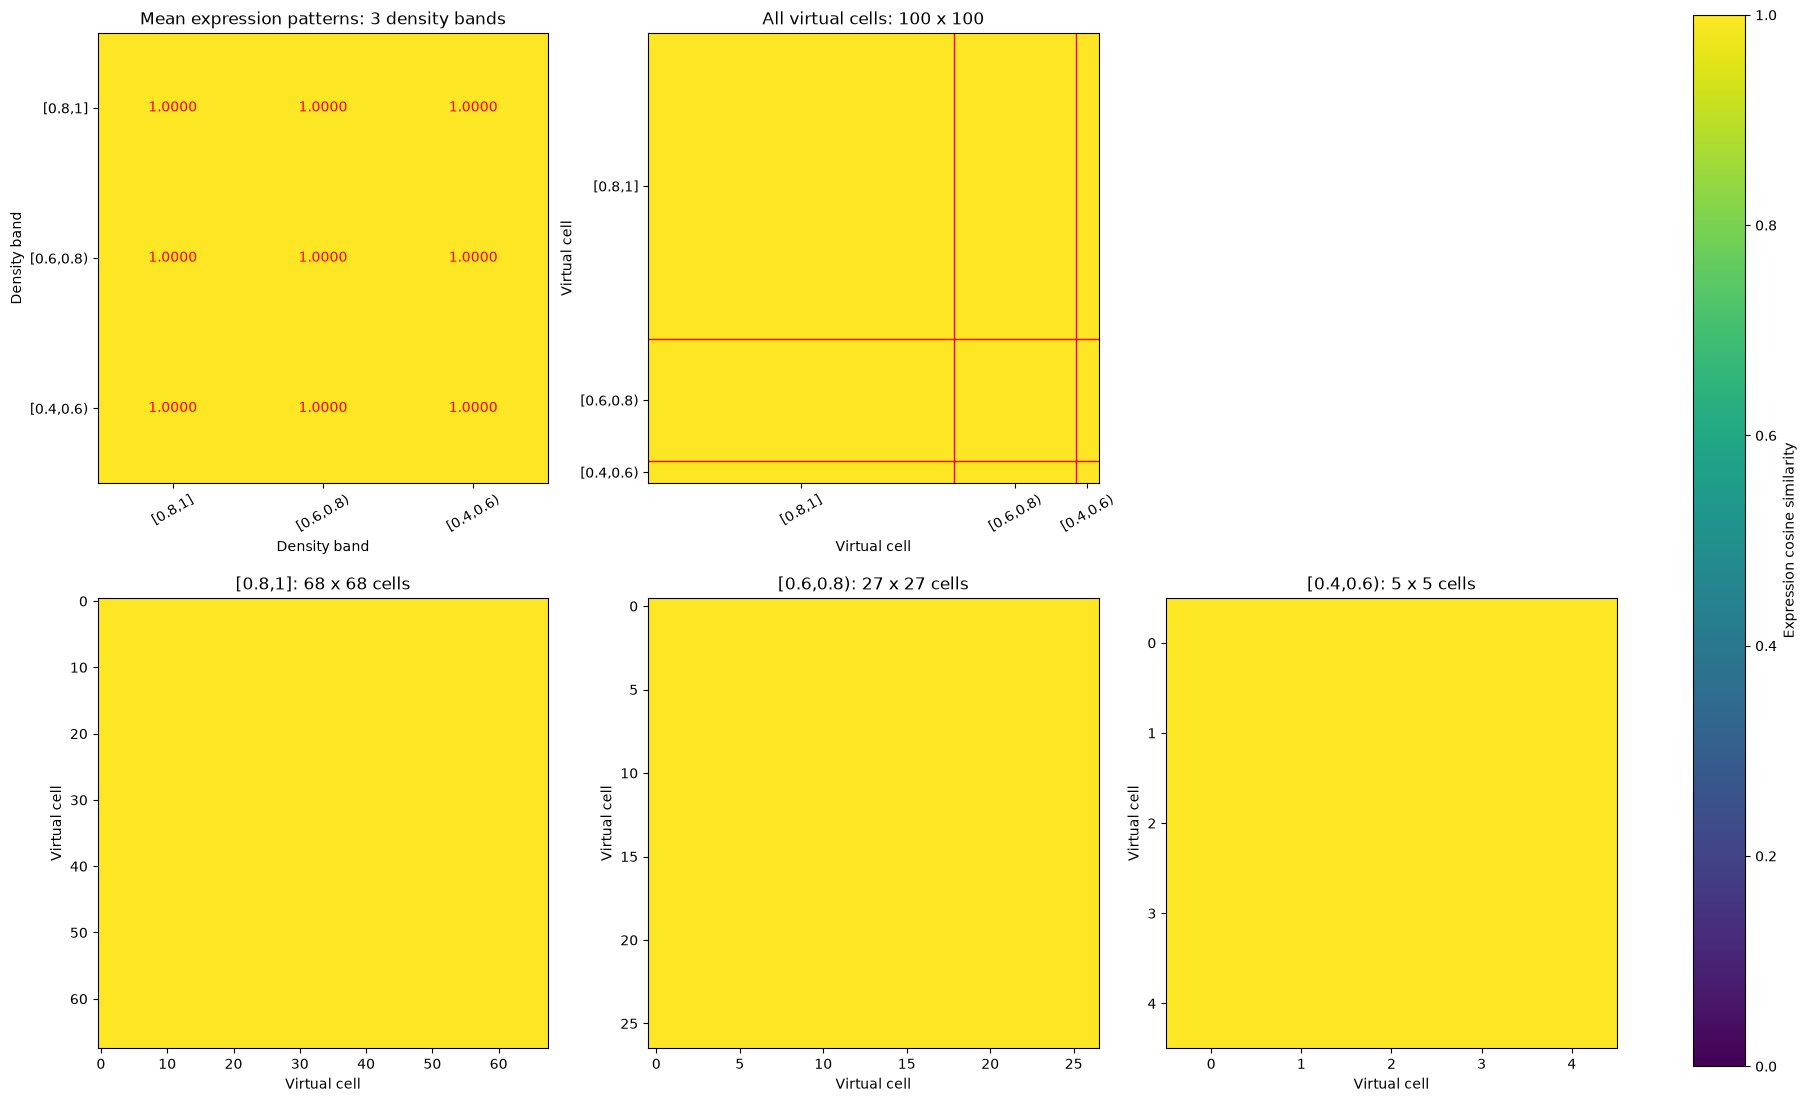

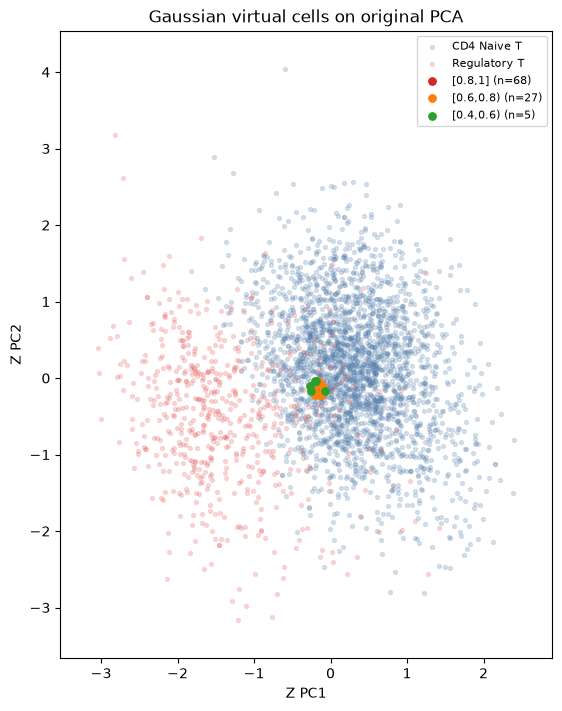

,band,cells,requested_fraction
0,"[0.8,1]",68,0.683
1,"[0.6,0.8)",27,0.271
2,"[0.4,0.6)",5,0.046


Saved 100 Gaussian virtual cells and cosine comparisons to /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/treg_foxp3_only_branch_dqn/gaussian_density_100


In [45]:
from scdqn_gaussian import sample_density_bands, expression_cosines, DENSITY_BANDS, BAND_PROPORTIONS

gs_required = ['lg_sims', 'lg_density', 'lg_x_edges', 'lg_y_edges', 'lg_z_sd', 'lg_pca_mean',
               'lg_components', 'lg_decoder', 'LG_DEVICE', 'LG_DIR', 'lg_symbols', 'lg_completed_reward_version']
gs_missing = [name for name in gs_required if name not in globals()]
if gs_missing:
    raise RuntimeError(f'Run section 14 first; missing state: {gs_missing}')
if lg_completed_reward_version != 'foxp3_decrease_only_small_steps_v1':
    raise RuntimeError('Complete section 14 with the new FOXP3-only reward before sampling.')
GS_TOTAL, GS_SEED, GS_SIGMA_SD = 100, 20261031, 0.03
GS_DIR = LG_DIR / 'gaussian_density_100'
gs_centers = np.concatenate([result['path'][1:] for result in lg_sims])
gs_z, gs_xy, gs_density, gs_band, gs_counts, gs_proposed = sample_density_bands(
    gs_centers, lg_z_sd, lg_pca_mean, lg_components, lg_density, lg_x_edges, lg_y_edges,
    total=GS_TOTAL, sigma_sd=GS_SIGMA_SD, seed=GS_SEED)
with torch.no_grad():
    gs_raw = lg_decoder(torch.tensor(gs_z, dtype=torch.float32, device=LG_DEVICE)).cpu().numpy()
if gs_raw.shape != (GS_TOTAL, len(lg_symbols)) or len(lg_symbols) != 2000 or not np.isfinite(gs_raw).all():
    raise ValueError('Expected finite original VAE decoder output for 100 cells and 2000 genes.')
gs_expression = np.maximum(gs_raw, 0)
gs_means, gs_pattern_cosine, gs_cell_cosine = expression_cosines(gs_expression, gs_band)
gs_band_names = ['[0.8,1]', '[0.6,0.8)', '[0.4,0.6)']
gs_ids = [f'virtual_{i + 1:03d}' for i in range(GS_TOTAL)]
GS_DIR.mkdir(parents=True, exist_ok=True)
gs_table = pd.DataFrame({'sample': gs_ids, 'band': [gs_band_names[b] for b in gs_band],
                         'relative_density': gs_density, 'PC1': gs_xy[:, 0], 'PC2': gs_xy[:, 1],
                         'decoded_FOXP3': gs_expression[:, LG_FOXP3_INDEX]})
gs_table = pd.concat([gs_table, pd.DataFrame(gs_z, columns=[f'Z{i + 1}' for i in range(gs_z.shape[1])])], axis=1)
gs_table.to_csv(GS_DIR / 'virtual_cells.csv', index=False)
pd.DataFrame(gs_expression, index=gs_ids, columns=lg_symbols).to_csv(GS_DIR / 'decoded_expression.csv', index_label='sample')
pd.DataFrame(gs_means, index=gs_band_names, columns=lg_symbols).to_csv(GS_DIR / 'band_mean_expression.csv', index_label='band')
pd.DataFrame(gs_pattern_cosine, index=gs_band_names, columns=gs_band_names).to_csv(GS_DIR / 'band_pattern_cosine.csv', index_label='band')
pd.DataFrame(gs_cell_cosine, index=gs_ids, columns=gs_ids).to_csv(GS_DIR / 'cell_cosine.csv', index_label='sample')
for band in range(3):
    rows = np.flatnonzero(gs_band == band)
    ids = np.asarray(gs_ids)[rows]
    pd.DataFrame(gs_cell_cosine[np.ix_(rows, rows)], index=ids, columns=ids).to_csv(
        GS_DIR / f'band{band + 1}_cell_cosine.csv', index_label='sample')
np.savez_compressed(GS_DIR / 'virtual_cells.npz', latent=gs_z, pca=gs_xy, relative_density=gs_density,
                    band=gs_band, genes=lg_symbols, expression=gs_expression,
                    pattern_cosine=gs_pattern_cosine, cell_cosine=gs_cell_cosine)
(GS_DIR / 'sampling_metadata.json').write_text(json.dumps({
    'reward_version': lg_completed_reward_version, 'total': GS_TOTAL, 'seed': GS_SEED,
    'sigma_observed_sd': GS_SIGMA_SD, 'bands': DENSITY_BANDS, 'proportions': BAND_PROPORTIONS.tolist(),
    'counts': gs_counts.tolist(), 'proposed_candidates': gs_proposed,
    'density': 'section 14 post-start visits, smoothed grid divided by its maximum, not quantiles',
    'projection': 'original section 4 PCA; latent sampling, no inverse transform',
    'gene_count': len(lg_symbols), 'negative_decoder_entries_clipped': int((gs_raw < 0).sum()),
    'comparison': 'density-band mean vectors and virtual-cell pairs; no measured ground truth',
    'interpretation': 'Gaussian neighborhood samples, not monotone DQN actions or causal KO validation'
}, indent=2))

fig, axes = plt.subplots(2, 3, figsize=(18, 11), constrained_layout=True)
gs_images = []
gs_images.append(axes[0, 0].imshow(gs_pattern_cosine, vmin=0, vmax=1, cmap='viridis'))
axes[0, 0].set(title='Mean expression patterns: 3 density bands', xlabel='Density band', ylabel='Density band')
axes[0, 0].set_xticks(range(3), gs_band_names, rotation=30)
axes[0, 0].set_yticks(range(3), gs_band_names)
for row in range(3):
    for col in range(3):
        axes[0, 0].text(col, row, f'{gs_pattern_cosine[row, col]:.4f}', ha='center', va='center', color='red')
gs_images.append(axes[0, 1].imshow(gs_cell_cosine, vmin=0, vmax=1, cmap='viridis'))
axes[0, 1].set(title='All virtual cells: 100 x 100', xlabel='Virtual cell', ylabel='Virtual cell')
gs_midpoints = np.cumsum(gs_counts) - (gs_counts + 1) / 2
axes[0, 1].set_xticks(gs_midpoints, gs_band_names, rotation=30)
axes[0, 1].set_yticks(gs_midpoints, gs_band_names)
for boundary in np.cumsum(gs_counts)[:-1] - 0.5:
    axes[0, 1].axhline(boundary, color='red', lw=1)
    axes[0, 1].axvline(boundary, color='red', lw=1)
for band, ax in enumerate(axes[1]):
    rows = np.flatnonzero(gs_band == band)
    gs_images.append(ax.imshow(gs_cell_cosine[np.ix_(rows, rows)], vmin=0, vmax=1, cmap='viridis'))
    ax.set(title=f'{gs_band_names[band]}: {len(rows)} x {len(rows)} cells', xlabel='Virtual cell', ylabel='Virtual cell')
axes[0, 2].axis('off')
fig.colorbar(gs_images[0], ax=[axes[0, 0], axes[0, 1], *axes[1]], label='Expression cosine similarity')
fig.savefig(GS_DIR / 'density_band_cosine_heatmaps.png', dpi=180, bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
for subtype, color in [('CD4 Naive T', '#4C78A8'), ('Regulatory T', '#E45756')]:
    ax.scatter(*lg_observed_xy[lg_types == subtype].T, s=8, alpha=0.2, c=color, label=subtype)
for band, color in enumerate(['#D62728', '#FF7F0E', '#2CA02C']):
    ax.scatter(*gs_xy[gs_band == band].T, s=28, c=color, label=f'{gs_band_names[band]} (n={gs_counts[band]})')
ax.set(xlabel='Z PC1', ylabel='Z PC2', title='Gaussian virtual cells on original PCA',
       xlim=(lg_x_edges[0], lg_x_edges[-1]), ylim=(lg_y_edges[0], lg_y_edges[-1]))
ax.set_aspect('equal', adjustable='box'); ax.legend(fontsize=8)
fig.savefig(GS_DIR / 'gaussian_cells_pca.png', dpi=180, bbox_inches='tight')
plt.show()
display(pd.DataFrame({'band': gs_band_names, 'cells': gs_counts, 'requested_fraction': BAND_PROPORTIONS}))
print(f'Saved {GS_TOTAL} Gaussian virtual cells and cosine comparisons to {GS_DIR}')

/tmp/ipykernel_895139/406399996.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


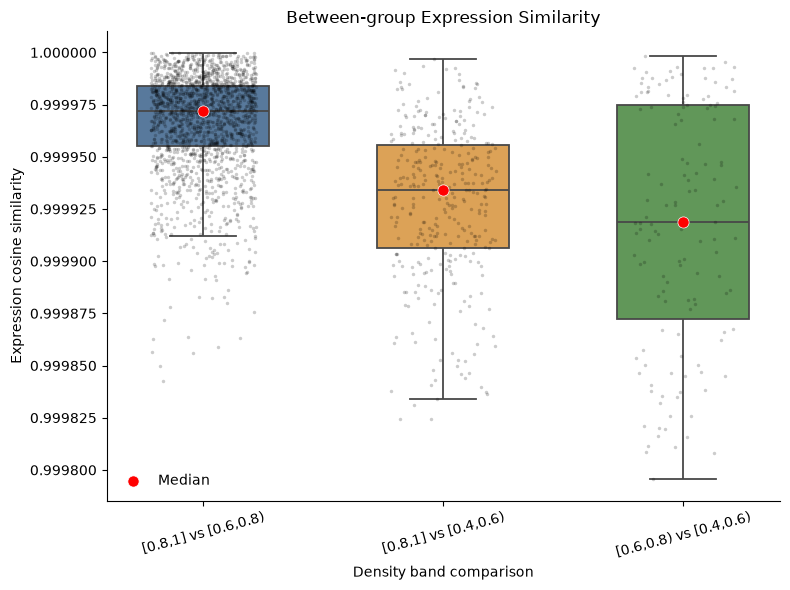

In [57]:
gs_between_df = gs_plot_df[gs_plot_df['type'] == 'Between-group'].copy()

gs_order = [
    f'{gs_band_names[a]} vs {gs_band_names[b]}'
    for a, b in combinations(range(3), 2)
]

gs_palette = ['#4C78A8', '#F2A541', '#59A14F']

fig, ax = plt.subplots(figsize=(8, 6))

sns.boxplot(
    data=gs_between_df,
    x='group',
    y='similarity',
    order=gs_order,
    palette=gs_palette,
    width=0.55,
    showfliers=False,
    linewidth=1.3,
    ax=ax
)

sns.stripplot(
    data=gs_between_df,
    x='group',
    y='similarity',
    order=gs_order,
    color='black',
    alpha=0.2,
    size=2.5,
    jitter=0.22,
    ax=ax
)

gs_medians = gs_between_df.groupby('group')['similarity'].median().reindex(gs_order)

ax.scatter(
    range(len(gs_order)),
    gs_medians.values,
    color='red',
    s=65,
    zorder=10,
    edgecolors='white',
    linewidths=0.5,
    label='Median'
)

ax.set(
    xlabel='Density band comparison',
    ylabel='Expression cosine similarity',
    title='Between-group Expression Similarity'
)

ax.legend(frameon=False)
ax.tick_params(axis='x', rotation=15)
sns.despine()
plt.tight_layout()
plt.show()